# Klasifikasi Aritmia Jantung Berdasarkan Urutan Temporal Fitur Morfologi dan Interval RR Menggunakan LSTM pada MIT-BIH Arrhythmia Database

**Notebook penelitian** — dapat dijalankan dari atas ke bawah di Google Colab.

> **Status notebook ini: BELUM DIEKSEKUSI.** Seluruh angka (jumlah beat, metrik, dsb.) akan dihasilkan oleh kode saat Anda menjalankannya. Tidak ada hasil yang ditulis manual di notebook ini. Interpretasi akhir harus Anda tulis setelah memeriksa output aktual.

## Tujuan penelitian
1. Mengolah sinyal ECG dari MIT-BIH Arrhythmia Database.
2. Mengekstraksi fitur morfologi dan interval RR dari setiap detak jantung.
3. Membentuk urutan temporal (sequence) dari fitur-fitur tersebut.
4. Mengembangkan model LSTM (many-to-one) untuk mengklasifikasikan aritmia (kelas AAMI).
5. Mengevaluasi performa model secara menyeluruh, dengan perhatian khusus pada kelas minoritas.

## Alur singkat
`ECG mentah (.dat/.hea/.atr)` → pilih kanal → bandpass 0,5–40 Hz (zero-phase) → anotasi beat + label AAMI → segmentasi 300 sampel → validasi R-peak (NeuroKit2 vs anotasi) → delineasi P/QRS/T → 9 fitur per beat → sequence 10 beat → split **per pasien** → class weight → LSTM → evaluasi pada test set.

##  Keputusan metodologis yang ditandai `[KONFIRMASI]`
Notebook ini memuat beberapa keputusan yang tidak ditentukan secara eksplisit di spesifikasi dan **perlu Anda konfirmasi**. Semuanya dapat diubah lewat variabel konfigurasi di Bab 1 / Bab 10.

| # | Keputusan | Default | Alasan singkat |
|---|-----------|---------|----------------|
| K1 | Record *paced* (102, 104, 107, 217) | **Dikeluarkan** (`EXCLUDE_PACED_RECORDS=True`) | Praktik standar AAMI/de Chazal; sinyal pacemaker mengganggu morfologi dan kelas Q menjadi sangat jarang |
| K2 | Pembagian data | DS1/DS2 (de Chazal) **dimodifikasi**: rekaman 202 dipindah ke kelompok DS1 | Rekaman 201 dan 202 berasal dari pasien yang sama; DS1/DS2 asli memisahkan keduanya (kebocoran antar-pasien) |
| K3 | Beat dengan gelombang P/T tidak terdeteksi | **Dibuang** (`MISSING_POLICY='drop'`), tanpa imputasi | Sesuai larangan membuat nilai fitur palsu. **Risiko:** beat ventrikuler secara fisiologis sering tidak punya gelombang P, sehingga kelas V bisa berkurang drastis dan bias. Bab 8 menampilkan funnel per kelas untuk menilai hal ini |
| K4 | Beat pertama tiap rekaman (tanpa RR sebelumnya) | Dibuang | Tidak ada nilai RR yang sah |
| K5 | Lokasi beat untuk RR dan segmentasi | Posisi anotasi ahli MIT-BIH | Menghindari propagasi galat detektor otomatis ke label; detektor NeuroKit2 divalidasi terpisah di Bab 6 |
| K6 | Kelas Q | Tetap sebagai kelas ke-5; dilaporkan apa adanya (bisa sangat sedikit/nol di split tertentu) | Tidak mengubah definisi kelas tanpa alasan metodologis |
| K7 | Baseline amplitudo | Median segmen 300 sampel per beat | Robust terhadap puncak QRS; dijelaskan di Bab 8 |

## Struktur notebook
1 Persiapan lingkungan · 2 Eksplorasi dataset · 3 Preprocessing · 4 Anotasi & label AAMI · 5 Segmentasi · 6 Validasi R-peak · 7 Delineasi · 8 Ekstraksi fitur · 9 Dataset sequence · 10 Split per pasien · 11 Class imbalance · 12 Model LSTM · 13 Training · 14 Evaluasi · 15 Eksperimen tambahan · 16 Kesimpulan & penyimpanan.

---
# BAB 1 — PERSIAPAN LINGKUNGAN

Bab ini memasang dan mengimpor library, menetapkan *random seed* untuk reprodusibilitas, mendefinisikan **seluruh konfigurasi di satu tempat**, lalu menyiapkan dan memeriksa dataset.

**Cara menjalankan di Google Colab**
1. Unggah notebook ini ke Colab (File → Upload notebook).
2. *(Disarankan)* Runtime → Change runtime type → **GPU** (T4) untuk mempercepat training LSTM.
3. Jalankan sel dari atas ke bawah (Runtime → Run all, atau per sel agar hasil tiap tahap bisa diperiksa).
4. Pilih sumber data di sel konfigurasi (`DATA_SOURCE`): `'download'`, `'upload'`, atau `'existing'`.

Library `wfdb` dan `neurokit2` dipasang otomatis bila belum ada.

In [ ]:
# 1.1 Instalasi library yang belum tersedia (Colab sudah memiliki numpy, pandas, scipy, sklearn, tensorflow, seaborn)
import importlib.util, subprocess, sys

REQUIRED = {'wfdb': 'wfdb', 'neurokit2': 'neurokit2'}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Memasang:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
else:
    print('Semua library tambahan sudah terpasang.')

Memasang: ['wfdb', 'neurokit2']


In [ ]:
# 1.2 Import library, random seed, dan pemeriksaan versi
import os, time, json, random, shutil, zipfile, platform, warnings, itertools
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import scipy.signal as sps
import scipy.stats as spstats
from numpy.lib.stride_tricks import sliding_window_view

import wfdb
import neurokit2 as nk

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix,
                             classification_report, balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef)
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ---- Random seed (reprodusibilitas) ----
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)          # mengatur seed python, numpy, dan TensorFlow sekaligus
DETERMINISTIC_OPS = False                  # True = lebih deterministik di GPU, tetapi bisa lebih lambat
if DETERMINISTIC_OPS:
    tf.config.experimental.enable_op_determinism()

# ---- Tampilan ----
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
sns.set_context('notebook')

# ---- Pemeriksaan versi dan dependensi ----
versions = {
    'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
    'scipy': scipy.__version__, 'matplotlib': plt.matplotlib.__version__, 'seaborn': sns.__version__,
    'scikit-learn': sklearn.__version__, 'wfdb': wfdb.__version__, 'neurokit2': nk.__version__,
    'tensorflow': tf.__version__, 'keras': keras.__version__,
}
display(pd.Series(versions, name='versi').to_frame())
print('GPU terdeteksi :', tf.config.list_physical_devices('GPU') or 'tidak ada (training memakai CPU)')
print('Seluruh dependensi berhasil diimpor.')

,versi
python,3.13.18
numpy,2.4.6
pandas,2.2.3
scipy,1.16.3
matplotlib,3.10.0
seaborn,0.13.2
scikit-learn,1.6.1
wfdb,4.3.1
neurokit2,0.3.0
tensorflow,2.21.0


GPU terdeteksi : tidak ada (training memakai CPU)
Seluruh dependensi berhasil diimpor.


In [ ]:
# 1.3 KONFIGURASI PUSAT — ubah nilai di sini bila diperlukan
IN_COLAB = 'google.colab' in sys.modules
BASE_DIR = Path('/content') if IN_COLAB else Path('.').resolve()
DATA_DIR = BASE_DIR / 'mitdb'                 # lokasi file .dat/.hea/.atr
WORK_DIR = BASE_DIR / 'work_mitdb'            # cache antara (sinyal terfilter, segmen, delineasi)
OUT_DIR = BASE_DIR / 'output_mitdb'           # keluaran akhir
for d in (DATA_DIR, WORK_DIR / 'filtered', WORK_DIR / 'segments', WORK_DIR / 'delineation', OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- Sumber data ----
DATA_SOURCE = 'download'     # 'download' = unduh dari PhysioNet | 'upload' = unggah ZIP manual | 'existing' = file sudah ada di DATA_DIR
ZIP_PATH = None              # opsional: path ZIP (mis. di Google Drive) untuk DATA_SOURCE='upload' tanpa dialog unggah

# ---- Daftar 48 rekaman MIT-BIH ----
RECORDS = ['100','101','102','103','104','105','106','107','108','109',
           '111','112','113','114','115','116','117','118','119',
           '121','122','123','124',
           '200','201','202','203','205','207','208','209','210',
           '212','213','214','215','217','219','220','221','222','223',
           '228','230','231','232','233','234']
FS = 360                      # frekuensi sampling MIT-BIH (Hz)

# ---- Preprocessing ----
BAND_HZ = (0.5, 40.0)
FILTER_ORDER = 4              # orde Butterworth (efektif 2x karena filtfilt dua arah)

# ---- Segmentasi ----
PRE, POST = 100, 200          # sampel sebelum/sesudah anotasi
SEG_LEN = PRE + POST

# ---- Validasi R-peak ----
TOL_MS = 150
RPEAK_METHOD = 'neurokit'
ADEQUATE_F1 = 0.99            # ambang kecukupan detektor (kriteria internal, dapat diubah)
RUN_ALT_DETECTORS = True      # bandingkan detektor lain pada rekaman tersulit

# ---- Delineasi dan validitas fitur ----
DELINEATE_METHOD = 'dwt'      # hanya 'dwt': metode 'peak' NeuroKit2 tidak menghasilkan onset/offset QRS yang dibutuhkan fitur QRS_duration
R_SEARCH_MS = 50              # jendela pencarian puncak R dari posisi anotasi
QRS_MIN_MS, QRS_MAX_MS = 40, 250
P_MAX_BEFORE_R_MS = 400
T_MAX_AFTER_R_MS = 600
REUSE_CACHE = True            # True = pakai cache delineasi di WORK_DIR bila ada. HAPUS folder work_mitdb bila data/parameter preprocessing berubah

# ---- Kelas dan data ----
CLASS_NAMES = ['N', 'S', 'V', 'F', 'Q']
LABEL_MAP = {c: i for i, c in enumerate(CLASS_NAMES)}
N_CLASSES = len(CLASS_NAMES)
PACED_RECORDS = ['102', '104', '107', '217']
EXCLUDE_PACED_RECORDS = True  # [K1] KONFIRMASI
MISSING_POLICY = 'drop'       # [K3] KONFIRMASI: 'drop' (default, tanpa imputasi) atau 'indicator' (lihat Bab 8)

# ---- Sequence dan model ----
SEQ_LEN = 10
BATCH_SIZE = 256
MAX_EPOCHS = 60
PATIENCE = 8

print('Colab:', IN_COLAB, '| DATA_DIR:', DATA_DIR)
print('Jumlah record terdaftar:', len(RECORDS), '| unik:', len(set(RECORDS)))

Colab: True | DATA_DIR: /content/mitdb
Jumlah record terdaftar: 48 | unik: 48


In [ ]:
# 1.4 Menyiapkan dataset: unduh dari PhysioNet ATAU unggah ZIP manual
def download_mitdb():
    # Mengunduh .dat/.hea/.atr dari PhysioNet (memerlukan internet).
    wfdb.dl_database('mitdb', dl_dir=str(DATA_DIR), records=RECORDS)

def extract_zip(zip_path):
    # Mengekstrak hanya .dat/.hea/.atr dari ZIP ke DATA_DIR (struktur folder di dalam ZIP diratakan).
    n = 0
    with zipfile.ZipFile(zip_path) as zf:
        for member in zf.namelist():
            name = Path(member).name
            if name.endswith(('.dat', '.hea', '.atr')):
                with zf.open(member) as src, open(DATA_DIR / name, 'wb') as dst:
                    shutil.copyfileobj(src, dst)
                n += 1
    print(f'{n} file diekstrak ke {DATA_DIR}')

def prepare_dataset():
    if DATA_SOURCE == 'download':
        print('Mengunduh dari PhysioNet ... (beberapa menit)')
        download_mitdb()
    elif DATA_SOURCE == 'upload':
        zp = ZIP_PATH
        if zp is None:
            if not IN_COLAB:
                raise RuntimeError('Di luar Colab, isi ZIP_PATH dengan path file ZIP.')
            from google.colab import files
            uploaded = files.upload()
            zp = next(iter(uploaded))
        extract_zip(zp)
    elif DATA_SOURCE == 'existing':
        print('Memakai file yang sudah ada di', DATA_DIR)
    else:
        raise ValueError("DATA_SOURCE harus 'download', 'upload', atau 'existing'")

# Lewati unduhan bila seluruh file sudah lengkap (hemat waktu saat sel dijalankan ulang)
def files_complete():
    return all((DATA_DIR / f'{r}.{e}').exists() and (DATA_DIR / f'{r}.{e}').stat().st_size > 0
               for r in RECORDS for e in ('dat', 'hea', 'atr'))

if files_complete():
    print('Seluruh file sudah lengkap di', DATA_DIR, '- tahap unduh/unggah dilewati.')
else:
    prepare_dataset()

Mengunduh dari PhysioNet ... (beberapa menit)
Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for

In [ ]:
# 1.5 Pemeriksaan keberadaan seluruh file yang diperlukan
rows = []
for r in RECORDS:
    row = {'Record': r}
    for e in ('dat', 'hea', 'atr'):
        p = DATA_DIR / f'{r}.{e}'
        row[e] = p.exists() and p.stat().st_size > 0
    rows.append(row)
file_check = pd.DataFrame(rows).set_index('Record')
n_missing = int((~file_check).sum().sum())
print(f'Record diperiksa: {len(file_check)} | file hilang/kosong: {n_missing}')
if n_missing:
    display(file_check[~file_check.all(axis=1)])
    raise FileNotFoundError('Ada file yang hilang. Perbaiki sumber data (lihat DATA_SOURCE) lalu jalankan ulang sel 1.4.')
print('OK: seluruh file .dat, .hea, dan .atr tersedia.')

Record diperiksa: 48 | file hilang/kosong: 0
OK: seluruh file .dat, .hea, dan .atr tersedia.


---
# BAB 2 — EKSPLORASI DATASET

Tahap ini hanya membaca **header** dan jumlah anotasi (bukan seluruh sinyal) agar hemat memori.

**Karakteristik MIT-BIH Arrhythmia Database (rujukan literatur)**: 48 rekaman ECG ambulatori sekitar 30 menit (650.000 sampel pada 360 Hz) dari 47 subjek (rekaman 201 dan 202 berasal dari subjek yang sama), resolusi 11 bit pada rentang ±5 mV. Setiap rekaman umumnya memiliki dua kanal; mayoritas MLII (modified limb lead II) + satu kanal prekordial (V1/V2/V4/V5), tetapi **rekaman 102 dan 104 tidak memiliki MLII**, dan pada rekaman 114 urutan kanal terbalik (jadi kanal harus dipilih **berdasarkan nama**, bukan indeks). Rekaman 102, 104, 107, 217 memiliki irama *paced*. Setiap beat dianotasi oleh dua kardiolog atau lebih. Pemeriksaan di bawah memverifikasi (bukan sekadar mengasumsikan) sifat-sifat tersebut pada file yang Anda gunakan.

In [ ]:
# 2.1 Ringkasan dataset dari header
rows = []
for r in RECORDS:
    h = wfdb.rdheader(str(DATA_DIR / r))
    a = wfdb.rdann(str(DATA_DIR / r), 'atr')
    rows.append(dict(Record=r, fs=h.fs, n_sig=h.n_sig, sig_names=','.join(h.sig_name), sig_len=h.sig_len,
                     duration_min=h.sig_len / h.fs / 60, units=','.join(h.units),
                     n_annotations=len(a.sample), has_MLII='MLII' in h.sig_name, paced=r in PACED_RECORDS))
dataset_summary = pd.DataFrame(rows).set_index('Record')
display(dataset_summary)

print('Jumlah record               :', len(dataset_summary))
print('Frekuensi sampling unik (Hz):', sorted(dataset_summary.fs.unique()))
print('Jumlah kanal unik           :', sorted(dataset_summary.n_sig.unique()))
print('Nama kanal (kombinasi)      :', dataset_summary.sig_names.value_counts().to_dict())
print('Panjang sinyal min/maks     :', dataset_summary.sig_len.min(), dataset_summary.sig_len.max())
print('Record tanpa MLII           :', dataset_summary.index[~dataset_summary.has_MLII].tolist())
print('Total anotasi (semua simbol):', int(dataset_summary.n_annotations.sum()))

if not (dataset_summary.fs == FS).all():
    raise ValueError(f'Ada record dengan fs != {FS} Hz. Parameter filter dan segmentasi harus disesuaikan.')
print('OK: seluruh record memiliki fs =', FS, 'Hz')

,fs,n_sig,sig_names,sig_len,duration_min,units,n_annotations,has_MLII,paced
Record,,,,,,,,,
100,360,2,"MLII,V5",650000,30.0926,"mV,mV",2274,True,False
101,360,2,"MLII,V1",650000,30.0926,"mV,mV",1874,True,False
102,360,2,"V5,V2",650000,30.0926,"mV,mV",2192,False,True
103,360,2,"MLII,V2",650000,30.0926,"mV,mV",2091,True,False
104,360,2,"V5,V2",650000,30.0926,"mV,mV",2311,False,True
105,360,2,"MLII,V1",650000,30.0926,"mV,mV",2691,True,False
106,360,2,"MLII,V1",650000,30.0926,"mV,mV",2098,True,False
107,360,2,"MLII,V1",650000,30.0926,"mV,mV",2140,True,True
108,360,2,"MLII,V1",650000,30.0926,"mV,mV",1824,True,False


Jumlah record               : 48
Frekuensi sampling unik (Hz): [np.int64(360)]
Jumlah kanal unik           : [np.int64(2)]
Nama kanal (kombinasi)      : {'MLII,V1': 40, 'MLII,V5': 2, 'V5,V2': 2, 'MLII,V2': 2, 'V5,MLII': 1, 'MLII,V4': 1}
Panjang sinyal min/maks     : 650000 650000
Record tanpa MLII           : ['102', '104']
Total anotasi (semua simbol): 112647
OK: seluruh record memiliki fs = 360 Hz


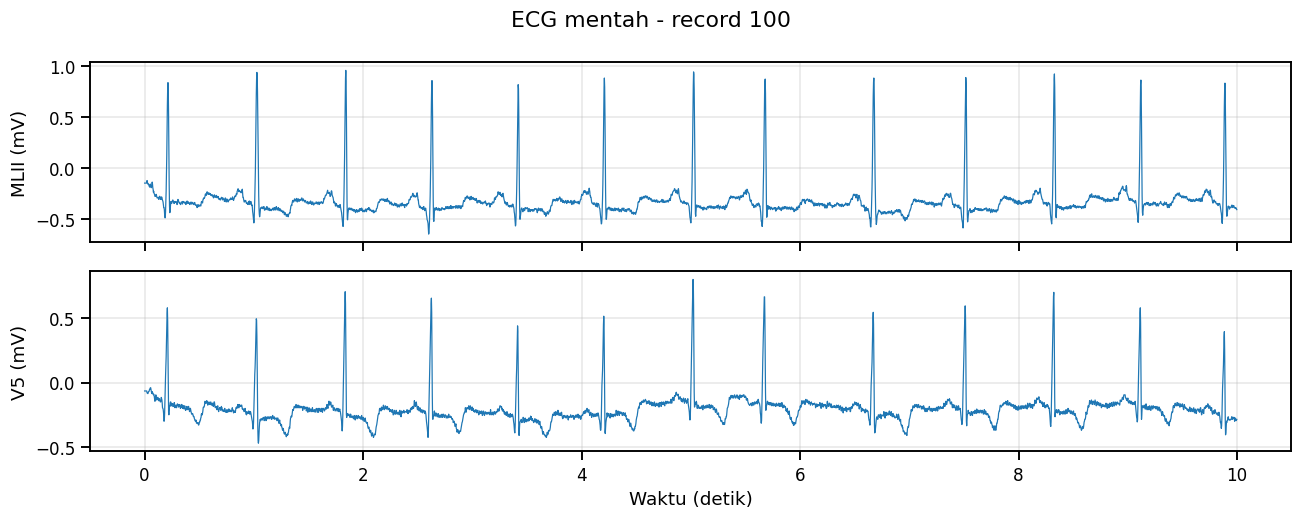

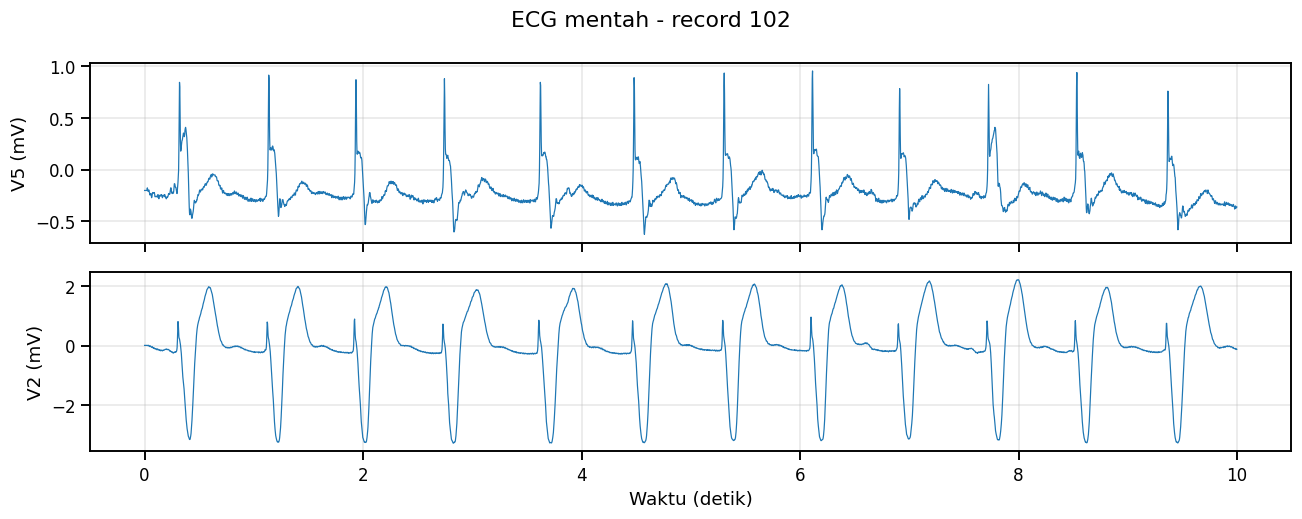

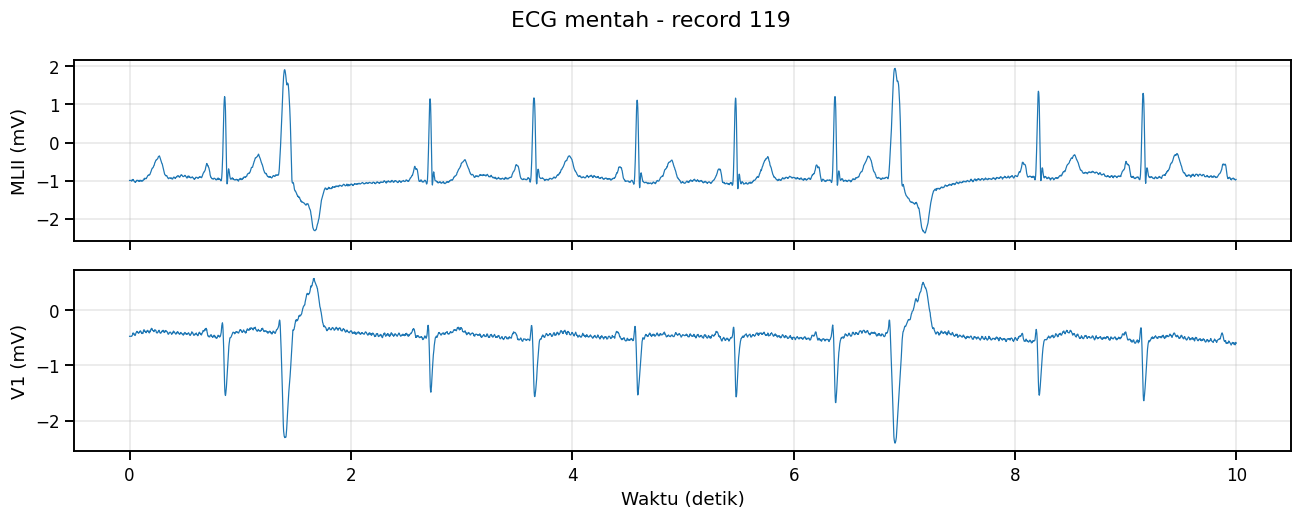

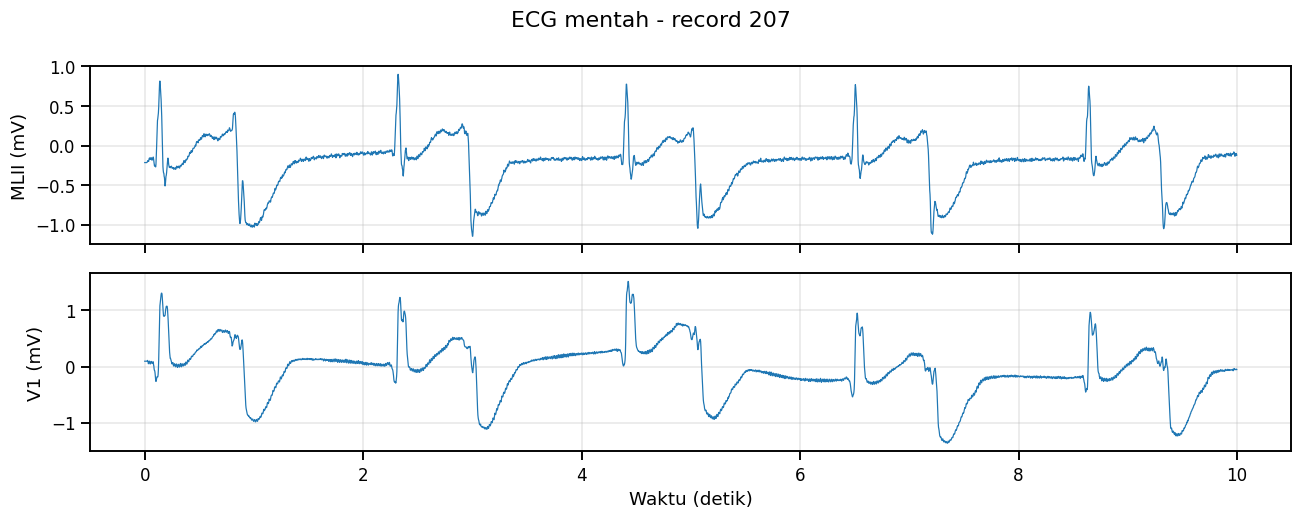

In [ ]:
# 2.2 Visualisasi contoh sinyal ECG mentah (10 detik pertama)
def plot_raw_example(rec, seconds=10):
    sig = wfdb.rdrecord(str(DATA_DIR / rec), sampfrom=0, sampto=int(seconds * FS))
    t = np.arange(sig.p_signal.shape[0]) / FS
    fig, axes = plt.subplots(sig.n_sig, 1, figsize=(12, 2.4 * sig.n_sig), sharex=True)
    axes = np.atleast_1d(axes)
    for k, ax in enumerate(axes):
        ax.plot(t, sig.p_signal[:, k], lw=0.8)
        ax.set_ylabel(f'{sig.sig_name[k]} ({sig.units[k]})')
    axes[-1].set_xlabel('Waktu (detik)')
    fig.suptitle(f'ECG mentah - record {rec}')
    plt.tight_layout(); plt.show()

demo_records = [r for r in ('100', '102', '119', '207') if r in RECORDS] or RECORDS[:2]
for r in demo_records:
    plot_raw_example(r)

**Catatan karakteristik yang perlu diperhatikan dari hasil di atas** (verifikasi sendiri dengan output): amplitudo dan morfologi berbeda antar kanal dan antar pasien; terdapat *baseline wander* dan derau otot pada sebagian rekaman; rekaman 102 menunjukkan kanal tanpa MLII. Karena itu, amplitudo dari kanal berbeda **tidak boleh dianggap setara** (lihat Bab 3 dan 8).

---
# BAB 3 — PREPROCESSING ECG

**1. Pemilihan kanal.** Prioritas: `MLII`. Bila tidak tersedia (record 102 dan 104), dipakai kanal alternatif dengan urutan prioritas `V5 → V2 → V1 → V4` (V5 dipilih lebih dulu karena orientasinya paling mendekati MLII di antara kanal prekordial yang tersedia; ini **asumsi** yang dicatat). Kanal yang dipakai dicatat per record. Karena kanal berbeda memiliki karakteristik amplitudo berbeda, fitur amplitudo **tidak dinormalisasi lintas-kanal secara diam-diam**; kolom `lead` disimpan di tabel fitur, dan bila record non-MLII tidak dikeluarkan, ini menjadi keterbatasan yang harus dilaporkan. Dengan default `EXCLUDE_PACED_RECORDS=True`, record 102 dan 104 (satu-satunya yang tanpa MLII) tidak ikut dalam pemodelan sehingga seluruh data pemodelan berasal dari MLII.

**2. Bandpass Butterworth 0,5–40 Hz** pada 360 Hz, bentuk *second-order sections* (`sos`, stabil secara numerik). Filter diterapkan dua arah dengan `sosfiltfilt` sehingga **fase nol (tidak ada pergeseran fase/waktu)** — penting agar posisi puncak R tidak bergeser relatif terhadap anotasi. Konsekuensi: respons magnitudo efektif adalah kuadrat respons satu arah (redaman lebih curam, *ripple* pita-lolos lebih dari satu arah), dan filter non-kausal (hanya cocok untuk analisis *offline* seperti ini).

**3–4. Visualisasi dan validasi** (NaN, Inf, sinyal kosong, panjang sinyal), kegagalan dicatat di tabel.

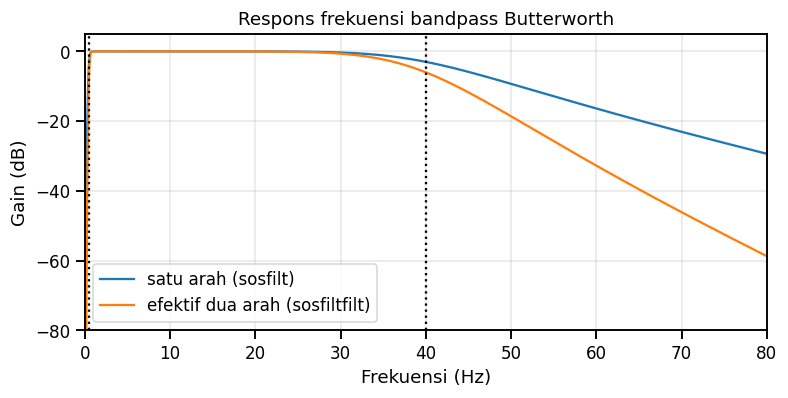

Lag korelasi silang sinus 10 Hz setelah filtfilt: 0 sampel (harus 0)


In [ ]:
# 3.1 Fungsi pemilihan kanal dan desain filter
CHANNEL_PRIORITY = ['MLII', 'V5', 'V2', 'V1', 'V4']

def select_channel(sig_names):
    for name in CHANNEL_PRIORITY:
        if name in sig_names:
            return sig_names.index(name), name
    return 0, sig_names[0]          # cadangan terakhir: kanal pertama (dicatat di tabel)

SOS = sps.butter(FILTER_ORDER, BAND_HZ, btype='bandpass', fs=FS, output='sos')

def bandpass_zero_phase(x):
    return sps.sosfiltfilt(SOS, x)

# Validasi filter: respons frekuensi (satu arah vs efektif dua arah) dan uji fase nol
w, h = sps.sosfreqz(SOS, worN=4096, fs=FS)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(w, 20 * np.log10(np.abs(h) + 1e-12), label='satu arah (sosfilt)')
ax.plot(w, 40 * np.log10(np.abs(h) + 1e-12), label='efektif dua arah (sosfiltfilt)')
ax.axvline(BAND_HZ[0], color='k', ls=':'); ax.axvline(BAND_HZ[1], color='k', ls=':')
ax.set_xlim(0, 80); ax.set_ylim(-80, 5); ax.set_xlabel('Frekuensi (Hz)'); ax.set_ylabel('Gain (dB)')
ax.set_title('Respons frekuensi bandpass Butterworth'); ax.legend(); plt.show()

# Uji fase nol: sinus 10 Hz harus tidak bergeser setelah filtfilt (lag korelasi silang = 0)
t = np.arange(0, 10, 1 / FS)
test_sig = np.sin(2 * np.pi * 10 * t)
filt_sig = bandpass_zero_phase(test_sig)
mid = slice(FS, -FS)                                     # abaikan efek tepi
xc = sps.correlate(filt_sig[mid], test_sig[mid], mode='full')
lag = np.argmax(xc) - (len(test_sig[mid]) - 1)
print(f'Lag korelasi silang sinus 10 Hz setelah filtfilt: {lag} sampel (harus 0)')
assert lag == 0, 'Filter menggeser fase - periksa implementasi'

In [ ]:
# 3.2 Preprocessing seluruh record secara bertahap (satu record per iterasi, hasil disimpan ke disk)
def validate_signal(x, name):
    return dict(**{f'{name}_n': int(x.size), f'{name}_nan': int(np.isnan(x).sum()),
                   f'{name}_inf': int(np.isinf(x).sum()), f'{name}_empty': bool(x.size == 0),
                   f'{name}_std': float(np.nanstd(x)) if x.size else np.nan})

prep_rows = []
for r in RECORDS:
    out_path = WORK_DIR / 'filtered' / f'{r}.npy'
    h = wfdb.rdheader(str(DATA_DIR / r))
    ch_idx, ch_name = select_channel(h.sig_name)
    rec = wfdb.rdrecord(str(DATA_DIR / r), channels=[ch_idx])
    raw = rec.p_signal[:, 0].astype(np.float64)
    row = dict(Record=r, channel=ch_name, channel_idx=ch_idx, units=rec.units[0], expected_len=h.sig_len)
    row.update(validate_signal(raw, 'raw'))
    status = 'OK'
    if raw.size == 0 or np.isnan(raw).any() or np.isinf(raw).any():
        status = 'GAGAL: sinyal mentah kosong/NaN/Inf'
        filt = np.full_like(raw, np.nan)
    else:
        filt = bandpass_zero_phase(raw)
    row.update(validate_signal(filt, 'filt'))
    if status == 'OK' and (filt.size != h.sig_len or np.isnan(filt).any() or np.isinf(filt).any()):
        status = 'GAGAL: sinyal terfilter tidak valid'
    row['status'] = status
    if status == 'OK':
        np.save(out_path, filt.astype(np.float32))
    prep_rows.append(row)
    del raw, filt

prep_log = pd.DataFrame(prep_rows).set_index('Record')
display(prep_log[['channel', 'units', 'expected_len', 'raw_n', 'raw_nan', 'raw_inf', 'filt_nan', 'filt_inf', 'raw_std', 'filt_std', 'status']])
print('Kanal yang digunakan:', prep_log.channel.value_counts().to_dict())
failed = prep_log[prep_log.status != 'OK']
print('Record gagal preprocessing:', failed.index.tolist() or 'tidak ada')
if len(failed):
    raise RuntimeError('Preprocessing gagal untuk record di atas. Periksa file sumber (lihat kolom status).')

,channel,units,expected_len,raw_n,raw_nan,raw_inf,filt_nan,filt_inf,raw_std,filt_std,status
Record,,,,,,,,,,,
100,MLII,mV,650000,650000,0,0,0,0,0.1932,0.1830,OK
101,MLII,mV,650000,650000,0,0,0,0,0.2612,0.2273,OK
102,V5,mV,650000,650000,0,0,0,0,0.1905,0.1793,OK
103,MLII,mV,650000,650000,0,0,0,0,0.3218,0.2980,OK
104,V5,mV,650000,650000,0,0,0,0,0.2504,0.2311,OK
105,MLII,mV,650000,650000,0,0,0,0,0.4051,0.3655,OK
106,MLII,mV,650000,650000,0,0,0,0,0.3681,0.3501,OK
107,MLII,mV,650000,650000,0,0,0,0,0.8580,0.8197,OK
108,MLII,mV,650000,650000,0,0,0,0,0.3008,0.1735,OK


Kanal yang digunakan: {'MLII': 46, 'V5': 2}
Record gagal preprocessing: tidak ada


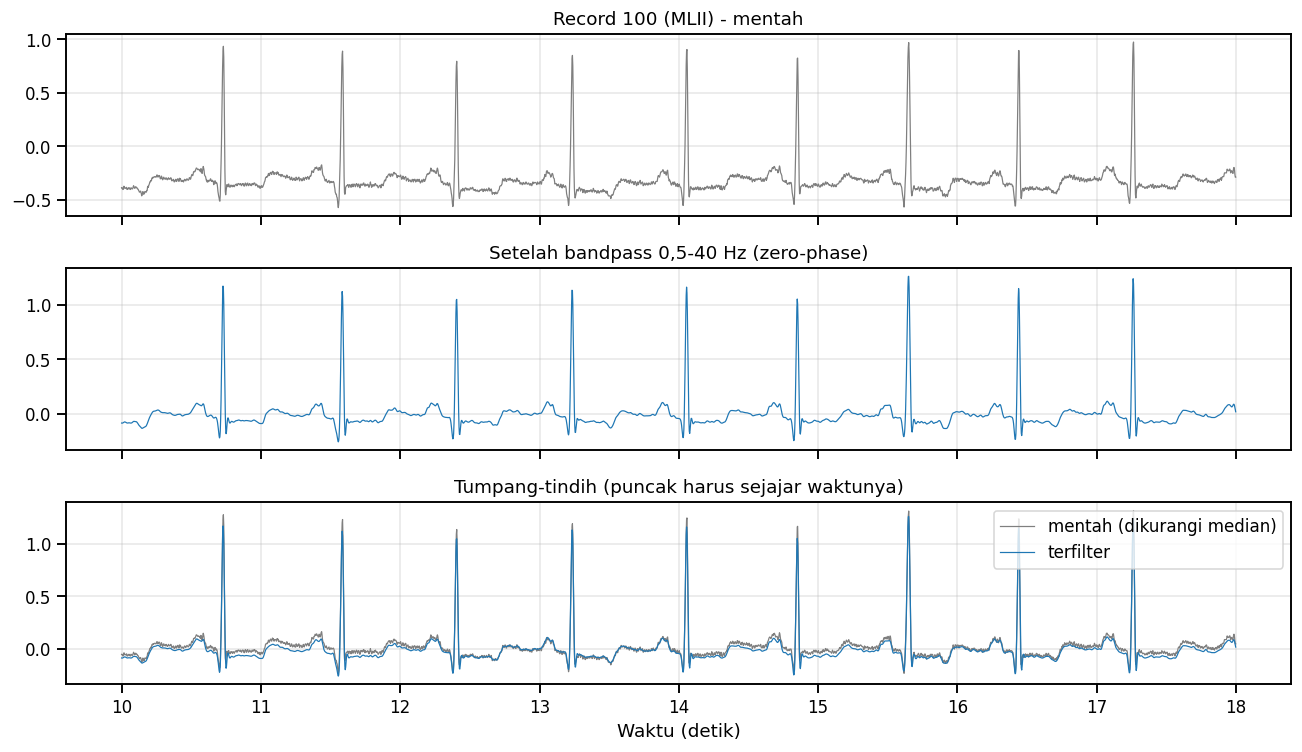

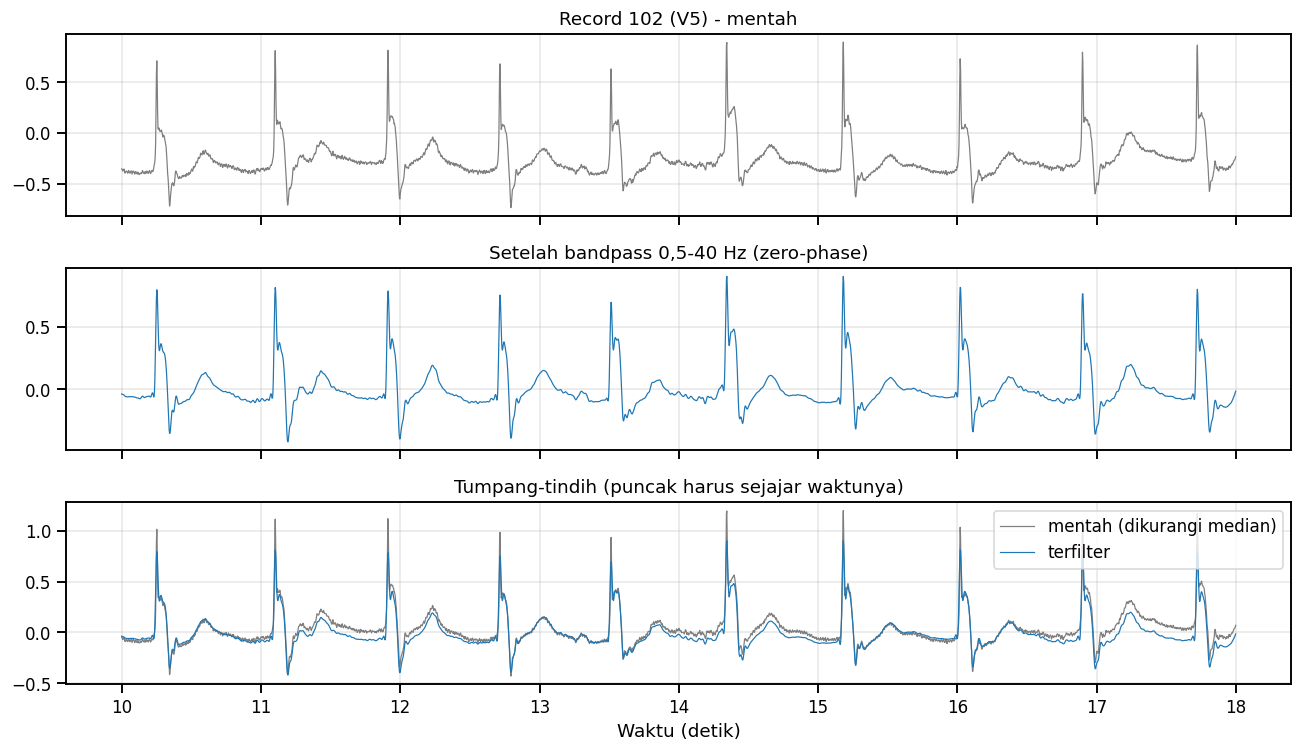

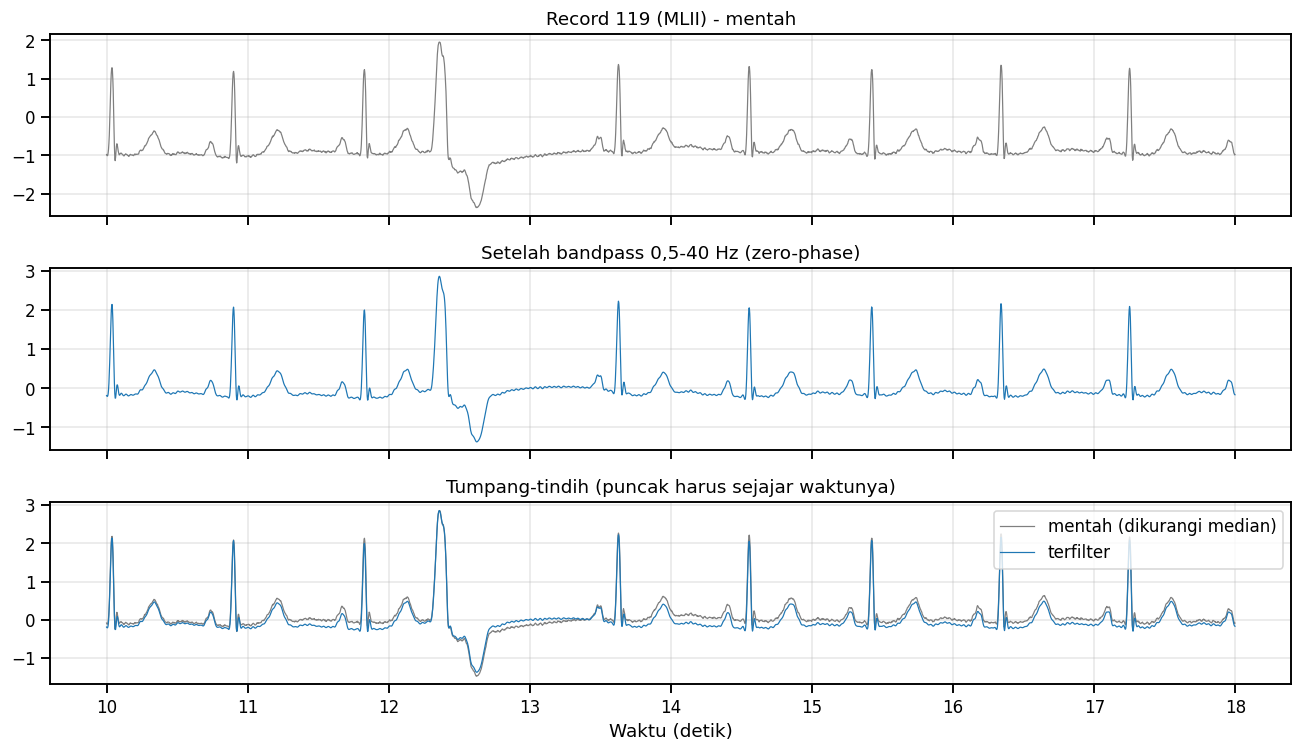

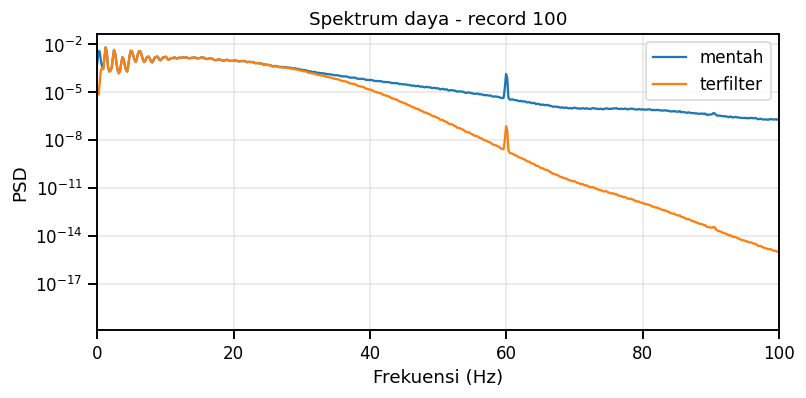

In [ ]:
# 3.3 Visualisasi sebelum vs sesudah filtering
def plot_before_after(rec, start_s=10, dur_s=8):
    h = wfdb.rdheader(str(DATA_DIR / rec))
    ch_idx, ch_name = select_channel(h.sig_name)
    a, b = int(start_s * FS), int((start_s + dur_s) * FS)
    raw = wfdb.rdrecord(str(DATA_DIR / rec), sampfrom=0, sampto=b + FS, channels=[ch_idx]).p_signal[:, 0]
    filt = np.load(WORK_DIR / 'filtered' / f'{rec}.npy')
    t = np.arange(a, b) / FS
    fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
    axes[0].plot(t, raw[a:b], lw=0.8, color='tab:gray'); axes[0].set_title(f'Record {rec} ({ch_name}) - mentah')
    axes[1].plot(t, filt[a:b], lw=0.8, color='tab:blue'); axes[1].set_title('Setelah bandpass 0,5-40 Hz (zero-phase)')
    axes[2].plot(t, raw[a:b] - np.median(raw[a:b]), lw=0.8, color='tab:gray', label='mentah (dikurangi median)')
    axes[2].plot(t, filt[a:b], lw=0.8, color='tab:blue', label='terfilter'); axes[2].legend(loc='upper right')
    axes[2].set_title('Tumpang-tindih (puncak harus sejajar waktunya)'); axes[2].set_xlabel('Waktu (detik)')
    plt.tight_layout(); plt.show()

for r in demo_records[:3]:
    plot_before_after(r)

# Perbandingan spektrum daya (Welch) pada satu record
r0 = demo_records[0]
h0 = wfdb.rdheader(str(DATA_DIR / r0)); ci0, _ = select_channel(h0.sig_name)
raw0 = wfdb.rdrecord(str(DATA_DIR / r0), channels=[ci0]).p_signal[:, 0]
filt0 = np.load(WORK_DIR / 'filtered' / f'{r0}.npy')
f1_, p1_ = sps.welch(raw0, FS, nperseg=2048); f2_, p2_ = sps.welch(filt0, FS, nperseg=2048)
plt.figure(figsize=(8, 3.5)); plt.semilogy(f1_, p1_, label='mentah'); plt.semilogy(f2_, p2_, label='terfilter')
plt.xlim(0, 100); plt.xlabel('Frekuensi (Hz)'); plt.ylabel('PSD'); plt.title(f'Spektrum daya - record {r0}'); plt.legend(); plt.show()
del raw0, filt0

**Pemeriksaan hasil Bab 3.** Pastikan: (i) tidak ada record gagal pada tabel 3.2, (ii) lag fase = 0, (iii) pada grafik tumpang-tindih puncak QRS sejajar, (iv) *baseline wander* berkurang tanpa mengubah bentuk QRS secara berarti. Perhatikan bahwa batas atas 40 Hz dapat sedikit meredam puncak QRS yang sangat tajam sehingga amplitudo R sedikit lebih rendah dari sinyal mentah — ini keterbatasan yang melekat pada konfigurasi awal 0,5–40 Hz sesuai spesifikasi.

---
# BAB 4 — PEMROSESAN ANOTASI DAN LABEL AAMI

File `.atr` berisi **semua** anotasi (beat dan non-beat: perubahan irama, kualitas sinyal, dsb.). Hanya anotasi beat yang dipakai sebagai detak jantung.

**Pemetaan AAMI EC57 yang digunakan**

| Kelas AAMI | Simbol MIT-BIH |
|---|---|
| **N** (normal & bundle branch block, escape) | `N`, `L`, `R`, `e`, `j` |
| **S** (supraventricular ectopic) | `A`, `a`, `J`, `S` |
| **V** (ventricular ectopic) | `V`, `E` |
| **F** (fusion) | `F` |
| **Q** (unknown / paced) | `/`, `f`, `Q` |

Simbol beat WFDB lain (`B`, `r`, `n`, `?`) **tidak muncul** di MIT-BIH dan tidak diberi pemetaan sembarangan; bila ternyata muncul, notebook akan berhenti agar Anda memutuskan pemetaannya. Simbol yang tidak termasuk beat maupun non-beat yang dikenal juga menghentikan eksekusi (bukan diabaikan diam-diam).

**Keputusan kelas Q dan paced beat `[K1]`** — Kelas Q berisi beat paced (`/`), fusion paced–normal (`f`) dan beat tak terklasifikasi (`Q`). Beat paced hampir seluruhnya berada pada 4 record (102, 104, 107, 217). Mengikuti praktik standar (de Chazal dkk.), record tersebut **dikeluarkan dari pemodelan secara default** karena (a) artefak pacemaker mengubah morfologi dan delineasi, (b) kelas Q menjadi sangat jarang dan terkonsentrasi pada sedikit pasien sehingga evaluasinya tidak bermakna secara statistik. Definisi kelas Q **tidak diubah**; kelas tetap ada di label dan hanya jumlahnya yang bergantung keputusan ini. Ubah `EXCLUDE_PACED_RECORDS` di Bab 1 bila ingin memasukkannya.

In [ ]:
# 4.1 Definisi pemetaan simbol -> kelas AAMI, deskripsi simbol, dan daftar simbol non-beat
AAMI_MAP = {'N': ['N', 'L', 'R', 'e', 'j'],
            'S': ['A', 'a', 'J', 'S'],
            'V': ['V', 'E'],
            'F': ['F'],
            'Q': ['/', 'f', 'Q']}
BEAT_TO_AAMI = {s: c for c, syms in AAMI_MAP.items() for s in syms}

# Simbol beat WFDB yang tidak muncul di MIT-BIH: sengaja TIDAK dipetakan (akan memicu error bila muncul)
BEAT_SYMBOLS_NOT_IN_MITBIH = ['B', 'r', 'n', '?']

NONBEAT_SYMBOLS = ['[', ']', '!', 'x', '(', ')', 'p', 't', 'u', '`', "'", '^', '|', '~', '+', 's', 'T', '*', 'D', '=', '"', '@']

SYMBOL_DESC = {
    'N': 'Normal beat', 'L': 'Left bundle branch block beat', 'R': 'Right bundle branch block beat',
    'e': 'Atrial escape beat', 'j': 'Nodal (junctional) escape beat',
    'A': 'Atrial premature beat', 'a': 'Aberrated atrial premature beat', 'J': 'Nodal (junctional) premature beat',
    'S': 'Supraventricular premature beat', 'V': 'Premature ventricular contraction', 'E': 'Ventricular escape beat',
    'F': 'Fusion of ventricular and normal beat', '/': 'Paced beat', 'f': 'Fusion of paced and normal beat',
    'Q': 'Unclassifiable beat',
    '[': 'Start of ventricular flutter/fibrillation', ']': 'End of ventricular flutter/fibrillation',
    '!': 'Ventricular flutter wave', 'x': 'Non-conducted P-wave (blocked APB)', '(': 'Waveform onset', ')': 'Waveform end',
    'p': 'Peak of P-wave', 't': 'Peak of T-wave', 'u': 'Peak of U-wave', '`': 'PQ junction', "'": 'J-point',
    '^': 'Pacemaker artifact', '|': 'Isolated QRS-like artifact', '~': 'Change in signal quality',
    '+': 'Rhythm change', 's': 'ST segment change', 'T': 'T-wave change', '*': 'Systole', 'D': 'Diastole',
    '=': 'Measurement annotation', '"': 'Comment annotation', '@': 'Link to external data'}

# 4.2 Membaca seluruh anotasi
ann_parts = []
for r in RECORDS:
    a = wfdb.rdann(str(DATA_DIR / r), 'atr')
    ann_parts.append(pd.DataFrame({'Record': r, 'sample': np.asarray(a.sample, dtype=np.int64), 'symbol': list(a.symbol)}))
ann_all = pd.concat(ann_parts, ignore_index=True)

unknown = sorted(set(ann_all.symbol) - set(BEAT_TO_AAMI) - set(NONBEAT_SYMBOLS))
if unknown:
    raise ValueError(f'Simbol anotasi belum dipetakan: {unknown}. Tentukan apakah beat/non-beat lalu perbarui pemetaan di sel ini.')
ann_all['is_beat'] = ann_all.symbol.isin(BEAT_TO_AAMI)
ann_all['aami'] = ann_all.symbol.map(BEAT_TO_AAMI)
print('Total anotasi:', len(ann_all), '| beat:', int(ann_all.is_beat.sum()), '| non-beat:', int((~ann_all.is_beat).sum()))

# Tabel pemetaan lengkap (setiap simbol yang muncul: dimasukkan/dikecualikan)
sym_table = (ann_all.groupby('symbol').size().rename('count').reset_index())
sym_table['description'] = sym_table.symbol.map(SYMBOL_DESC)
sym_table['kategori'] = np.where(sym_table.symbol.isin(BEAT_TO_AAMI), 'BEAT (dimasukkan)', 'NON-BEAT (dikecualikan)')
sym_table['kelas_AAMI'] = sym_table.symbol.map(BEAT_TO_AAMI).fillna('-')
sym_table = sym_table.sort_values(['kategori', 'kelas_AAMI', 'count'], ascending=[False, True, False]).reset_index(drop=True)
display(sym_table)
print('Simbol dalam pemetaan AAMI yang TIDAK muncul di data:', sorted(set(BEAT_TO_AAMI) - set(ann_all.symbol)) or 'tidak ada')

Total anotasi: 112647 | beat: 109494 | non-beat: 3153


,symbol,count,description,kategori,kelas_AAMI
0,+,1291,Rhythm change,NON-BEAT (dikecualikan),-
1,~,616,Change in signal quality,NON-BEAT (dikecualikan),-
2,!,472,Ventricular flutter wave,NON-BEAT (dikecualikan),-
3,"""",437,Comment annotation,NON-BEAT (dikecualikan),-
4,x,193,Non-conducted P-wave (blocked APB),NON-BEAT (dikecualikan),-
5,|,132,Isolated QRS-like artifact,NON-BEAT (dikecualikan),-
6,[,6,Start of ventricular flutter/fibrillation,NON-BEAT (dikecualikan),-
7,],6,End of ventricular flutter/fibrillation,NON-BEAT (dikecualikan),-
8,F,803,Fusion of ventricular and normal beat,BEAT (dimasukkan),F
9,N,75052,Normal beat,BEAT (dimasukkan),N


Simbol dalam pemetaan AAMI yang TIDAK muncul di data: tidak ada


In [ ]:
# 4.3 Tabel beat: urutan beat (beat_idx) mengikuti waktu di tiap record
beats_df = ann_all[ann_all.is_beat].copy()
beats_df = beats_df.sort_values(['Record', 'sample'], kind='stable').reset_index(drop=True)
dup = beats_df.duplicated(['Record', 'sample']).sum()
print('Anotasi beat dengan posisi ganda (Record, sample):', int(dup))
if dup:
    raise ValueError('Ada beat dengan posisi sampel yang sama; selidiki sebelum melanjutkan.')
beats_df['beat_idx'] = beats_df.groupby('Record').cumcount()
beats_df = beats_df[['Record', 'beat_idx', 'sample', 'symbol', 'aami']]

# Record yang dipakai untuk pemodelan [K1]
INCLUDED_RECORDS = [r for r in RECORDS if not (EXCLUDE_PACED_RECORDS and r in PACED_RECORDS)]
print('Record pemodelan:', len(INCLUDED_RECORDS), '| dikeluarkan:', [r for r in RECORDS if r not in INCLUDED_RECORDS])

def class_table(df):
    c = df.aami.value_counts().reindex(CLASS_NAMES).fillna(0).astype(int)
    return pd.DataFrame({'jumlah': c, 'persen': 100 * c / max(c.sum(), 1)})

dist_all = class_table(beats_df)
dist_inc = class_table(beats_df[beats_df.Record.isin(INCLUDED_RECORDS)])
display(pd.concat({'Semua 48 record': dist_all, 'Record pemodelan': dist_inc}, axis=1))

Anotasi beat dengan posisi ganda (Record, sample): 0
Record pemodelan: 44 | dikeluarkan: ['102', '104', '107', '217']


Semua 48 record         Record pemodelan        
              jumlah  persen           jumlah  persen
aami                                                 
N              90631 82.7726            90125 89.4692
S               2781  2.5399             2781  2.7608
V               7236  6.6086             7009  6.9580
F                803  0.7334              803  0.7972
Q               8043  7.3456               15  0.0149

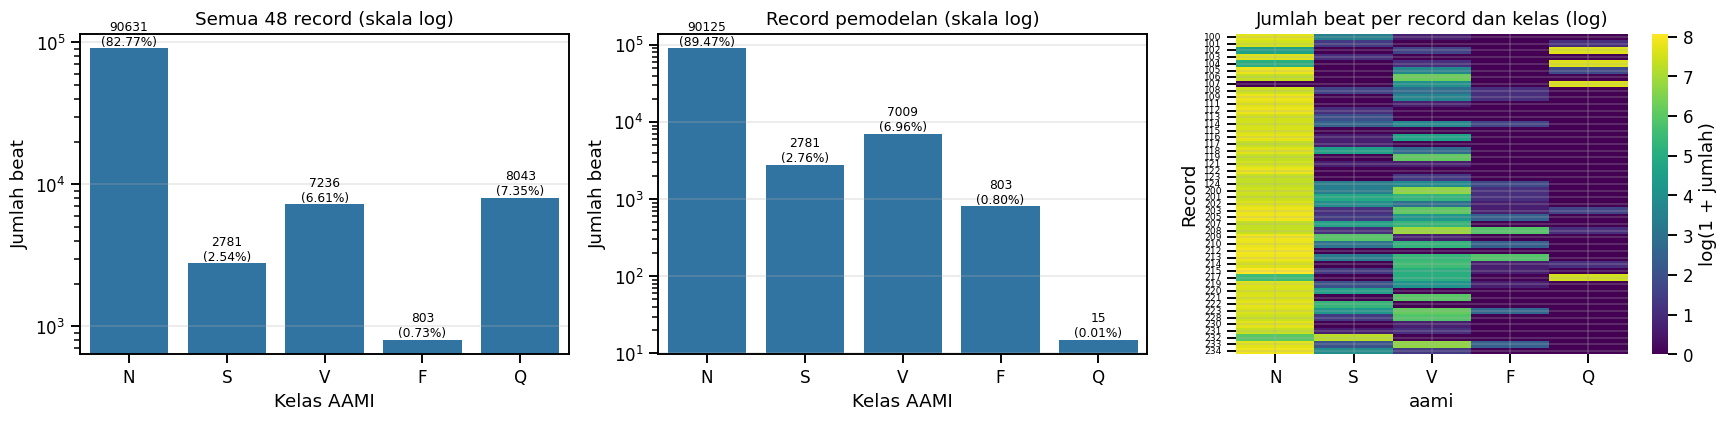

Rasio ketidakseimbangan (kelas terbesar / terkecil yang ada) pada record pemodelan: 6008.3


In [ ]:
# 4.4 Visualisasi distribusi kelas dan sebaran per record
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (title, d) in zip(axes[:2], [('Semua 48 record', dist_all), ('Record pemodelan', dist_inc)]):
    sns.barplot(x=d.index, y=d.jumlah, ax=ax, color='tab:blue')
    ax.set_yscale('log'); ax.set_title(f'{title} (skala log)'); ax.set_xlabel('Kelas AAMI'); ax.set_ylabel('Jumlah beat')
    for i, (v, p) in enumerate(zip(d.jumlah, d.persen)):
        ax.text(i, max(v, 1), f'{v}\n({p:.2f}%)', ha='center', va='bottom', fontsize=8)
per_rec = beats_df.groupby(['Record', 'aami']).size().unstack(fill_value=0).reindex(columns=CLASS_NAMES, fill_value=0)
sns.heatmap(np.log1p(per_rec), cmap='viridis', ax=axes[2], cbar_kws={'label': 'log(1 + jumlah)'}, yticklabels=True)
axes[2].set_title('Jumlah beat per record dan kelas (log)'); axes[2].tick_params(axis='y', labelsize=6)
plt.tight_layout(); plt.show()
print('Rasio ketidakseimbangan (kelas terbesar / terkecil yang ada) pada record pemodelan:',
      round(dist_inc.jumlah.max() / max(dist_inc.jumlah[dist_inc.jumlah > 0].min(), 1), 1))

**Pemeriksaan hasil Bab 4.** Periksa tabel simbol: (i) tidak ada simbol yang "hilang"; (ii) jumlah beat dibanding jumlah non-beat masuk akal; (iii) kelas S, F, dan terutama Q sangat jarang dibanding N — ini sifat dataset, bukan kesalahan. Karena kelas jarang itu terkonsentrasi pada beberapa pasien, pembagian per pasien (Bab 10) akan menghasilkan jumlah kelas minoritas yang tidak merata antar split; hal ini harus diperhitungkan saat menafsirkan hasil.

---
# BAB 5 — SEGMENTASI DETAK JANTUNG

Setiap beat dipotong dari sinyal **terfilter** sebagai `x[s - 100 : s + 200]` (300 sampel; 100 sebelum dan 200 sesudah posisi anotasi `s`), sehingga posisi anotasi berada pada indeks 100 segmen. Beat yang jendelanya melewati awal/akhir rekaman **dibuang dan dicatat**. Tidak ada kelas yang dibuang untuk menyeimbangkan data.

Setiap segmen disimpan bersama `Record_ID`, posisi anotasi, simbol asli, label AAMI, dan indeks beat (disimpan per record sebagai `.npz` agar hemat RAM).

In [ ]:
# 5.1 Segmentasi per record (diproses bertahap, disimpan ke disk)
seg_rows = []
for r in INCLUDED_RECORDS:
    x = np.load(WORK_DIR / 'filtered' / f'{r}.npy')
    b = beats_df[beats_df.Record == r]
    s = b['sample'].to_numpy()
    ok = (s - PRE >= 0) & (s + POST <= len(x))
    segs = np.stack([x[i - PRE:i + POST] for i in s[ok]]).astype(np.float32)
    assert segs.shape[1] == SEG_LEN
    np.savez_compressed(WORK_DIR / 'segments' / f'{r}.npz', segs=segs, sample=s[ok], beat_idx=b.beat_idx.to_numpy()[ok],
                        symbol=b.symbol.to_numpy()[ok].astype(str), aami=b.aami.to_numpy()[ok].astype(str))
    seg_rows.append(dict(Record=r, n_beats=len(b), n_segments=int(ok.sum()), n_discarded=int((~ok).sum()), signal_len=len(x)))
    del x, segs

seg_log = pd.DataFrame(seg_rows).set_index('Record')
display(seg_log)
print('Total beat (record pemodelan):', int(seg_log.n_beats.sum()))
print('Total segmen                 :', int(seg_log.n_segments.sum()))
print('Dibuang (batas rekaman)      :', int(seg_log.n_discarded.sum()))

def load_segments(rec):
    z = np.load(WORK_DIR / 'segments' / f'{rec}.npz')
    return {k: z[k] for k in z.files}

# Pemeriksaan: panjang tiap segmen, dan distribusi kelas setelah segmentasi
lens = set(); post_counts = Counter()
for r in INCLUDED_RECORDS:
    z = load_segments(r)
    lens.add(z['segs'].shape[1]); post_counts.update(z['aami'].tolist())
print('Panjang segmen yang ada:', lens, '(harus {300})')
post_dist = pd.Series(post_counts).reindex(CLASS_NAMES).fillna(0).astype(int)
display(pd.DataFrame({'sebelum_segmentasi': dist_inc.jumlah, 'setelah_segmentasi': post_dist, 'dibuang': dist_inc.jumlah - post_dist}))

,n_beats,n_segments,n_discarded,signal_len
Record,,,,
100,2273,2271,2,650000
101,1865,1864,1,650000
103,2084,2083,1,650000
105,2572,2572,0,650000
106,2027,2027,0,650000
108,1763,1762,1,650000
109,2532,2531,1,650000
111,2124,2124,0,650000
112,2539,2538,1,650000


Total beat (record pemodelan): 100733
Total segmen                 : 100689
Dibuang (batas rekaman)      : 44
Panjang segmen yang ada: {300} (harus {300})


,sebelum_segmentasi,setelah_segmentasi,dibuang
N,90125,90083,42
S,2781,2781,0
V,7009,7008,1
F,803,802,1
Q,15,15,0


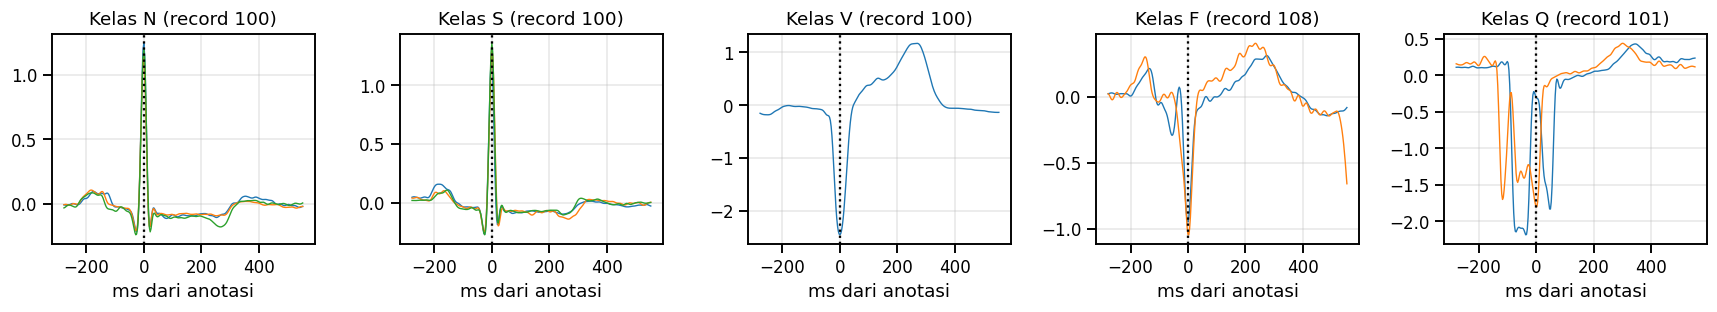

In [ ]:
# 5.2 Visualisasi contoh segmen per kelas (garis vertikal = posisi anotasi)
fig, axes = plt.subplots(1, len(CLASS_NAMES), figsize=(16, 3), sharey=False)
t_seg = (np.arange(SEG_LEN) - PRE) / FS * 1000
rng_vis = np.random.default_rng(SEED)
for ax, c in zip(axes, CLASS_NAMES):
    found = False
    for r in INCLUDED_RECORDS:
        z = load_segments(r)
        idx = np.where(z['aami'] == c)[0]
        if len(idx):
            for j in rng_vis.choice(idx, size=min(3, len(idx)), replace=False):
                ax.plot(t_seg, z['segs'][j], lw=0.9)
            ax.set_title(f'Kelas {c} (record {r})'); found = True; break
    if not found:
        ax.set_title(f'Kelas {c}: tidak ada data'); ax.axis('off')
    ax.axvline(0, color='k', ls=':'); ax.set_xlabel('ms dari anotasi')
plt.tight_layout(); plt.show()

---
# BAB 6 — DETEKSI DAN VALIDASI PUNCAK R

Detektor R-peak NeuroKit2 (`nk.ecg_peaks`) dijalankan pada sinyal terfilter lalu **dibandingkan dengan anotasi beat MIT-BIH** (acuan lokasi beat). Hasil otomatis tidak diasumsikan benar.

**Metode evaluasi**
- Toleransi awal **150 ms = 54 sampel** (sesuai spesifikasi; sensitivitas terhadap toleransi lain ditampilkan sebagai pembanding).
- Pencocokan **satu-ke-satu** secara berurutan waktu: satu puncak hasil deteksi hanya boleh cocok dengan satu anotasi. Kasus ambigu (deteksi lebih dekat ke anotasi berikutnya) ditangani agar tidak ada pasangan ganda.
- TP = pasangan cocok; FN = anotasi tanpa deteksi; FP = deteksi tanpa anotasi.
- Sensitivity = TP/(TP+FN); PPV = TP/(TP+FP); F1 = 2·Se·PPV/(Se+PPV).

**Catatan:** anotasi MIT-BIH adalah acuan lokasi beat, **tidak selalu** berimpit dengan maksimum lokal sinyal; karena itu selisih posisi (offset) sistematis dihitung dan toleransi dipakai. Evaluasi dijalankan pada seluruh 48 record (termasuk paced) agar kelemahan detektor terlihat; kolom `modeled` menandai record yang dipakai pemodelan.

In [ ]:
# 6.1 Fungsi pencocokan satu-ke-satu dan evaluasi per record
def match_peaks(ref, det, tol):
    # ref, det terurut menaik. Mengembalikan indeks (tp_ref, tp_det, fn_ref, fp_det)
    ref = np.asarray(ref); det = np.asarray(det)
    i = j = 0
    tp_ref, tp_det, fn, fp = [], [], [], []
    while i < len(ref) and j < len(det):
        d = det[j] - ref[i]
        if abs(d) <= tol:
            # bila deteksi lebih dekat ke anotasi berikutnya, anotasi ini dianggap terlewat
            if i + 1 < len(ref) and abs(det[j] - ref[i + 1]) < abs(d):
                fn.append(i); i += 1; continue
            tp_ref.append(i); tp_det.append(j); i += 1; j += 1
        elif d < -tol:
            fp.append(j); j += 1
        else:
            fn.append(i); i += 1
    fn.extend(range(i, len(ref))); fp.extend(range(j, len(det)))
    return np.array(tp_ref, int), np.array(tp_det, int), np.array(fn, int), np.array(fp, int)

# Uji unit pencocokan
_ref = np.array([100, 500, 900, 1300]); _det = np.array([105, 480, 1000, 1310, 1320])
_tr, _td, _fn, _fp = match_peaks(_ref, _det, 54)
assert list(_tr) == [0, 1, 3] and list(_fn) == [2] and list(_fp) == [2, 4], (_tr, _fn, _fp)
print('Uji unit match_peaks: OK')

def detect_rpeaks(x, method):
    _, info = nk.ecg_peaks(x, sampling_rate=FS, method=method)
    return np.sort(np.asarray(info['ECG_R_Peaks'], dtype=np.int64))

def prf(tp, fp, fn):
    se = tp / (tp + fn) if tp + fn else np.nan
    ppv = tp / (tp + fp) if tp + fp else np.nan
    f1 = 2 * se * ppv / (se + ppv) if (se + ppv) else np.nan
    return se, ppv, f1

Uji unit match_peaks: OK


In [ ]:
# 6.2 Deteksi NeuroKit2 pada seluruh record dan evaluasi terhadap anotasi
tol_samp = int(round(TOL_MS * FS / 1000))
print(f'Toleransi: {TOL_MS} ms = {tol_samp} sampel | metode: {RPEAK_METHOD}')
det_peaks, det_rows, offsets_ms = {}, [], []
t0 = time.time()
for r in RECORDS:
    x = np.load(WORK_DIR / 'filtered' / f'{r}.npy').astype(np.float64)
    ref = beats_df[beats_df.Record == r]['sample'].to_numpy()
    det = detect_rpeaks(x, RPEAK_METHOD)
    det_peaks[r] = det
    tr, td, fn, fp = match_peaks(ref, det, tol_samp)
    se, ppv, f1 = prf(len(tr), len(fp), len(fn))
    off = (det[td] - ref[tr]) / FS * 1000
    offsets_ms.append(pd.DataFrame({'Record': r, 'offset_ms': off}))
    det_rows.append(dict(Record=r, modeled=r in INCLUDED_RECORDS, n_ref=len(ref), n_det=len(det), TP=len(tr), FP=len(fp), FN=len(fn),
                         Se=se, PPV=ppv, F1=f1, median_offset_ms=np.median(off) if len(off) else np.nan,
                         mad_offset_ms=np.median(np.abs(off - np.median(off))) if len(off) else np.nan))
    del x
det_df = pd.DataFrame(det_rows).set_index('Record')
offsets_df = pd.concat(offsets_ms, ignore_index=True)
print(f'Waktu deteksi seluruh record: {time.time() - t0:.1f} detik')
display(det_df.sort_values('F1'))

def overall(df):
    TP, FP, FN = df.TP.sum(), df.FP.sum(), df.FN.sum()
    se, ppv, f1 = prf(TP, FP, FN)
    return pd.Series(dict(TP=TP, FP=FP, FN=FN, Sensitivity=se, PPV=ppv, F1=f1))
display(pd.DataFrame({'Semua record': overall(det_df), 'Record pemodelan': overall(det_df[det_df.modeled])}))

Toleransi: 150 ms = 54 sampel | metode: neurokit
Waktu deteksi seluruh record: 5.3 detik


,modeled,n_ref,n_det,TP,FP,FN,Se,PPV,F1,median_offset_ms,mad_offset_ms
Record,,,,,,,,,,,
207,True,1860,1573,1513,60,347,0.8134,0.9619,0.8814,-61.1111,5.5556
231,True,1571,1841,1571,270,0,1.0000,0.8533,0.9209,0.0000,0.0000
108,True,1763,1775,1668,107,95,0.9461,0.9397,0.9429,0.0000,5.5556
203,True,2980,2839,2817,22,163,0.9453,0.9923,0.9682,0.0000,0.0000
232,True,1780,1868,1780,88,0,1.0000,0.9529,0.9759,2.7778,0.0000
228,True,2053,2068,2041,27,12,0.9942,0.9869,0.9905,0.0000,0.0000
104,False,2229,2200,2196,4,33,0.9852,0.9982,0.9916,-2.7778,2.7778
105,True,2572,2571,2555,16,17,0.9934,0.9938,0.9936,-2.7778,0.0000
201,True,1963,1986,1963,23,0,1.0000,0.9884,0.9942,2.7778,0.0000


,Semua record,Record pemodelan
TP,"108,697.0000","99,971.0000"
FP,711.0000,706.0000
FN,797.0000,762.0000
Sensitivity,0.9927,0.9924
PPV,0.9935,0.9930
F1,0.9931,0.9927


,toleransi_ms,toleransi_sampel,TP,FP,FN,Sensitivity,PPV,F1
0,20,7,102479,6929,7015,0.9359,0.9367,0.9363
1,50,18,106783,2625,2711,0.9752,0.9760,0.9756
2,100,36,108641,767,853,0.9922,0.9930,0.9926
3,150,54,108697,711,797,0.9927,0.9935,0.9931
4,200,72,108731,677,763,0.9930,0.9938,0.9934


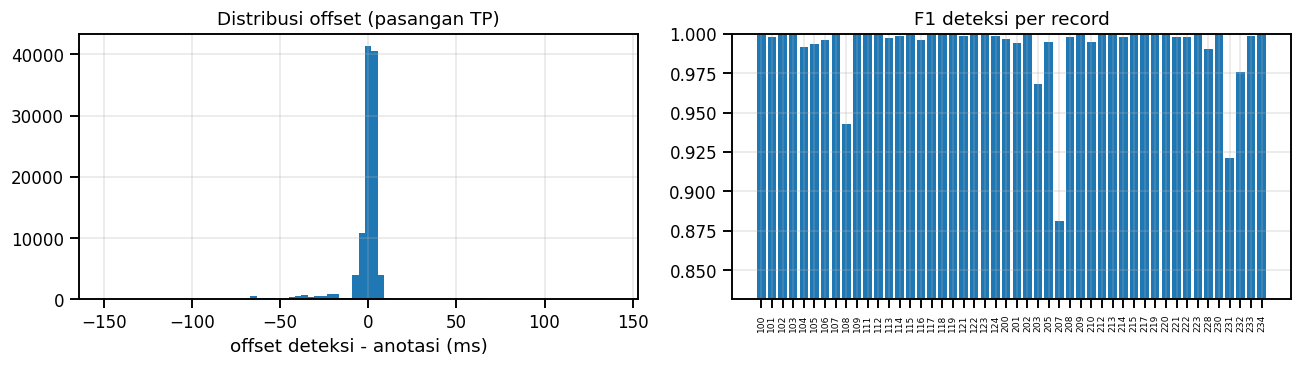

Median offset keseluruhan: 0.0 ms | MAD: 2.8 ms


In [ ]:
# 6.3 Sensitivitas terhadap toleransi dan distribusi offset
tol_rows = []
for tol_ms in (20, 50, 100, 150, 200):
    ts = int(round(tol_ms * FS / 1000)); TP = FP = FN = 0
    for r in RECORDS:
        ref = beats_df[beats_df.Record == r]['sample'].to_numpy()
        a, _, c, d = match_peaks(ref, det_peaks[r], ts)
        TP += len(a); FN += len(c); FP += len(d)
    se, ppv, f1 = prf(TP, FP, FN)
    tol_rows.append(dict(toleransi_ms=tol_ms, toleransi_sampel=ts, TP=TP, FP=FP, FN=FN, Sensitivity=se, PPV=ppv, F1=f1))
display(pd.DataFrame(tol_rows))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(offsets_df.offset_ms, bins=80); axes[0].set_xlabel('offset deteksi - anotasi (ms)'); axes[0].set_title('Distribusi offset (pasangan TP)')
axes[1].bar(det_df.index, det_df.F1.fillna(0)); axes[1].set_ylim(max(0, det_df.F1.min() - 0.05), 1.0)
axes[1].tick_params(axis='x', rotation=90, labelsize=6); axes[1].set_title('F1 deteksi per record')
plt.tight_layout(); plt.show()
print(f'Median offset keseluruhan: {offsets_df.offset_ms.median():.1f} ms | MAD: {np.median(np.abs(offsets_df.offset_ms - offsets_df.offset_ms.median())):.1f} ms')

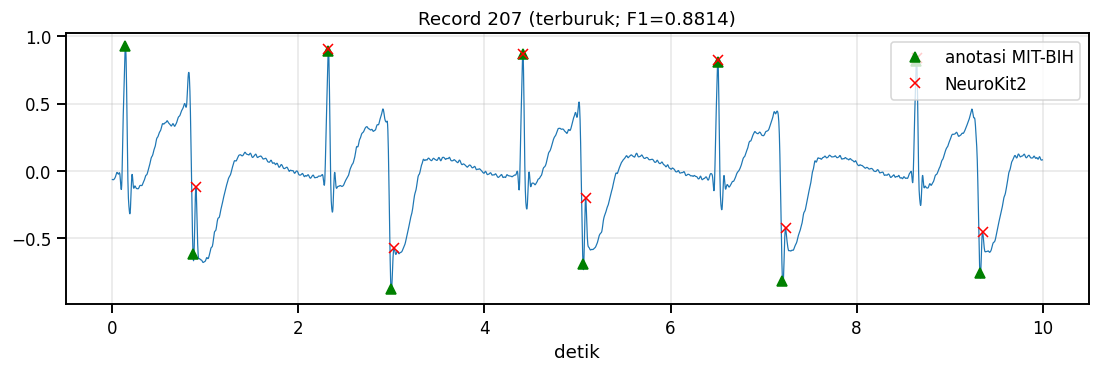

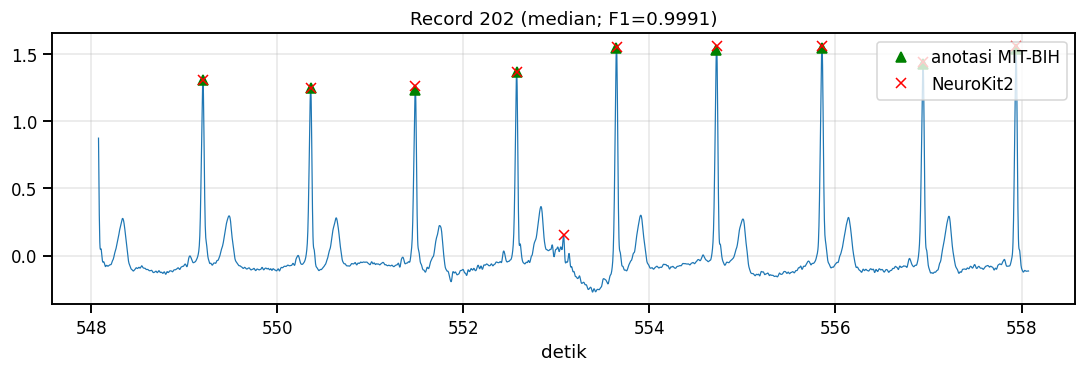

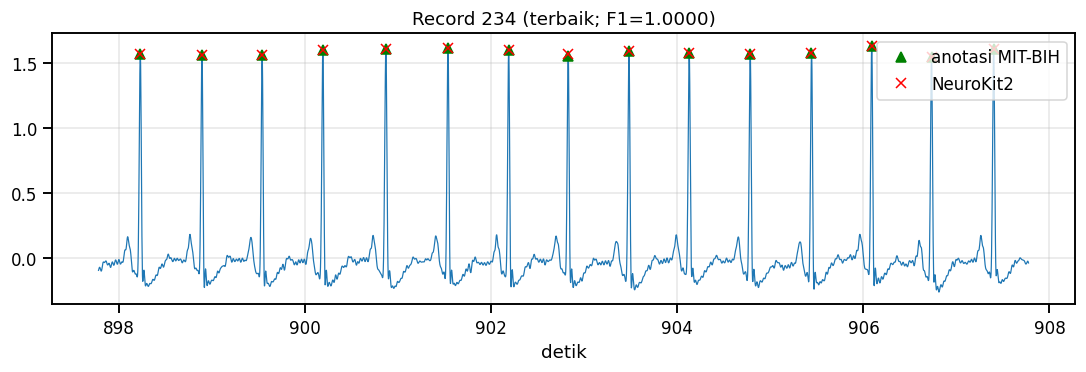

In [ ]:
# 6.4 Visualisasi contoh deteksi: record terbaik, median, dan terburuk berdasarkan F1
ranked = det_df.F1.sort_values()
examples = {'terburuk': ranked.index[0], 'median': ranked.index[len(ranked) // 2], 'terbaik': ranked.index[-1]}

def plot_detection(rec, center_s=None, dur_s=10, title=''):
    x = np.load(WORK_DIR / 'filtered' / f'{rec}.npy')
    ref = beats_df[beats_df.Record == rec]['sample'].to_numpy(); det = det_peaks[rec]
    tr, td, fn, fp = match_peaks(ref, det, tol_samp)
    if center_s is None:
        bad = np.sort(np.concatenate([ref[fn], det[fp]])) if (len(fn) or len(fp)) else np.array([len(x) // 2])
        center_s = bad[0] / FS
    a = int(max(0, (center_s - dur_s / 2) * FS)); b = int(min(len(x), a + dur_s * FS))
    t = np.arange(a, b) / FS
    plt.figure(figsize=(12, 3.2)); plt.plot(t, x[a:b], lw=0.8, color='tab:blue')
    m = (ref >= a) & (ref < b); plt.plot(ref[m] / FS, x[ref[m]], 'g^', ms=7, label='anotasi MIT-BIH')
    m = (det >= a) & (det < b); plt.plot(det[m] / FS, x[det[m]], 'rx', ms=7, label='NeuroKit2')
    plt.title(f'Record {rec} {title}'); plt.xlabel('detik'); plt.legend(loc='upper right'); plt.show()

for k, r in examples.items():
    plot_detection(r, title=f'({k}; F1={det_df.loc[r, "F1"]:.4f})')

In [ ]:
# 6.5 Analisis deteksi yang gagal
fn_rows = []
for r in RECORDS:
    b = beats_df[beats_df.Record == r].reset_index(drop=True)
    _, _, fn, fp = match_peaks(b['sample'].to_numpy(), det_peaks[r], tol_samp)
    fn_rows.append(pd.DataFrame({'Record': r, 'aami': b.loc[fn, 'aami'].values, 'symbol': b.loc[fn, 'symbol'].values}))
fn_df = pd.concat(fn_rows, ignore_index=True)
miss_by_class = pd.DataFrame({'beat_total': beats_df.aami.value_counts().reindex(CLASS_NAMES).fillna(0).astype(int),
                              'beat_terlewat_(FN)': fn_df.aami.value_counts().reindex(CLASS_NAMES).fillna(0).astype(int)})
miss_by_class['laju_terlewat_%'] = 100 * miss_by_class['beat_terlewat_(FN)'] / miss_by_class.beat_total.replace(0, np.nan)
display(miss_by_class)
print('FN per simbol (10 terbanyak):'); display(fn_df.symbol.value_counts().head(10).to_frame('FN'))

poor = det_df[(det_df.Se < ADEQUATE_F1) | (det_df.PPV < ADEQUATE_F1)].sort_values('F1')
print(f'Record dengan Se atau PPV < {ADEQUATE_F1}: {len(poor)} dari {len(det_df)}')
display(poor[['modeled', 'n_ref', 'TP', 'FP', 'FN', 'Se', 'PPV', 'F1']])
overall_f1 = overall(det_df[det_df.modeled]).F1
print(f'F1 keseluruhan (record pemodelan) = {overall_f1:.4f} | ambang kecukupan = {ADEQUATE_F1}')
print('Kesimpulan otomatis:', 'detektor memadai secara keseluruhan' if overall_f1 >= ADEQUATE_F1
      else 'detektor BELUM memadai secara keseluruhan -> lihat evaluasi alternatif di bawah')

,beat_total,beat_terlewat_(FN),laju_terlewat_%
aami,,,
N,90631,424,0.4678
S,2781,104,3.7397
V,7236,229,3.1647
F,803,4,0.4981
Q,8043,36,0.4476


FN per simbol (10 terbanyak):


,FN
symbol,
L,234
V,229
N,188
A,103
/,21
Q,11
f,4
F,4
R,2


Record dengan Se atau PPV < 0.99: 9 dari 48


,modeled,n_ref,TP,FP,FN,Se,PPV,F1
Record,,,,,,,,
207,True,1860,1513,60,347,0.8134,0.9619,0.8814
231,True,1571,1571,270,0,1.0000,0.8533,0.9209
108,True,1763,1668,107,95,0.9461,0.9397,0.9429
203,True,2980,2817,22,163,0.9453,0.9923,0.9682
232,True,1780,1780,88,0,1.0000,0.9529,0.9759
228,True,2053,2041,27,12,0.9942,0.9869,0.9905
104,False,2229,2196,4,33,0.9852,0.9982,0.9916
201,True,1963,1963,23,0,1.0000,0.9884,0.9942
205,True,2656,2629,0,27,0.9898,1.0000,0.9949


F1 keseluruhan (record pemodelan) = 0.9927 | ambang kecukupan = 0.99
Kesimpulan otomatis: detektor memadai secara keseluruhan


In [ ]:
# 6.6 Evaluasi detektor alternatif pada record tersulit (bukan memaksakan satu algoritma)
if RUN_ALT_DETECTORS:
    hard = det_df[det_df.modeled].F1.sort_values().index[:4].tolist() + [det_df[det_df.modeled].F1.idxmax()]
    hard = list(dict.fromkeys(hard))                      # hilangkan duplikat bila record terbaik juga ada di daftar tersulit
    methods = ['neurokit', 'pantompkins1985', 'hamilton2002', 'elgendi2010']
    alt_rows = []
    for r in hard:
        x = np.load(WORK_DIR / 'filtered' / f'{r}.npy').astype(np.float64)
        ref = beats_df[beats_df.Record == r]['sample'].to_numpy()
        for m in methods:
            t0 = time.time()
            try:
                det = detect_rpeaks(x, m)
            except Exception as e:                    # galat dicatat, tidak disembunyikan
                alt_rows.append(dict(Record=r, method=m, error=f'{type(e).__name__}: {e}')); continue
            a, _, c, d = match_peaks(ref, det, tol_samp)
            se, ppv, f1 = prf(len(a), len(d), len(c))
            alt_rows.append(dict(Record=r, method=m, Se=se, PPV=ppv, F1=f1, detik=time.time() - t0))
    alt_df = pd.DataFrame(alt_rows)
    display(alt_df.pivot(index='Record', columns='method', values='F1') if 'F1' in alt_df else alt_df)
    if 'error' in alt_df: display(alt_df[alt_df.error.notna()])
    print('Rata-rata F1 per metode (record tersulit + terbaik):'); display(alt_df.groupby('method').F1.mean().sort_values(ascending=False).to_frame('F1_rata2'))

print('''Keputusan metodologis [K5]: untuk RR interval, segmentasi, dan label, pipeline memakai POSISI ANOTASI AHLI sebagai lokasi beat
(bukan hasil detektor), agar galat detektor tidak merusak pasangan beat-label. Detektor divalidasi di sini untuk menunjukkan
seberapa jauh pipeline ini dapat dipakai pada data tanpa anotasi; jika diterapkan pada data baru, detektor yang terpilih dari
evaluasi ini harus dipakai dan galatnya ikut dilaporkan.''')

method,elgendi2010,hamilton2002,neurokit,pantompkins1985
Record,,,,
103,0.9885,0.9971,1.0000,0.9986
108,0.1675,0.4917,0.9429,0.7821
203,0.8922,0.9879,0.9682,0.9853
207,0.8850,0.9614,0.8814,0.9299
231,0.6377,0.9414,0.9209,0.9987


Rata-rata F1 per metode (record tersulit + terbaik):


,F1_rata2
method,
neurokit,0.9427
pantompkins1985,0.9389
hamilton2002,0.8759
elgendi2010,0.7142


Keputusan metodologis [K5]: untuk RR interval, segmentasi, dan label, pipeline memakai POSISI ANOTASI AHLI sebagai lokasi beat
(bukan hasil detektor), agar galat detektor tidak merusak pasangan beat-label. Detektor divalidasi di sini untuk menunjukkan
seberapa jauh pipeline ini dapat dipakai pada data tanpa anotasi; jika diterapkan pada data baru, detektor yang terpilih dari
evaluasi ini harus dipakai dan galatnya ikut dilaporkan.


**Pemeriksaan hasil Bab 6.** Baca tabel per-record dan analisis FN/FP: rekaman yang sudah dikenal sulit (mis. derau tinggi, kompleks lebar, ritme tidak teratur) akan tampak sebagai F1 rendah. Jika F1 keseluruhan di bawah ambang, jangan memakai NeuroKit2 apa adanya untuk deployment — bandingkan dengan detektor alternatif pada tabel 6.6. Perhatikan pula bahwa offset median tidak nol: ini wajar karena anotasi MIT-BIH tidak selalu tepat pada puncak maksimum.

---
# BAB 7 — DELINEASI GELOMBANG ECG

Delineasi (penentuan titik onset/puncak/offset gelombang P, kompleks QRS, dan gelombang T) memakai **`nk.ecg_delineate`** (NeuroKit2, metode *Discrete Wavelet Transform*; metode `'peak'` tidak dipakai karena tidak menghasilkan onset/offset QRS). Lokasi beat yang diberikan ke delineator adalah **posisi anotasi MIT-BIH** `[K5]`.

**Prinsip**
- Tidak ada asumsi posisi P/QRS/T yang sama untuk semua beat: setiap titik berasal dari delineator per beat.
- Hasil delineator **diperiksa kelayakannya** per beat dengan aturan plausibilitas yang eksplisit (parameter di Bab 1):
  - **QRS valid** bila onset dan offset ada, `onset < puncak R < offset`, dan durasi dalam `[QRS_MIN_MS, QRS_MAX_MS]` (default 40–250 ms).
  - **P valid** bila puncak P ada, berada **sebelum QRS onset**, setelah beat sebelumnya, dan jaraknya ke R ≤ `P_MAX_BEFORE_R_MS`.
  - **T valid** bila puncak T ada, berada **setelah QRS offset**, sebelum beat berikutnya, dan jaraknya dari R ≤ `T_MAX_AFTER_R_MS`.
- Bila delineasi gagal atau tidak valid, kegagalan **dicatat** dan **tidak diisi nilai pengganti**.
- Puncak R yang dipakai untuk amplitudo (`r_ref`) = titik dengan simpangan absolut terbesar dari baseline dalam ±`R_SEARCH_MS` dari anotasi (polaritas dipertahankan di Bab 8).
- **Baseline** per beat = median segmen 300 sampel di sekitar anotasi `[K7]`.

**Keterbatasan validasi:** MIT-BIH tidak menyediakan anotasi onset/offset gelombang, sehingga akurasi delineasi hanya dapat dinilai lewat pemeriksaan plausibilitas dan inspeksi visual (bukan terhadap acuan emas seperti QT Database). Hasilnya harus ditafsirkan dengan kehati-hatian, terutama untuk gelombang P/T pada beat ektopik.

In [ ]:
# 7.1 Fungsi delineasi per record (dengan cache di disk) dan aturan validitas
WAVE_KEYS = {'ECG_P_Onsets': 'P_on', 'ECG_P_Peaks': 'P_peak', 'ECG_P_Offsets': 'P_off',
             'ECG_R_Onsets': 'QRS_on', 'ECG_R_Offsets': 'QRS_off',
             'ECG_T_Onsets': 'T_on', 'ECG_T_Peaks': 'T_peak', 'ECG_T_Offsets': 'T_off'}
R_SEARCH = int(round(R_SEARCH_MS * FS / 1000))
MS = FS / 1000.0

def delineate_record(rec):
    cache = WORK_DIR / 'delineation' / f'{rec}_{DELINEATE_METHOD}.csv'
    if REUSE_CACHE and cache.exists():
        return pd.read_csv(cache)
    x = np.load(WORK_DIR / 'filtered' / f'{rec}.npy').astype(np.float64)
    b = beats_df[beats_df.Record == rec].reset_index(drop=True)
    rp = b['sample'].to_numpy().astype(int)
    _, waves = nk.ecg_delineate(x, {'ECG_R_Peaks': rp}, sampling_rate=FS, method=DELINEATE_METHOD, show=False)
    out = b[['Record', 'beat_idx', 'sample', 'symbol', 'aami']].copy()
    for key, col in WAVE_KEYS.items():
        if key not in waves:
            raise KeyError(f'Kunci {key} tidak ada di hasil delineasi; kunci tersedia: {list(waves)}')
        v = np.asarray(waves[key], dtype=float)
        if len(v) != len(rp):
            raise ValueError(f'Record {rec}: panjang {key}={len(v)} != jumlah beat {len(rp)}')
        out[col] = v
    n = len(x)
    base = np.full(len(rp), np.nan); r_ref = np.full(len(rp), np.nan)
    for k, s in enumerate(rp):
        lo, hi = max(0, s - PRE), min(n, s + POST)
        base[k] = np.median(x[lo:hi])
        a, c = max(0, s - R_SEARCH), min(n, s + R_SEARCH + 1)
        r_ref[k] = a + np.argmax(np.abs(x[a:c] - base[k]))
    out['baseline'] = base
    out['r_ref'] = r_ref
    out['has_segment'] = (rp - PRE >= 0) & (rp + POST <= n)
    out.to_csv(cache, index=False)
    return out

def apply_validity(df):
    d = df.copy()
    r = d.r_ref
    prev_s = d['sample'].shift(1).fillna(-np.inf)
    next_s = d['sample'].shift(-1).fillna(np.inf)
    # --- QRS ---
    present = d.QRS_on.notna() & d.QRS_off.notna()
    order_ok = present & (d.QRS_on < r) & (r < d.QRS_off)
    dur_ms = (d.QRS_off - d.QRS_on) / MS
    dur_ok = dur_ms.between(QRS_MIN_MS, QRS_MAX_MS)
    d['qrs_ok'] = order_ok & dur_ok
    d['qrs_reason'] = np.select([~present, ~order_ok, ~dur_ok], ['tidak_terdeteksi', 'urutan_tidak_valid', 'durasi_tidak_plausibel'], 'ok')
    # --- P ---
    p_present = d.P_peak.notna()
    p_ok = p_present & (d.P_peak < d.QRS_on) & (d.P_peak > prev_s) & ((r - d.P_peak) / MS <= P_MAX_BEFORE_R_MS)
    d['p_ok'] = p_ok
    d['p_reason'] = np.select([~p_present, ~p_ok], ['tidak_terdeteksi', 'posisi_tidak_plausibel'], 'ok')
    # --- T ---
    t_present = d.T_peak.notna()
    t_ok = t_present & (d.T_peak > d.QRS_off) & (d.T_peak < next_s) & ((d.T_peak - r) / MS <= T_MAX_AFTER_R_MS)
    d['t_ok'] = t_ok
    d['t_reason'] = np.select([~t_present, ~t_ok], ['tidak_terdeteksi', 'posisi_tidak_plausibel'], 'ok')
    return d

# 7.2 Menjalankan delineasi untuk seluruh record pemodelan (bertahap; kegagalan per record dicatat, bukan disembunyikan)
deln_raw, deln_errors, deln_time = {}, {}, {}
for r in INCLUDED_RECORDS:
    t0 = time.time()
    try:
        deln_raw[r] = delineate_record(r)
    except Exception as e:
        deln_errors[r] = f'{type(e).__name__}: {e}'
        print(f'[GAGAL] record {r}: {deln_errors[r]}')
    deln_time[r] = time.time() - t0
print(f'Selesai. Record berhasil: {len(deln_raw)}/{len(INCLUDED_RECORDS)} | total waktu: {sum(deln_time.values()):.0f} detik')
if deln_errors:
    display(pd.Series(deln_errors, name='error').to_frame())
    raise RuntimeError('Delineasi gagal untuk sebagian record. Perbaiki penyebabnya lalu jalankan ulang.')

deln = {r: apply_validity(df) for r, df in deln_raw.items()}
deln_all = pd.concat(deln.values(), ignore_index=True)
print('Total beat didelineasi:', len(deln_all))

Selesai. Record berhasil: 44/44 | total waktu: 845 detik
Total beat didelineasi: 100733


In [ ]:
# 7.3 Ringkasan keberhasilan delineasi: per record dan per kelas AAMI
cand = deln_all[deln_all.has_segment]
def rate(df): return pd.Series(dict(n=len(df), QRS_ok=100 * df.qrs_ok.mean(), P_ok=100 * df.p_ok.mean(), T_ok=100 * df.t_ok.mean(),
                                    semua_ok=100 * (df.qrs_ok & df.p_ok & df.t_ok).mean()))
by_class = cand.groupby('aami').apply(rate, include_groups=False).reindex(CLASS_NAMES)
print('Persentase beat dengan hasil delineasi VALID, per kelas AAMI:'); display(by_class)
by_record = cand.groupby('Record').apply(rate, include_groups=False)
print('Per record (10 dengan "semua_ok" terendah):'); display(by_record.sort_values('semua_ok').head(10))

print('Alasan kegagalan:')
for col in ('qrs_reason', 'p_reason', 't_reason'):
    display(cand[col].value_counts().to_frame(col))

Persentase beat dengan hasil delineasi VALID, per kelas AAMI:


,n,QRS_ok,P_ok,T_ok,semua_ok
aami,,,,,
N,"90,083.0000",77.8205,87.4482,88.5772,76.4484
S,"2,781.0000",84.4301,87.8101,95.7210,81.8051
V,"7,008.0000",27.8824,55.5223,58.2334,27.5828
F,802.0000,31.0474,96.2594,36.9077,30.5486
Q,15.0000,46.6667,60.0000,53.3333,46.6667


Per record (10 dengan "semua_ok" terendah):


,n,QRS_ok,P_ok,T_ok,semua_ok
Record,,,,,
213,"3,249.0000",5.4171,97.9378,5.4786,5.3555
221,"2,426.0000",8.5738,23.5367,82.9349,8.5738
233,"3,077.0000",9.0348,74.5206,30.2242,8.9048
207,"1,859.0000",19.6342,26.0893,94.1904,19.6342
214,"2,260.0000",21.8584,56.5044,34.2920,21.5929
114,"1,879.0000",21.8201,21.9798,99.6275,21.7137
219,"2,154.0000",22.8412,63.6955,34.7725,22.8412
210,"2,648.0000",33.9502,48.3384,74.5468,33.6103
202,"2,135.0000",46.2763,51.9906,88.5246,44.1686


Alasan kegagalan:


,qrs_reason
qrs_reason,
ok,74661
tidak_terdeteksi,23701
durasi_tidak_plausibel,1990
urutan_tidak_valid,337


,p_reason
p_reason,
ok,85890
posisi_tidak_plausibel,14160
tidak_terdeteksi,639


,t_reason
t_reason,
ok,86840
tidak_terdeteksi,13581
posisi_tidak_plausibel,268


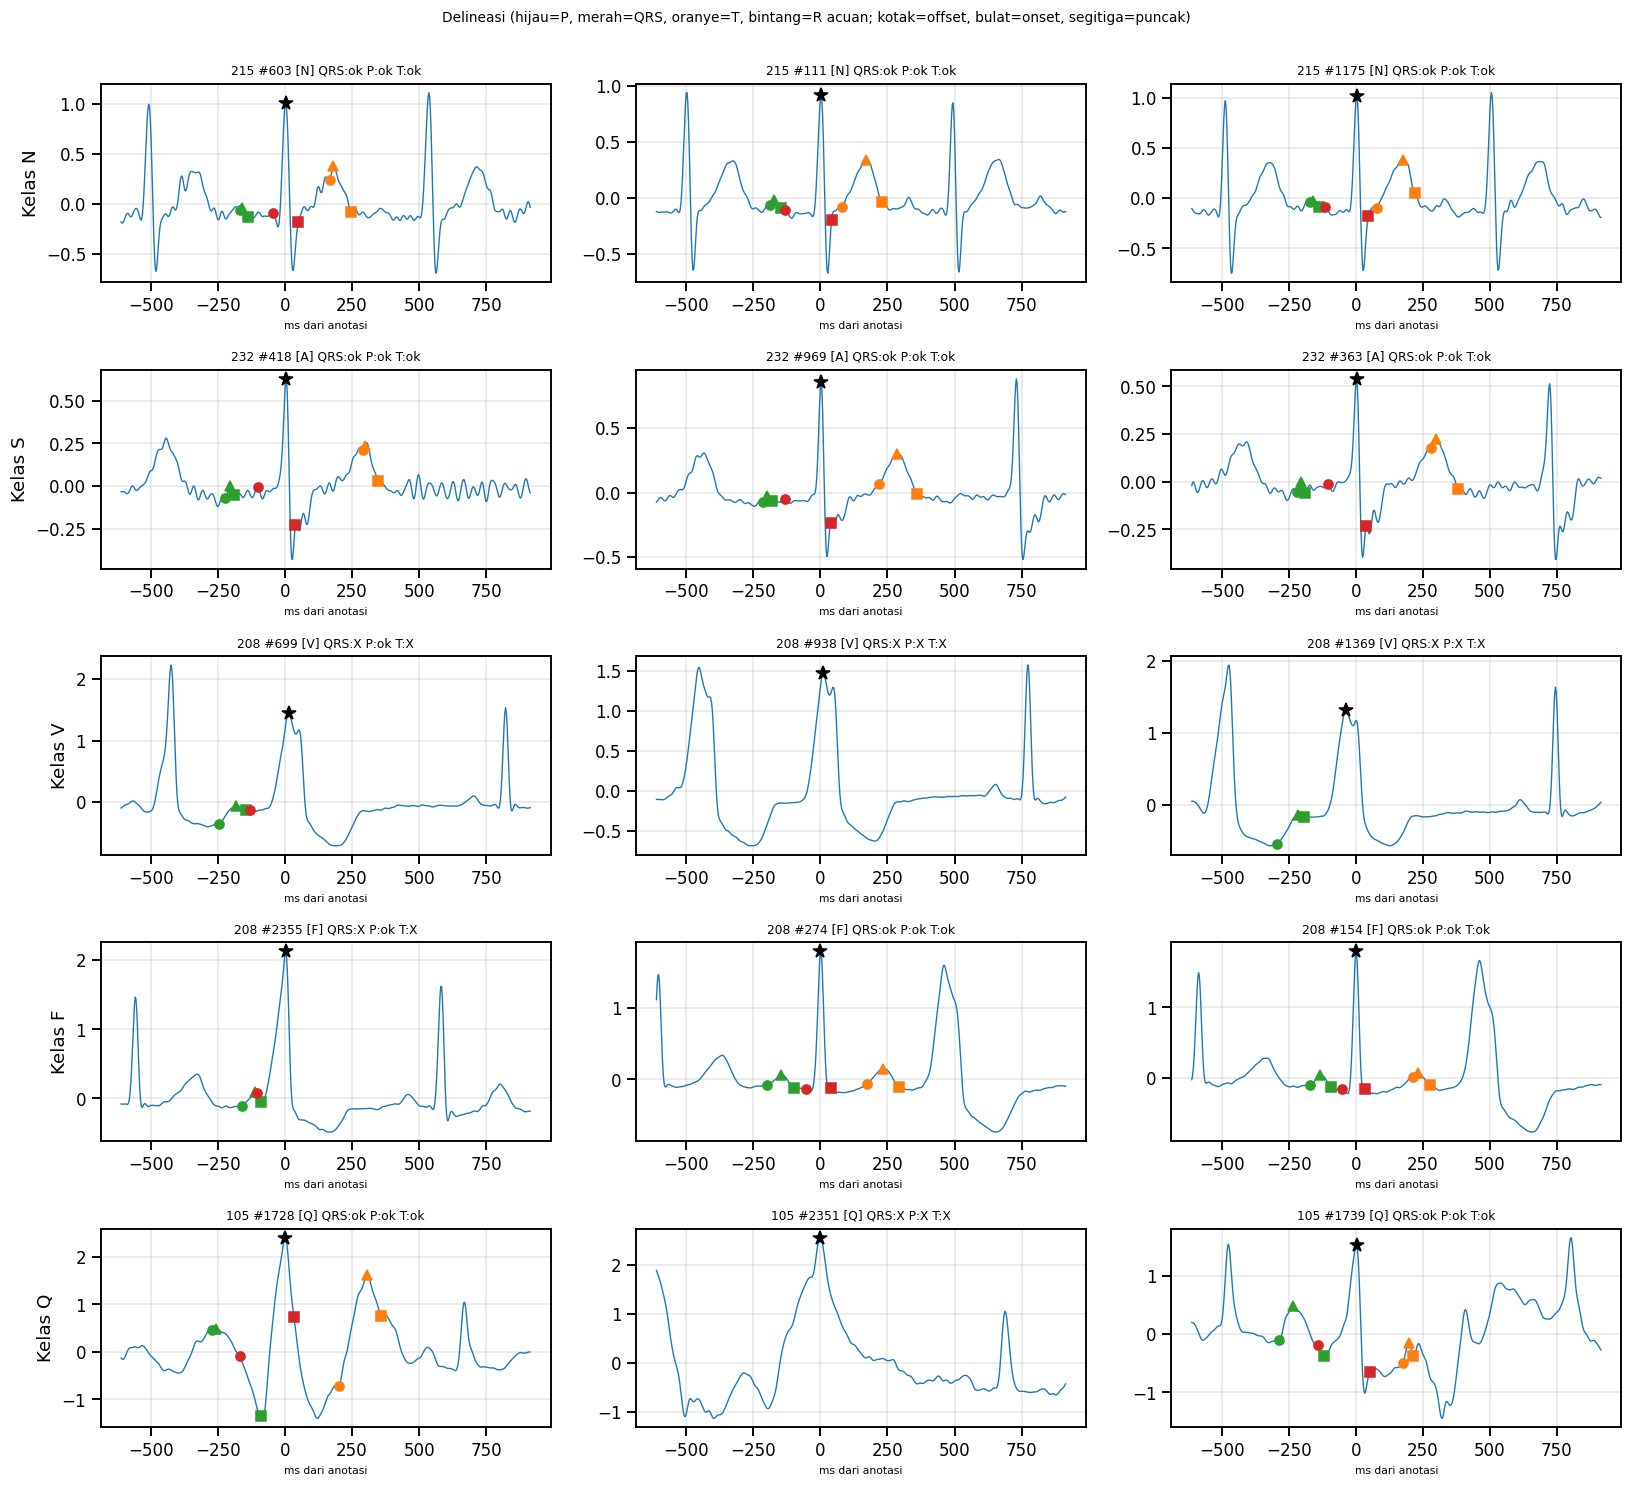

In [ ]:
# 7.4 Validasi visual: beat acak per kelas AAMI, termasuk beat dengan delineasi tidak valid
def plot_delineation(row, ax):
    r = row.Record; s = int(row['sample'])
    x = np.load(WORK_DIR / 'filtered' / f'{r}.npy')
    a, b = max(0, s - 220), min(len(x), s + 330)
    t = (np.arange(a, b) - s) / FS * 1000
    ax.plot(t, x[a:b], lw=0.9, color='tab:blue')
    marks = [('P_on', 'o', 'tab:green'), ('P_peak', '^', 'tab:green'), ('P_off', 's', 'tab:green'),
             ('QRS_on', 'o', 'tab:red'), ('QRS_off', 's', 'tab:red'),
             ('T_on', 'o', 'tab:orange'), ('T_peak', '^', 'tab:orange'), ('T_off', 's', 'tab:orange')]
    for col, mk, c in marks:
        v = row[col]
        if pd.notna(v) and a <= v < b:
            ax.plot((v - s) / FS * 1000, x[int(v)], mk, color=c, ms=6)
    ax.plot((row.r_ref - s) / FS * 1000, x[int(row.r_ref)], 'k*', ms=9)
    flags = f"QRS:{'ok' if row.qrs_ok else 'X'} P:{'ok' if row.p_ok else 'X'} T:{'ok' if row.t_ok else 'X'}"
    ax.set_title(f'{r} #{int(row.beat_idx)} [{row.symbol}] {flags}', fontsize=8)
    ax.set_xlabel('ms dari anotasi', fontsize=7)

rng_d = np.random.default_rng(SEED)
present_classes = [c for c in CLASS_NAMES if (cand.aami == c).any()]
fig, axes = plt.subplots(len(present_classes), 3, figsize=(15, 2.7 * len(present_classes)), squeeze=False)
for i, c in enumerate(present_classes):
    sub = cand[cand.aami == c]
    best_rec = sub.Record.value_counts().index[0]                  # record dengan beat kelas c terbanyak
    pick = sub[sub.Record == best_rec].sample(n=min(3, (sub.Record == best_rec).sum()), random_state=SEED)
    for j in range(3):
        if j < len(pick): plot_delineation(pick.iloc[j], axes[i, j])
        else: axes[i, j].axis('off')
    axes[i, 0].set_ylabel(f'Kelas {c}')
plt.suptitle('Delineasi (hijau=P, merah=QRS, oranye=T, bintang=R acuan; kotak=offset, bulat=onset, segitiga=puncak)', y=1.0, fontsize=9)
plt.tight_layout(); plt.show()

**Pemeriksaan hasil Bab 7.** Lihat tabel persentase valid per kelas: beat ventrikuler (V) dan beat ektopik lain **secara fisiologis sering tidak memiliki gelombang gelombang P yang jelas**, sehingga "gagal mendeteksi P" pada kelas tersebut bukan sekadar galat algoritma, melainkan informasi klinis. Ini langsung berdampak pada Bab 8 (lihat keputusan `[K3]`). Periksa juga secara visual bahwa titik-titik pada grafik berada pada lokasi yang masuk akal sebelum mempercayai fitur turunannya.

---
# BAB 8 — EKSTRAKSI FITUR

**Definisi sembilan fitur** (semua dihitung dari sinyal terfilter per beat; satuan sinyal = mV; sampel diubah ke ms dengan 1000/360):

| # | Fitur | Definisi |
|---|---|---|
| 1 | `QRS_duration` (ms) | `(QRS_offset − QRS_onset) / FS × 1000` dari delineator, hanya bila lolos validasi QRS |
| 2 | `R_amplitude` (mV) | `x[r_ref] − baseline`, **bertanda**: negatif untuk kompleks QRS dengan simpangan dominan ke bawah (mis. beat ventrikuler/LBBB) |
| 3 | `P_amplitude` (mV) | `x[P_peak] − baseline`, bertanda; hanya bila lolos validasi P |
| 4 | `T_amplitude` (mV) | `x[T_peak] − baseline`, bertanda (T inversi menghasilkan nilai negatif); hanya bila lolos validasi T |
| 5 | `RR_interval` (detik) | `(sample[i] − sample[i−1]) / FS` antara **dua anotasi beat berurutan yang sebenarnya** (dihitung sebelum penyaringan kelas/segmen). Beat pertama tiap record tidak punya RR sebelumnya → dibuang `[K4]` (tidak diisi) |
| 6 | `Mean` | rata-rata 300 sampel segmen beat |
| 7 | `Standard_Deviation` | simpangan baku populasi (`ddof=0`) 300 sampel segmen |
| 8 | `Skewness` | `scipy.stats.skew` (bias=True) pada segmen |
| 9 | `Kurtosis` | `scipy.stats.kurtosis` (Fisher/excess, bias=True) pada segmen |

**Baseline/referensi amplitudo `[K7]`:** median 300 sampel segmen beat (pengurangan baseline per beat). Filter 0,5 Hz sudah menekan *baseline wander*, sehingga median segmen menjadi estimasi isoelektrik yang robust terhadap puncak QRS. Alternatif (mis. segmen PR) tidak dipakai karena bergantung pada keberhasilan delineasi P.

**Penanganan fitur yang tidak dapat diekstraksi.** Tidak ada nilai yang dikarang. Kebijakan `MISSING_POLICY`:
- **`'drop'` (default, sesuai spesifikasi 9 fitur):** beat yang QRS/P/T-nya tidak valid dibuang. *Dampak:* pada beat tanpa gelombang P yang sah (mis. banyak beat V), pembuangan ini bersifat **selektif per kelas** (bias seleksi) dan memutus kontinuitas urutan beat; funnel di bawah mengkuantifikasinya.
- **`'indicator'` (alternatif metodologis):** QRS tetap wajib valid; bila P atau T tidak valid, amplitudonya diberi 0 **dan** ditambahkan dua kolom biner `P_missing`/`T_missing` sehingga model tahu bahwa nilai itu tidak terukur. Ini menambah 2 fitur di luar 9 fitur awal dan harus dilaporkan sebagai penyimpangan dari spesifikasi — **perlu konfirmasi Anda `[K3]`**.

Statistik (fitur 6–9) pada segmen konstan (std = 0) menghasilkan skewness/kurtosis tak terdefinisi → beat dibuang dan dicatat.

In [ ]:
# 8.1 Membangun tabel fitur MENTAH (nilai tidak valid = NaN; belum ada kebijakan missing yang diterapkan)
def build_feature_table_raw():
    parts = []
    for r in INCLUDED_RECORDS:
        d = deln[r].copy()
        h = prep_log.loc[r, 'channel']
        # RR dihitung dari SELURUH anotasi beat berurutan (sebelum filter has_segment). Beat pertama -> NaN.
        d['RR_interval'] = d['sample'].diff() / FS
        x = np.load(WORK_DIR / 'filtered' / f'{r}.npy').astype(np.float64)
        d = d[d.has_segment].copy()
        d['lead'] = h
        d['QRS_duration'] = np.where(d.qrs_ok, (d.QRS_off - d.QRS_on) / MS, np.nan)
        d['R_amplitude'] = x[d.r_ref.astype(int).to_numpy()] - d.baseline.to_numpy()
        for col, wave, ok in (('P_amplitude', 'P_peak', 'p_ok'), ('T_amplitude', 'T_peak', 't_ok')):
            idx = d[wave].to_numpy(); m = d[ok].to_numpy() & ~np.isnan(idx)
            res = np.full(len(d), np.nan); res[m] = x[idx[m].astype(int)] - d.baseline.to_numpy()[m]
            d[col] = res
        # fitur statistik dari segmen 300 sampel (urutan segmen = urutan beat_idx yang punya segmen)
        z = load_segments(r)
        segs = z['segs'].astype(np.float64)
        st = pd.DataFrame({'beat_idx': z['beat_idx'], 'Mean': segs.mean(axis=1), 'Standard_Deviation': segs.std(axis=1),
                           'Skewness': spstats.skew(segs, axis=1), 'Kurtosis': spstats.kurtosis(segs, axis=1)})
        d = d.merge(st, on='beat_idx', how='left', validate='one_to_one')
        assert d.Mean.notna().all(), f'Record {r}: ada beat tanpa statistik segmen'
        parts.append(d)
        del x, segs
    cols = ['Record', 'beat_idx', 'sample', 'symbol', 'aami', 'lead', 'qrs_ok', 'p_ok', 't_ok',
            'QRS_duration', 'R_amplitude', 'P_amplitude', 'T_amplitude', 'RR_interval',
            'Mean', 'Standard_Deviation', 'Skewness', 'Kurtosis']
    return pd.concat(parts, ignore_index=True)[cols]

# Cek konsistensi: beat dengan segmen pada deln harus sama dengan jumlah segmen di Bab 5
feat_raw = build_feature_table_raw()
assert len(feat_raw) == int(seg_log.n_segments.sum()), 'Jumlah beat fitur != jumlah segmen'
print('Tabel fitur mentah:', feat_raw.shape)
display(feat_raw.head())

Tabel fitur mentah: (100689, 18)


,Record,beat_idx,sample,symbol,aami,lead,qrs_ok,p_ok,t_ok,QRS_duration,R_amplitude,P_amplitude,T_amplitude,RR_interval,Mean,Standard_Deviation,Skewness,Kurtosis
0,100,1,370,N,N,MLII,True,True,True,86.1111,1.2522,0.1144,-0.0520,0.8139,0.0053,0.1815,4.8750,26.4571
1,100,2,662,N,N,MLII,True,True,True,77.7778,1.2052,0.1270,0.0550,0.8111,0.0007,0.1638,5.1784,30.6970
2,100,3,946,N,N,MLII,True,True,True,88.8889,1.1275,0.0981,0.0742,0.7889,0.0006,0.1556,4.8928,28.9227
3,100,4,1231,N,N,MLII,True,True,True,72.2222,1.0726,0.1012,-0.0473,0.7917,-0.0036,0.1468,4.9206,28.9811
4,100,5,1515,N,N,MLII,True,True,True,77.7778,1.1263,0.1263,0.0531,0.7889,-0.0017,0.1577,4.7297,27.0725


In [ ]:
# 8.2 Funnel kehilangan data per kelas (berapa beat hilang pada tiap tahap dan mengapa)
FEATURES_9 = ['QRS_duration', 'R_amplitude', 'P_amplitude', 'T_amplitude', 'RR_interval',
              'Mean', 'Standard_Deviation', 'Skewness', 'Kurtosis']
stat_finite = np.isfinite(feat_raw[['Mean', 'Standard_Deviation', 'Skewness', 'Kurtosis']].to_numpy()).all(axis=1)

tot_beats = beats_df[beats_df.Record.isin(INCLUDED_RECORDS)].aami.value_counts()
step = {}
step['1. beat anotasi (record pemodelan)'] = tot_beats
m = pd.Series(True, index=feat_raw.index)
step['2. punya segmen 300 sampel'] = feat_raw.aami.value_counts()
m &= feat_raw.RR_interval.notna();  step['3. punya RR sebelumnya (bukan beat pertama)'] = feat_raw[m].aami.value_counts()
m &= stat_finite;                    step['4. statistik segmen finite'] = feat_raw[m].aami.value_counts()
m &= feat_raw.qrs_ok;                step['5. QRS valid'] = feat_raw[m].aami.value_counts()
m_pol = m.copy()
m &= feat_raw.p_ok;                  step['6. + P valid'] = feat_raw[m].aami.value_counts()
m &= feat_raw.t_ok;                  step['7. + T valid (= hasil policy "drop")'] = feat_raw[m].aami.value_counts()
funnel = pd.DataFrame(step).reindex(CLASS_NAMES).fillna(0).astype(int).T
funnel['TOTAL'] = funnel.sum(axis=1)
display(funnel)
retention = (funnel.loc['7. + T valid (= hasil policy "drop")', CLASS_NAMES] / funnel.loc['1. beat anotasi (record pemodelan)', CLASS_NAMES].replace(0, np.nan) * 100)
retention_ind = (funnel.loc['5. QRS valid', CLASS_NAMES] / funnel.loc['1. beat anotasi (record pemodelan)', CLASS_NAMES].replace(0, np.nan) * 100)
print('Retensi beat per kelas (%) - policy "drop"     :', retention.round(1).to_dict())
print('Retensi beat per kelas (%) - policy "indicator":', retention_ind.round(1).to_dict())
low = retention[retention < 50].index.tolist()
if low:
    print(f'\n PERINGATAN: kelas {low} kehilangan >50% beat pada policy "drop". Ini bias seleksi serius '
          '(beat tanpa P/T sah hilang secara selektif). Pertimbangkan MISSING_POLICY="indicator" [K3] dan laporkan keputusan Anda.')

aami,N,S,V,F,Q,TOTAL
1. beat anotasi (record pemodelan),90125,2781,7009,803,15,100733
2. punya segmen 300 sampel,90083,2781,7008,802,15,100689
3. punya RR sebelumnya (bukan beat pertama),90056,2781,7007,802,15,100661
4. statistik segmen finite,90056,2781,7007,802,15,100661
5. QRS valid,70080,2348,1953,249,7,74637
6. + P valid,68905,2310,1936,246,7,73404
"7. + T valid (= hasil policy ""drop"")",68846,2275,1932,245,7,73305


Retensi beat per kelas (%) - policy "drop"     : {'N': 76.4, 'S': 81.8, 'V': 27.6, 'F': 30.5, 'Q': 46.7}
Retensi beat per kelas (%) - policy "indicator": {'N': 77.8, 'S': 84.4, 'V': 27.9, 'F': 31.0, 'Q': 46.7}

 PERINGATAN: kelas ['V', 'F', 'Q'] kehilangan >50% beat pada policy "drop". Ini bias seleksi serius (beat tanpa P/T sah hilang secara selektif). Pertimbangkan MISSING_POLICY="indicator" [K3] dan laporkan keputusan Anda.


In [ ]:
# 8.3 Menerapkan kebijakan missing dan membentuk tabel fitur final (tanpa NaN/Inf)
def apply_missing_policy(df_raw, policy):
    keep = df_raw.RR_interval.notna() & np.isfinite(df_raw[['Mean', 'Standard_Deviation', 'Skewness', 'Kurtosis']].to_numpy()).all(axis=1) & df_raw.qrs_ok
    d = df_raw[keep].copy()
    if policy == 'drop':
        d = d[d.p_ok & d.t_ok].copy()
        feats = list(FEATURES_9)
    elif policy == 'indicator':
        d['P_missing'] = (~d.p_ok).astype(float); d['T_missing'] = (~d.t_ok).astype(float)
        d.loc[~d.p_ok, 'P_amplitude'] = 0.0
        d.loc[~d.t_ok, 'T_amplitude'] = 0.0
        feats = list(FEATURES_9) + ['P_missing', 'T_missing']
    else:
        raise ValueError("MISSING_POLICY harus 'drop' atau 'indicator'")
    d['label'] = d.aami.map(LABEL_MAP).astype(int)
    d = d.sort_values(['Record', 'beat_idx']).reset_index(drop=True)
    return d, feats

feat_df, FEATURES = apply_missing_policy(feat_raw, MISSING_POLICY)
arr = feat_df[FEATURES].to_numpy(dtype=float)
print(f'Policy: {MISSING_POLICY} | beat final: {len(feat_df)} dari {len(feat_raw)} kandidat bersegmen | fitur: {len(FEATURES)}')
print('NaN pada fitur final:', int(np.isnan(arr).sum()), '| Inf:', int(np.isinf(arr).sum()))
assert np.isfinite(arr).all(), 'Masih ada NaN/Inf pada fitur final'
print('Jumlah data gagal diekstraksi (dibuang):', len(feat_raw) - len(feat_df))
print('Pemeriksaan nilai kosong per fitur pada tabel MENTAH (sebelum policy):')
display(feat_raw[FEATURES_9].isna().sum().to_frame('jumlah_NaN').T)
display(class_table(feat_df).rename(columns={'jumlah': 'beat_final', 'persen': 'persen_final'}))
feat_df.to_csv(WORK_DIR / 'features_final.csv', index=False)

Policy: drop | beat final: 73305 dari 100689 kandidat bersegmen | fitur: 9
NaN pada fitur final: 0 | Inf: 0
Jumlah data gagal diekstraksi (dibuang): 27384
Pemeriksaan nilai kosong per fitur pada tabel MENTAH (sebelum policy):


,QRS_duration,R_amplitude,P_amplitude,T_amplitude,RR_interval,Mean,Standard_Deviation,Skewness,Kurtosis
jumlah_NaN,26028,0,14799,13849,28,0,0,0,0


,beat_final,persen_final
aami,,
N,68846,93.9172
S,2275,3.1035
V,1932,2.6356
F,245,0.3342
Q,7,0.0095


,count,mean,std,min,25%,50%,75%,max
QRS_duration,"73,305.0000",123.3086,45.3526,47.2222,86.1111,108.3333,155.5556,250.0000
R_amplitude,"73,305.0000",1.3913,0.7978,-3.1482,0.9805,1.4263,1.8599,4.0715
P_amplitude,"73,305.0000",0.1309,0.1126,-2.8390,0.0643,0.1152,0.1894,2.8955
T_amplitude,"73,305.0000",0.2343,0.2663,-1.2319,0.0605,0.2096,0.3981,2.7999
RR_interval,"73,305.0000",0.8131,0.4374,0.2556,0.6694,0.7639,0.9222,100.0222
Mean,"73,305.0000",0.0059,0.0342,-0.6713,-0.0083,0.0031,0.0159,0.6731
Standard_Deviation,"73,305.0000",0.2824,0.1157,0.0142,0.1928,0.2648,0.3396,1.5050
Skewness,"73,305.0000",2.7250,1.6017,-3.7239,1.5493,3.0676,3.9781,5.9756
Kurtosis,"73,305.0000",12.7649,8.0457,-1.6687,5.4824,12.1450,19.1024,36.8972


Statistik deskriptif per kelas (median):


,QRS_duration,R_amplitude,P_amplitude,T_amplitude,RR_interval,Mean,Standard_Deviation,Skewness,Kurtosis
aami,,,,,,,,,
N,105.5556,1.4532,0.1171,0.1991,0.7806,0.0033,0.2645,3.1764,12.8858
S,133.3333,0.8354,0.0396,0.2689,0.6889,-0.0051,0.1620,1.7391,6.8483
V,158.3333,-0.8568,0.0861,0.5631,0.5139,0.0103,0.4473,-0.1454,2.9648
F,155.5556,2.2238,0.1434,0.0899,0.5861,0.0899,0.5299,1.9221,2.7840
Q,97.2222,0.5466,0.3872,0.5659,0.6583,-0.0052,0.6024,-1.0929,1.7640


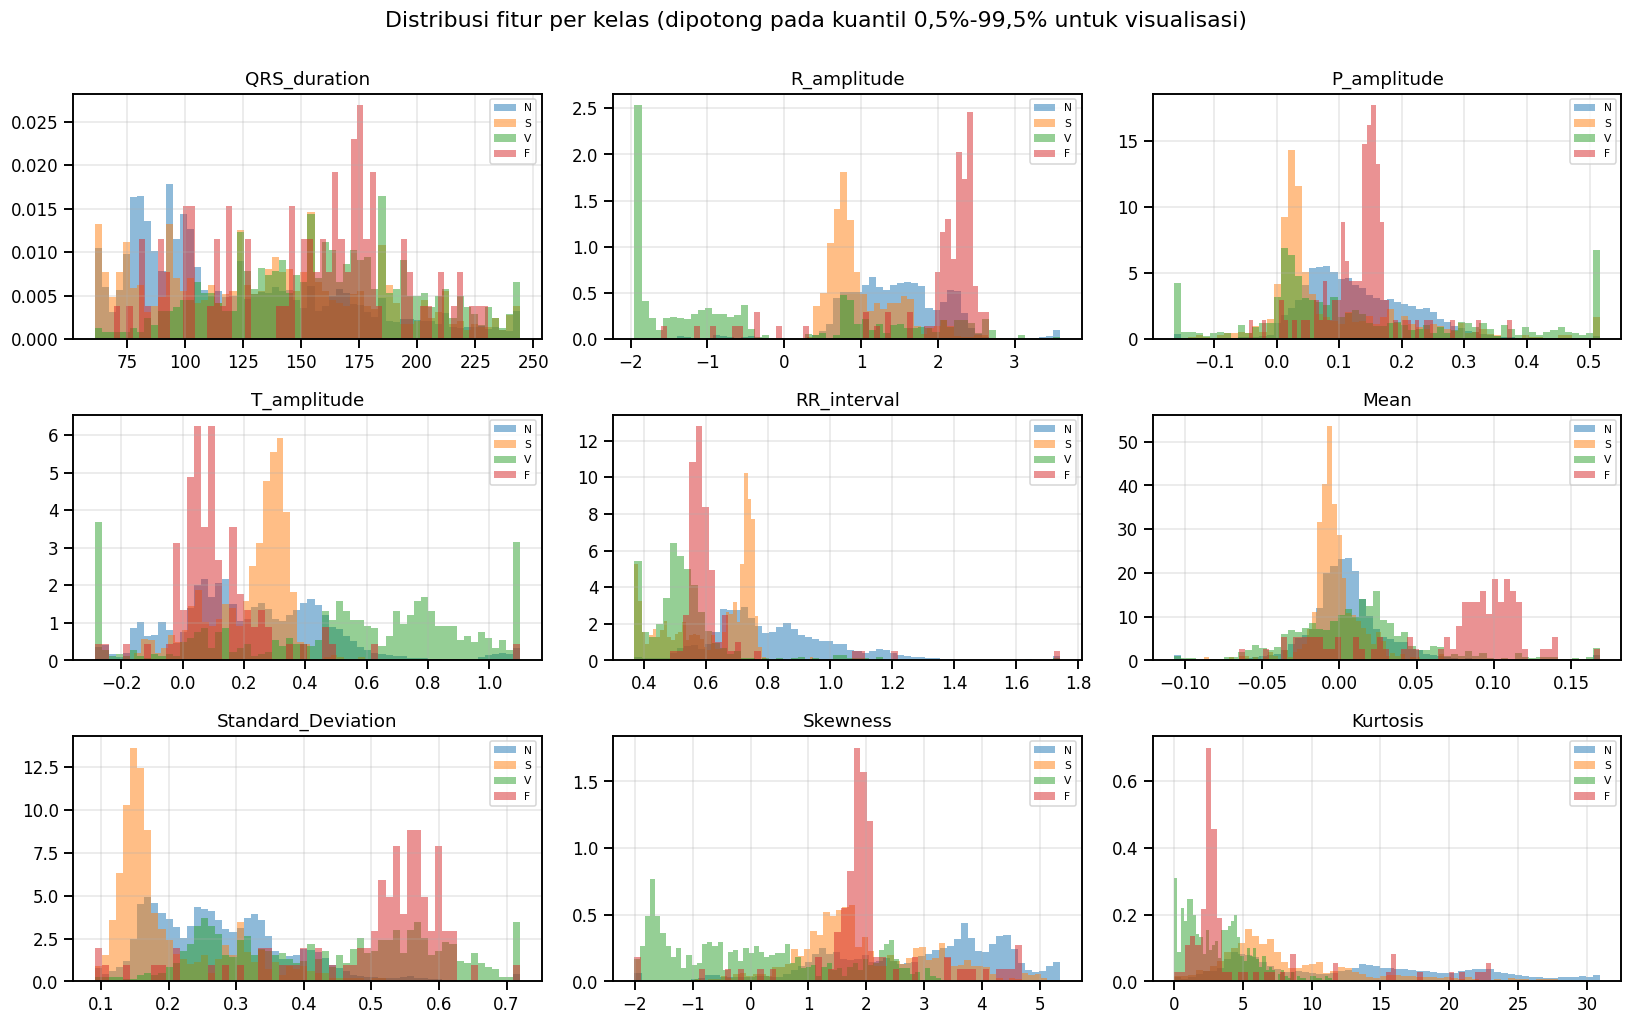

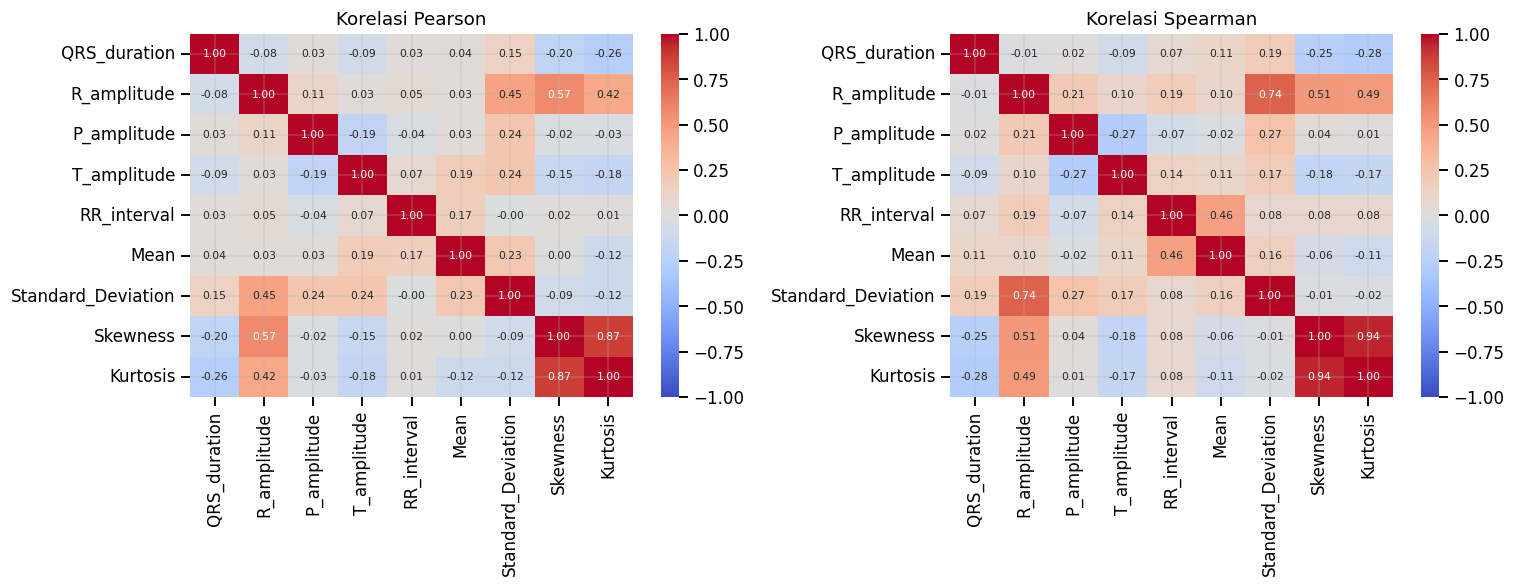

Pasangan fitur berkorelasi tertinggi (|r|):


,fitur_1,fitur_2,|r|
0,Skewness,Kurtosis,0.8687
1,R_amplitude,Skewness,0.5748
2,R_amplitude,Standard_Deviation,0.4550
3,R_amplitude,Kurtosis,0.4238
4,QRS_duration,Kurtosis,0.2598


,QRS_duration,R_amplitude,P_amplitude,T_amplitude,RR_interval,Mean,Standard_Deviation,Skewness,Kurtosis
outlier_IQR_%,0.0000,5.9287,2.1786,3.1444,2.4050,8.3719,2.7515,0.4297,0.0000


Rentang fisiologis yang dicek:
  QRS_duration ms -> 47.2 - 250.0 | RR s -> 0.256 - 100.022
Keputusan: outlier dipertahankan; skala fitur diatur lewat StandardScaler (Bab 10). Jika kurtosis/skewness sangat ekstrem, RobustScaler dapat dicoba sebagai variasi.


In [ ]:
# 8.4 Statistik deskriptif, distribusi, korelasi, dan outlier
display(feat_df[FEATURES].describe().T)
print('Statistik deskriptif per kelas (median):'); display(feat_df.groupby('aami')[FEATURES].median().reindex(CLASS_NAMES))

plot_df = feat_df.sample(n=min(30000, len(feat_df)), random_state=SEED)
n_f = len(FEATURES); ncol = 3; nrow = int(np.ceil(n_f / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.1 * nrow)); axes = axes.ravel()
for ax, f in zip(axes, FEATURES):
    lo, hi = plot_df[f].quantile([0.005, 0.995])
    for c in CLASS_NAMES:
        v = plot_df.loc[plot_df.aami == c, f]
        if len(v) > 5: ax.hist(v.clip(lo, hi), bins=60, alpha=0.5, density=True, label=c)
    ax.set_title(f)
    if ax.get_legend_handles_labels()[0]: ax.legend(fontsize=7)
for ax in axes[n_f:]: ax.axis('off')
plt.suptitle('Distribusi fitur per kelas (dipotong pada kuantil 0,5%-99,5% untuk visualisasi)', y=1.0); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(feat_df[FEATURES].corr(method='pearson'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], annot_kws={'size': 7}); axes[0].set_title('Korelasi Pearson')
sns.heatmap(feat_df[FEATURES].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], annot_kws={'size': 7}); axes[1].set_title('Korelasi Spearman')
plt.tight_layout(); plt.show()
corr_abs = feat_df[FEATURES].corr().abs().to_numpy().copy(); np.fill_diagonal(corr_abs, 0)
pair_list = [(FEATURES[i], FEATURES[j], corr_abs[i, j]) for i in range(len(FEATURES)) for j in range(i + 1, len(FEATURES))]
pairs = pd.DataFrame(pair_list, columns=['fitur_1', 'fitur_2', '|r|']).sort_values('|r|', ascending=False)
print('Pasangan fitur berkorelasi tertinggi (|r|):'); display(pairs.head(5).reset_index(drop=True))

# Outlier: aturan IQR 1,5 (dilaporkan, TIDAK dibuang: nilai ekstrem pada aritmia bisa bermakna klinis)
q1, q3 = feat_df[FEATURES].quantile(0.25), feat_df[FEATURES].quantile(0.75); iqr = q3 - q1
out_pct = ((feat_df[FEATURES] < q1 - 1.5 * iqr) | (feat_df[FEATURES] > q3 + 1.5 * iqr)).mean() * 100
display(out_pct.to_frame('outlier_IQR_%').T)
print('Rentang fisiologis yang dicek:'); print(f'  QRS_duration ms -> {feat_df.QRS_duration.min():.1f} - {feat_df.QRS_duration.max():.1f} | RR s -> {feat_df.RR_interval.min():.3f} - {feat_df.RR_interval.max():.3f}')
print('Keputusan: outlier dipertahankan; skala fitur diatur lewat StandardScaler (Bab 10). Jika kurtosis/skewness sangat ekstrem, RobustScaler dapat dicoba sebagai variasi.')

---
# BAB 9 — PEMBENTUKAN DATASET SEQUENCE

Pendekatan **many-to-one**: `L` beat berturut-turut (default `L = 10`) → label beat **terakhir**. Bentuk input `(jumlah_sequence, L, jumlah_fitur)`.

**Aturan keras yang diterapkan di kode**
- Sequence dibentuk **per record** (tidak melintasi batas record/pasien).
- Urutan mengikuti waktu (`beat_idx`).
- Sebuah sequence sah hanya bila `beat_idx` ke-`L` beat tersebut **berurutan tanpa celah** (`beat_idx` akhir − awal = L−1). Dengan demikian beat yang dibuang (gagal delineasi, beat pertama, dsb.) **tidak** diam-diam "dijahit" menjadi dua beat yang sebenarnya tidak bersebelahan.
- Label = label AAMI beat terakhir; kebenarannya diuji secara eksplisit.

In [ ]:
# 9.1 Fungsi pembentuk sequence (dipakai ulang di Bab 10-15)
def build_sequences(df, feature_cols, seq_len, records=None):
    # df: tabel beat dengan kolom Record, beat_idx, sample, label, dan feature_cols. Mengembalikan X, y, meta.
    X_parts, y_parts, meta_parts = [], [], []
    recs = df.Record.unique() if records is None else records
    for r in recs:
        d = df[df.Record == r].sort_values('beat_idx')
        n = len(d)
        if n < seq_len:
            continue
        F = d[feature_cols].to_numpy(np.float32)
        y = d['label'].to_numpy(np.int64); bi = d.beat_idx.to_numpy(); sm = d['sample'].to_numpy()
        win = sliding_window_view(F, (seq_len, F.shape[1]))[:, 0]               # (n-L+1, L, n_feat)
        contiguous = (bi[seq_len - 1:] - bi[:n - seq_len + 1]) == (seq_len - 1)   # beat_idx berurutan tanpa celah
        X_parts.append(np.ascontiguousarray(win[contiguous]))
        y_parts.append(y[seq_len - 1:][contiguous])
        meta_parts.append(pd.DataFrame({'Record': r, 'end_beat_idx': bi[seq_len - 1:][contiguous], 'end_sample': sm[seq_len - 1:][contiguous]}))
    if not X_parts:
        return np.empty((0, seq_len, len(feature_cols)), np.float32), np.empty((0,), np.int64), pd.DataFrame(columns=['Record', 'end_beat_idx', 'end_sample'])
    return np.concatenate(X_parts), np.concatenate(y_parts), pd.concat(meta_parts, ignore_index=True)

# 9.2 Pembentukan sequence awal (L=10) pada fitur MENTAH (belum diskalakan) untuk pemeriksaan
X_chk, y_chk, meta_chk = build_sequences(feat_df, FEATURES, SEQ_LEN)
print('Bentuk X :', X_chk.shape, '(jumlah_sequence, L, jumlah_fitur)')
print('Bentuk y :', y_chk.shape, '| meta:', meta_chk.shape)
print('Sequence per L (jumlah) :', {L: len(build_sequences(feat_df, FEATURES, L)[1]) for L in (5, 10, 15)})
d_lab = pd.Series(y_chk).map(dict(enumerate(CLASS_NAMES))).value_counts().reindex(CLASS_NAMES).fillna(0).astype(int)
display(pd.DataFrame({'jumlah_sequence': d_lab, 'persen': 100 * d_lab / d_lab.sum()}))
gap_frac = 1 - len(y_chk) / max(1, (feat_df.groupby('Record').size() - (SEQ_LEN - 1)).clip(lower=0).sum())
print(f'Fraksi jendela potensial yang dibuang karena celah beat_idx: {100 * gap_frac:.2f}%')

Bentuk X : (43355, 10, 9) (jumlah_sequence, L, jumlah_fitur)
Bentuk y : (43355,) | meta: (43355, 3)
Sequence per L (jumlah) : {5: 52599, 10: 43355, 15: 37989}


,jumlah_sequence,persen
N,41925,96.7016
S,1061,2.4472
V,349,0.8050
F,18,0.0415
Q,2,0.0046


Fraksi jendela potensial yang dibuang karena celah beat_idx: 40.54%


In [ ]:
# 9.3 Uji kebenaran sequence (data bukan ditebak): urutan waktu, batas record, dan label target
rng_t = np.random.default_rng(SEED)
lookup = {r: g.sort_values('beat_idx').set_index('beat_idx') for r, g in feat_df.groupby('Record')}
n_test = min(500, len(y_chk))
for i in rng_t.choice(len(y_chk), size=n_test, replace=False):
    r, e = meta_chk.loc[i, 'Record'], int(meta_chk.loc[i, 'end_beat_idx'])
    g = lookup[r]
    idx = np.arange(e - SEQ_LEN + 1, e + 1)
    assert np.isin(idx, g.index).all(), f'sequence {i} memuat beat yang tidak ada di record {r}'
    np.testing.assert_allclose(X_chk[i], g.loc[idx, FEATURES].to_numpy(np.float32), rtol=0, atol=0)
    assert y_chk[i] == g.loc[e, 'label'], f'label sequence {i} tidak sama dengan beat terakhir'
    assert (np.diff(g.loc[idx, 'sample'].to_numpy()) > 0).all(), 'urutan waktu salah'
print(f'OK: {n_test} sequence acak lolos uji (isi = beat berurutan dalam satu record, label = beat terakhir).')
print('Sequence yang memuat >1 record: 0 (dibentuk per record; meta.Record konsisten)')
print('Ringkasan: sequence length yang akan dibandingkan di Bab 15 -> 5, 10, 15 (sequence length utama =', SEQ_LEN, ')')
del X_chk

OK: 500 sequence acak lolos uji (isi = beat berurutan dalam satu record, label = beat terakhir).
Sequence yang memuat >1 record: 0 (dibentuk per record; meta.Record konsisten)
Ringkasan: sequence length yang akan dibandingkan di Bab 15 -> 5, 10, 15 (sequence length utama = 10 )


**Pemeriksaan hasil Bab 9.** Pastikan bentuk tensor `(N, 10, jumlah_fitur)`, jumlah sequence masuk akal terhadap jumlah beat final, dan fraksi jendela yang dibuang karena celah tidak besar. Jika fraksi itu besar (lazim pada policy `'drop'` yang membuang banyak beat), sebagian besar kelas minoritas dapat hilang dari sequence — periksa distribusi label di atas sebelum lanjut.

---
# BAB 10 — PEMBAGIAN DATASET (PER PASIEN)

Pembagian dilakukan **per record/pasien**, bukan acak per beat, agar tidak ada kebocoran (*data leakage*) antara beat dari pasien yang sama di training dan testing (beat bertetangga dalam satu pasien sangat mirip).

**Pembagian DS1/DS2 (de Chazal dkk., 2004)** — protokol *inter-patient* yang umum dipakai pada MIT-BIH:
- **DS1** (22 record, dipakai untuk pengembangan): 101, 106, 108, 109, 112, 114, 115, 116, 118, 119, 122, 124, 201, 203, 205, 207, 208, 209, 215, 220, 223, 230
- **DS2** (22 record, dipakai untuk pengujian): 100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210, 212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234
- Record paced (102, 104, 107, 217) dikeluarkan `[K1]`.

**Penyesuaian wajib `[K2]`:** pada DS1/DS2 asli, rekaman **201 ada di DS1 sedangkan 202 di DS2**, padahal keduanya berasal dari subjek yang sama → kebocoran antar-pasien. Di notebook ini 201 dan 202 diperlakukan sebagai **satu kelompok pasien** dan keduanya ditempatkan di kelompok pengembangan (DS1′ = DS1 + 202; DS2′ = DS2 − 202). Konsekuensi: protokol ini **tidak persis sama** dengan DS1/DS2 asli sehingga angka tidak boleh dibandingkan langsung dengan literatur tanpa menyebut penyesuaian ini.

**Validation set** diambil dari kelompok pasien di DS1′ (bukan dari DS2′). Pemilihan kelompok validasi memakai pencarian acak ber-*seed* yang hanya memakai label DS1′ untuk menghasilkan proporsi kelas yang mendekati DS1′ dan memastikan kelas minoritas terwakili — **tanpa melihat test set**. Sisanya menjadi training.

**Standardisasi** (`StandardScaler`) di-*fit* **hanya pada beat training**, lalu diterapkan ke validation dan test.

In [ ]:
# 10.1 Definisi split dan kelompok pasien
DS1 = ['101','106','108','109','112','114','115','116','118','119','122','124','201','203','205','207','208','209','215','220','223','230']
DS2 = ['100','103','105','111','113','117','121','123','200','202','210','212','213','214','219','221','222','228','231','232','233','234']
assert len(DS1) == 22 and len(DS2) == 22 and not set(DS1) & set(DS2)
assert set(RECORDS) <= set(DS1) | set(DS2) | set(PACED_RECORDS), 'Ada record di RECORDS yang tidak ada di DS1/DS2/paced'

DEV_RECORDS = DS1 + ['202']                                    # [K2] 202 dipindah agar sepasien dengan 201
TEST_RECORDS = [r for r in DS2 if r != '202']
if not EXCLUDE_PACED_RECORDS:                                  # bila paced dimasukkan, ditempatkan di kelompok pengembangan [KONFIRMASI]
    DEV_RECORDS += [r for r in PACED_RECORDS if r not in DEV_RECORDS]

PATIENT_GROUPS = [['201', '202']]                              # record yang berasal dari pasien yang sama
group_of = {r: r for r in RECORDS}
for g in PATIENT_GROUPS:
    for r in g: group_of[r] = '+'.join(g)

avail = sorted(feat_df.Record.unique())
unassigned = [r for r in avail if r not in DEV_RECORDS and r not in TEST_RECORDS]
if unassigned:
    raise ValueError(f'Record {unassigned} punya data tetapi tidak masuk DEV maupun TEST. Perbaiki daftar split.')
dev_avail = [r for r in DEV_RECORDS if r in avail]
test_avail = [r for r in TEST_RECORDS if r in avail]
missing_data = [r for r in INCLUDED_RECORDS if r not in avail]
print('Record tanpa beat final (tidak ikut split):', missing_data or 'tidak ada')

# Pemeriksaan: tidak ada kelompok pasien yang terpecah antar bagian
for g in PATIENT_GROUPS:
    sides = {('dev' if r in dev_avail else 'test' if r in test_avail else 'none') for r in g if r in avail}
    assert len(sides) <= 1, f'Kelompok pasien {g} terpecah antar split: {sides}'
print('OK: kelompok pasien 201/202 berada pada sisi yang sama.')

Record tanpa beat final (tidak ikut split): tidak ada
OK: kelompok pasien 201/202 berada pada sisi yang sama.


In [ ]:
# 10.2 Memilih kelompok validasi dari kelompok pengembangan (hanya memakai label DEV; test tidak disentuh)
VAL_N_GROUPS = 4
cls_by_rec = (feat_df[feat_df.Record.isin(dev_avail)].groupby(['Record', 'label']).size()
              .unstack(fill_value=0).reindex(columns=range(N_CLASSES), fill_value=0))
group_counts = cls_by_rec.groupby(lambda r: group_of[r]).sum()
dev_groups = sorted(group_counts.index)
if len(dev_groups) < 2:
    raise ValueError('Kelompok pengembangan < 2 sehingga validation tidak dapat dipisahkan.')
n_val = min(VAL_N_GROUPS, len(dev_groups) - 1)
dev_tot = group_counts.sum()
p_dev = dev_tot / dev_tot.sum()
minor_cls = [c for c in range(1, N_CLASSES) if dev_tot.iloc[c] >= 50]

rng_split = np.random.default_rng(SEED)
best = None
for _ in range(5000):
    sel = list(rng_split.choice(dev_groups, size=n_val, replace=False))
    v = group_counts.loc[sel].sum()
    if v.sum() == 0: continue
    score = float(np.abs(v / v.sum() - p_dev).sum())
    score += sum(1.0 for c in minor_cls if v.iloc[c] < 0.05 * dev_tot.iloc[c])      # kelas minor harus terwakili
    share = v.sum() / dev_tot.sum()
    if not (0.10 <= share <= 0.30): score += 1.0
    if best is None or score < best[0]:
        best = (score, sel)
VAL_GROUPS = sorted(best[1])
val_records = [r for r in dev_avail if group_of[r] in VAL_GROUPS]
train_records = [r for r in dev_avail if group_of[r] not in VAL_GROUPS]
print(f'Skor kelompok validasi terpilih: {best[0]:.3f} | kelompok validasi: {VAL_GROUPS}')

split_of = {**{r: 'train' for r in train_records}, **{r: 'val' for r in val_records}, **{r: 'test' for r in test_avail}}
assert len(split_of) == len(train_records) + len(val_records) + len(test_avail), 'ada record di lebih dari satu split'
assert not (set(train_records) & set(val_records)) and not (set(train_records) & set(test_avail)) and not (set(val_records) & set(test_avail))
feat_df['split'] = feat_df.Record.map(split_of)
assert feat_df.split.notna().all()

rows = []
for s, recs in (('train', train_records), ('val', val_records), ('test', test_avail)):
    sub = feat_df[feat_df.split == s]
    rows.append(dict(split=s, n_records=len(recs), n_beats=len(sub), **{f'beat_{c}': int((sub.aami == c).sum()) for c in CLASS_NAMES}, records=', '.join(recs)))
split_table = pd.DataFrame(rows).set_index('split')
display(split_table)

Skor kelompok validasi terpilih: 0.013 | kelompok validasi: [np.str_('108'), np.str_('114'), np.str_('201+202'), np.str_('205')]


,n_records,n_beats,beat_N,beat_S,beat_V,beat_F,beat_Q,records
split,,,,,,,,
train,18,34666,33005,612,837,208,4,"101, 106, 109, 112, 115, 116, 118, 119, 122, 1..."
val,5,6724,6448,124,137,15,0,"108, 114, 201, 205, 202"
test,21,31915,29393,1539,958,22,3,"100, 103, 105, 111, 113, 117, 121, 123, 200, 2..."


In [ ]:
# 10.3 Standardisasi: fit HANYA pada training, lalu transform semua split
train_mask = feat_df.split == 'train'
scaler = StandardScaler().fit(feat_df.loc[train_mask, FEATURES].to_numpy(float))
assert scaler.n_samples_seen_ == int(train_mask.sum()), 'scaler harus di-fit hanya dengan beat training'

feat_scaled = feat_df.copy()
feat_scaled[FEATURES] = scaler.transform(feat_df[FEATURES].to_numpy(float))
for s in ('train', 'val', 'test'):
    v = feat_scaled.loc[feat_scaled.split == s, FEATURES]
    print(f'{s:5s} | mean rata-rata fitur: {v.mean().mean():+.4f} | std rata-rata fitur: {v.std().mean():.4f}')
print('(train harus ~0 dan ~1; val/test boleh berbeda karena tidak dipakai untuk fit)')
display(pd.DataFrame({'mean_train': scaler.mean_, 'scale_train': scaler.scale_}, index=FEATURES))

SPLIT_META = dict(seed=SEED, ds1=DS1, ds2=DS2, dev_records=dev_avail, test_records=test_avail, train_records=train_records,
                  val_records=val_records, val_groups=VAL_GROUPS, patient_groups=PATIENT_GROUPS,
                  excluded_records=[r for r in RECORDS if r not in INCLUDED_RECORDS], exclude_paced=EXCLUDE_PACED_RECORDS,
                  note='DS1/DS2 de Chazal dimodifikasi: record 202 dipindah ke kelompok pengembangan karena sepasien dengan 201')
print('Metadata split tersusun (disimpan di Bab 16).')

train | mean rata-rata fitur: -0.0000 | std rata-rata fitur: 1.0000
val   | mean rata-rata fitur: -0.0803 | std rata-rata fitur: 0.8941
test  | mean rata-rata fitur: -0.1129 | std rata-rata fitur: 0.9658
(train harus ~0 dan ~1; val/test boleh berbeda karena tidak dipakai untuk fit)


,mean_train,scale_train
QRS_duration,123.2472,39.1264
R_amplitude,1.5959,0.8215
P_amplitude,0.1488,0.1119
T_amplitude,0.2213,0.2577
RR_interval,0.7741,0.5746
Mean,0.0057,0.0363
Standard_Deviation,0.3244,0.1158
Skewness,2.6102,1.5304
Kurtosis,12.3018,7.1660


Metadata split tersusun (disimpan di Bab 16).


---
# BAB 11 — PENANGANAN CLASS IMBALANCE

1. Menampilkan distribusi kelas pada training, validation, dan testing (pada level **sequence**, yaitu satuan yang benar-benar dipakai model).
2. Mengevaluasi tingkat ketidakseimbangan.
3. **Class weight** dihitung **hanya dari training set** (`'balanced'`: `n / (k · n_c)`), sebagai pendekatan awal.
4. Oversampling (opsional, Bab 15): hanya pada training dan dengan **menduplikasi sequence utuh** (urutan temporal di dalam sequence tidak diubah). **SMOTE tidak dipakai** karena interpolasi antar-sequence menghasilkan urutan beat sintetis yang tidak pernah terjadi (merusak struktur temporal dan hubungan RR).
5. Perbandingan dengan/tanpa penanganan imbalance dilakukan di Bab 15 dengan split yang sama.

train X=(21526, 10, 9) y=(21526,) dtype=float32
val   X=(2735, 10, 9) y=(2735,) dtype=float32
test  X=(19094, 10, 9) y=(19094,) dtype=float32


jumlah               persen                
   train   val   test   train     val    test
N  21071  2693  18161 97.8900 98.4600 95.1100
S    345     4    712  1.6000  0.1500  3.7300
V    101    27    221  0.4700  0.9900  1.1600
F      7    11      0  0.0300  0.4000  0.0000
Q      2     0      0  0.0100  0.0000  0.0000

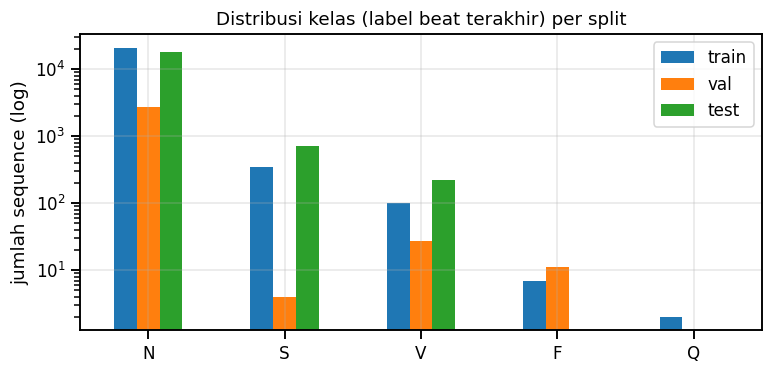

 Split train: kelas dengan <30 sequence -> ['F=7', 'Q=2'] (metrik tidak stabil, tafsirkan hati-hati)
  Split val: kelas TIDAK ADA -> ['Q'] (metrik kelas itu tidak dapat dihitung)
 Split val: kelas dengan <30 sequence -> ['S=4', 'V=27', 'F=11'] (metrik tidak stabil, tafsirkan hati-hati)
  Split test: kelas TIDAK ADA -> ['F', 'Q'] (metrik kelas itu tidak dapat dihitung)
Rasio ketidakseimbangan training (terbesar/terkecil non-nol): 10535.5


In [ ]:
# 11.1 Membentuk sequence per split dari fitur terstandardisasi dan menampilkan distribusi kelas
def make_split_sequences(df, feature_cols, L):
    return {s: build_sequences(df[df.split == s], feature_cols, L) for s in ('train', 'val', 'test')}

SEQS = make_split_sequences(feat_scaled, FEATURES, SEQ_LEN)
for s, (X, y, m) in SEQS.items():
    print(f'{s:5s} X={X.shape} y={y.shape} dtype={X.dtype}')
    assert len(X) > 0, f'Split {s} kosong. Periksa Bab 8 (policy missing) dan Bab 10 (split).'

dist = pd.DataFrame({s: pd.Series(y).value_counts().reindex(range(N_CLASSES)).fillna(0).astype(int) for s, (_, y, _) in SEQS.items()})
dist.index = CLASS_NAMES
dist_pct = (100 * dist / dist.sum()).round(2)
display(pd.concat({'jumlah': dist, 'persen': dist_pct}, axis=1))
fig, ax = plt.subplots(figsize=(8, 3.5))
dist.plot(kind='bar', ax=ax, logy=True); ax.set_ylabel('jumlah sequence (log)'); ax.set_title('Distribusi kelas (label beat terakhir) per split'); plt.xticks(rotation=0); plt.show()

for s in ('train', 'val', 'test'):
    absent = [CLASS_NAMES[c] for c in range(N_CLASSES) if dist.loc[CLASS_NAMES[c], s] == 0]
    tiny = [f'{CLASS_NAMES[c]}={dist.loc[CLASS_NAMES[c], s]}' for c in range(N_CLASSES) if 0 < dist.loc[CLASS_NAMES[c], s] < 30]
    if absent: print(f'  Split {s}: kelas TIDAK ADA -> {absent} (metrik kelas itu tidak dapat dihitung)')
    if tiny: print(f' Split {s}: kelas dengan <30 sequence -> {tiny} (metrik tidak stabil, tafsirkan hati-hati)')
ytr_ = SEQS['train'][1]; cnt = np.bincount(ytr_, minlength=N_CLASSES)
print('Rasio ketidakseimbangan training (terbesar/terkecil non-nol):', round(cnt.max() / cnt[cnt > 0].min(), 1))

In [ ]:
# 11.2 Class weight dari TRAINING saja
def get_class_weights(y, mode='balanced'):
    present = np.unique(y)
    w = compute_class_weight('balanced', classes=present, y=y)
    if mode == 'sqrt': w = np.sqrt(w)
    cw = {c: 1.0 for c in range(N_CLASSES)}                 # kelas yang tidak ada di training: bobot netral (tidak berpengaruh)
    cw.update({int(c): float(v) for c, v in zip(present, w)})
    return cw

CLASS_WEIGHTS = get_class_weights(SEQS['train'][1])
display(pd.DataFrame({'kelas': CLASS_NAMES, 'n_train': np.bincount(SEQS['train'][1], minlength=N_CLASSES),
                      'class_weight': [CLASS_WEIGHTS[c] for c in range(N_CLASSES)]}).set_index('kelas'))

def random_oversample_sequences(X, y, target_ratio=0.25, max_factor=20, seed=SEED):
    # Menduplikasi SEQUENCE UTUH kelas minoritas (tanpa membuat data sintetis) sampai jumlahnya
    # mencapai target_ratio x jumlah kelas mayoritas, dibatasi max_factor x jumlah asli.
    rng = np.random.default_rng(seed)
    cnt = np.bincount(y, minlength=N_CLASSES); major = cnt.max()
    idx = [np.arange(len(y))]
    for c in range(N_CLASSES):
        if 0 < cnt[c] < target_ratio * major:
            n_extra = int(min(target_ratio * major, max_factor * cnt[c]) - cnt[c])
            idx.append(rng.choice(np.where(y == c)[0], size=n_extra, replace=True))
    sel = np.concatenate(idx); rng.shuffle(sel)
    return X[sel], y[sel]

,n_train,class_weight
kelas,,
N,21071,0.2043
S,345,12.4788
V,101,42.6257
F,7,615.0286
Q,2,"2,152.6000"


---
# BAB 12 — PEMBANGUNAN MODEL LSTM

**Arsitektur** (TensorFlow/Keras), input `(L, jumlah_fitur)`:

| Layer | Fungsi |
|---|---|
| `Input(L, F)` | Menerima urutan `L` beat, tiap beat berupa vektor `F` fitur terstandardisasi |
| `LSTM(units)` | Membaca urutan beat dari yang paling lama ke yang paling baru; gerbang *input/forget/output* memungkinkan model menyimpan konteks irama (mis. pola RR sebelumnya). Karena `return_sequences=False`, hanya *hidden state* akhir (ringkasan seluruh urutan) yang diteruskan → konfigurasi **many-to-one** |
| `Dropout` | Regularisasi: mengacak sebagian unit saat training untuk mengurangi overfitting |
| `Dense(dense_units, ReLU)` | Memetakan ringkasan temporal ke representasi yang dapat dipisahkan antar kelas |
| `Dropout` | Regularisasi tambahan |
| `Dense(5, softmax)` | Probabilitas 5 kelas AAMI (jumlah output = `N_CLASSES`) |

**Konfigurasi training:** optimizer **Adam** (learning rate dapat diatur), loss **sparse categorical crossentropy** (label berupa integer), **EarlyStopping** dan **ModelCheckpoint** memantau **macro-F1 validasi** (bukan akurasi, karena data tidak seimbang), dengan `class_weight` dari Bab 11.

**Pemilihan hyperparameter** tidak ditebak: dilakukan *grid search* kecil dengan kriteria **macro-F1 pada validation set**. **Test set tidak dipakai** pada tahap ini. Grid berukuran kecil agar muat di Colab; perluas bila waktu memungkinkan. Catatan: pencarian memakai satu seed sehingga selisih kecil antar konfigurasi bisa merupakan variasi acak.

In [ ]:
# 12.1 Fungsi pembangun model, callback macro-F1, dan fungsi training
def build_lstm(seq_len, n_features, n_classes, units=64, dropout=0.3, dense_units=32, lr=1e-3):
    inp = keras.Input(shape=(seq_len, n_features), name='sequence_input')
    x = layers.LSTM(units, name='lstm')(inp)
    x = layers.Dropout(dropout, name='dropout_1')(x)
    x = layers.Dense(dense_units, activation='relu', name='dense')(x)
    x = layers.Dropout(dropout, name='dropout_2')(x)
    out = layers.Dense(n_classes, activation='softmax', name='softmax_out')(x)
    model = keras.Model(inp, out, name='lstm_aritmia')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def macro_f1_present(y_true, y_pred):
    # macro-F1 hanya atas kelas yang ADA pada y_true (kelas tanpa sampel tidak dihitung sebagai 0)
    return f1_score(y_true, y_pred, labels=np.unique(y_true), average='macro', zero_division=0)

class ValMacroF1(keras.callbacks.Callback):
    def __init__(self, X, y):
        super().__init__(); self.X, self.y = X, y
    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(self.X, batch_size=2048, verbose=0).argmax(axis=1)
        logs['val_macro_f1'] = macro_f1_present(self.y, pred)

def train_model(X_tr, y_tr, X_va, y_va, hp, epochs, patience, class_weight=None, seed=SEED, ckpt_path=None, verbose=0):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    model = build_lstm(X_tr.shape[1], X_tr.shape[2], N_CLASSES, **hp)
    cbs = [ValMacroF1(X_va, y_va),                                   # harus pertama agar val_macro_f1 tersedia bagi callback lain
           keras.callbacks.EarlyStopping(monitor='val_macro_f1', mode='max', patience=patience, restore_best_weights=True)]
    if ckpt_path is not None:
        cbs.append(keras.callbacks.ModelCheckpoint(str(ckpt_path), monitor='val_macro_f1', mode='max', save_best_only=True))
    t0 = time.time()
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=epochs, batch_size=BATCH_SIZE,
                     class_weight=class_weight, callbacks=cbs, verbose=verbose, shuffle=True)
    return model, hist, time.time() - t0

# Uji cepat bentuk keluaran model
_m = build_lstm(SEQ_LEN, len(FEATURES), N_CLASSES)
print('Output shape:', _m.output_shape, '| parameter:', _m.count_params()); del _m

Output shape: (None, 5) | parameter: 21189


In [ ]:
# 12.2 Pencarian hyperparameter (kriteria: macro-F1 validation; TEST TIDAK DIPAKAI)
RUN_TUNING = True
TUNE_EPOCHS, TUNE_PATIENCE = 15, 4
DEFAULT_HP = dict(units=64, dropout=0.3, dense_units=32, lr=1e-3)
HP_GRID = [dict(units=u, dropout=d, dense_units=32, lr=lr) for u in (32, 64, 128) for d in (0.2, 0.4) for lr in (1e-3,)]

Xtr, ytr, mtr = SEQS['train']; Xva, yva, mva = SEQS['val']
if RUN_TUNING:
    tune_rows = []
    for k, hp in enumerate(HP_GRID):
        _, h, secs = train_model(Xtr, ytr, Xva, yva, hp, TUNE_EPOCHS, TUNE_PATIENCE, class_weight=CLASS_WEIGHTS, seed=SEED)
        vmf = h.history['val_macro_f1']; best_ep = int(np.argmax(vmf))
        tune_rows.append(dict(**hp, best_epoch=best_ep + 1, epochs_run=len(vmf), val_macro_f1=vmf[best_ep],
                              val_loss_at_best=h.history['val_loss'][best_ep], val_acc_at_best=h.history['val_accuracy'][best_ep], detik=secs))
        print(f'[{k + 1}/{len(HP_GRID)}] {hp} -> val macro-F1={vmf[best_ep]:.4f} (epoch {best_ep + 1}, {secs:.0f}s)')
    tune_df = pd.DataFrame(tune_rows).sort_values('val_macro_f1', ascending=False).reset_index(drop=True)
    display(tune_df)
    BEST_HP = {k: tune_df.loc[0, k] for k in ('units', 'dropout', 'dense_units', 'lr')}
    BEST_HP['units'] = int(BEST_HP['units']); BEST_HP['dense_units'] = int(BEST_HP['dense_units'])
else:
    BEST_HP = dict(DEFAULT_HP)
print('Konfigurasi terbaik (berdasarkan validation):', BEST_HP)

[1/6] {'units': 32, 'dropout': 0.2, 'dense_units': 32, 'lr': 0.001} -> val macro-F1=0.2389 (epoch 6, 14s)
[2/6] {'units': 32, 'dropout': 0.4, 'dense_units': 32, 'lr': 0.001} -> val macro-F1=0.2321 (epoch 10, 18s)
[3/6] {'units': 64, 'dropout': 0.2, 'dense_units': 32, 'lr': 0.001} -> val macro-F1=0.2600 (epoch 4, 20s)
[4/6] {'units': 64, 'dropout': 0.4, 'dense_units': 32, 'lr': 0.001} -> val macro-F1=0.2496 (epoch 5, 21s)
[5/6] {'units': 128, 'dropout': 0.2, 'dense_units': 32, 'lr': 0.001} -> val macro-F1=0.2677 (epoch 1, 24s)
[6/6] {'units': 128, 'dropout': 0.4, 'dense_units': 32, 'lr': 0.001} -> val macro-F1=0.2701 (epoch 3, 34s)


,units,dropout,dense_units,lr,best_epoch,epochs_run,val_macro_f1,val_loss_at_best,val_acc_at_best,detik
0,128,0.4000,32,0.0010,3,7,0.2701,0.6456,0.8717,33.8627
1,128,0.2000,32,0.0010,1,5,0.2677,0.6658,0.8556,24.2595
2,64,0.2000,32,0.0010,4,8,0.2600,0.5482,0.8640,19.8478
3,64,0.4000,32,0.0010,5,9,0.2496,0.5710,0.9294,21.0200
4,32,0.2000,32,0.0010,6,10,0.2389,0.6437,0.7865,14.2004
5,32,0.4000,32,0.0010,10,14,0.2321,0.7239,0.7572,17.5341


Konfigurasi terbaik (berdasarkan validation): {'units': 128, 'dropout': np.float64(0.4), 'dense_units': 32, 'lr': np.float64(0.001)}


In [ ]:
# 12.3 Ringkasan arsitektur terbaik
tmp_model = build_lstm(SEQ_LEN, len(FEATURES), N_CLASSES, **BEST_HP)
tmp_model.summary()
del tmp_model

Model: "lstm_aritmia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequence_input (InputLayer)     │ (None, 10, 9)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │        70,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_out (Dense)             │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,949 (292.77 KB)

 Trainable params: 74,949 (292.77 KB)

 Non-trainable params: 0 (0.00 B)

---
# BAB 13 — TRAINING DAN VALIDASI

Model dengan konfigurasi terbaik dari Bab 12 dilatih penuh (maks. `MAX_EPOCHS`) dengan *early stopping* dan *checkpoint* berdasarkan macro-F1 validasi. Ditampilkan: loss dan akurasi training/validasi, macro-F1 validasi, jumlah epoch, waktu training, dan epoch terbaik. **Test set tidak dipakai di bab ini.**

Diagnosis overfitting/underfitting di bawah adalah **indikasi heuristik** dari kurva, bukan bukti; periksa kurva secara visual. Perhatikan bahwa akurasi/loss training dihitung dengan *dropout* aktif dan *class weight*, sehingga tidak persis sebanding dengan nilai validasi.

In [ ]:
# 13.1 Training final
CKPT_PATH = OUT_DIR / 'best_lstm.keras'
if CKPT_PATH.exists(): CKPT_PATH.unlink()
model, hist, train_secs = train_model(Xtr, ytr, Xva, yva, BEST_HP, MAX_EPOCHS, PATIENCE, class_weight=CLASS_WEIGHTS,
                                      seed=SEED, ckpt_path=CKPT_PATH, verbose=2)
H = pd.DataFrame(hist.history); H.index = np.arange(1, len(H) + 1); H.index.name = 'epoch'
best_epoch = int(H.val_macro_f1.idxmax())
print(f'\nEpoch dijalankan: {len(H)} | epoch terbaik: {best_epoch} | waktu training: {train_secs:.1f} detik')
display(H.loc[[best_epoch]].rename(index=lambda e: f'epoch terbaik ({e})'))

Epoch 1/60
85/85 - 6s - 68ms/step - accuracy: 0.4227 - loss: 1.5458 - val_accuracy: 0.8428 - val_loss: 0.7705 - val_macro_f1: 0.2631
Epoch 2/60
85/85 - 4s - 50ms/step - accuracy: 0.4881 - loss: 1.4241 - val_accuracy: 0.8548 - val_loss: 0.7840 - val_macro_f1: 0.2572
Epoch 3/60
85/85 - 4s - 48ms/step - accuracy: 0.4997 - loss: 1.1890 - val_accuracy: 0.8717 - val_loss: 0.6456 - val_macro_f1: 0.2701
Epoch 4/60
85/85 - 4s - 41ms/step - accuracy: 0.5235 - loss: 0.9774 - val_accuracy: 0.8212 - val_loss: 0.9128 - val_macro_f1: 0.2382
Epoch 5/60
85/85 - 3s - 39ms/step - accuracy: 0.5402 - loss: 0.8089 - val_accuracy: 0.8603 - val_loss: 0.5565 - val_macro_f1: 0.2348
Epoch 6/60
85/85 - 6s - 67ms/step - accuracy: 0.5375 - loss: 0.8041 - val_accuracy: 0.7898 - val_loss: 0.6896 - val_macro_f1: 0.2273
Epoch 7/60
85/85 - 3s - 39ms/step - accuracy: 0.5171 - loss: 0.8520 - val_accuracy: 0.8055 - val_loss: 0.5631 - val_macro_f1: 0.2301
Epoch 8/60
85/85 - 6s - 69ms/step - accuracy: 0.5778 - loss: 0.6182 -

,accuracy,loss,val_accuracy,val_loss,val_macro_f1
epoch,,,,,
epoch terbaik (3),0.4997,1.1890,0.8717,0.6456,0.2701


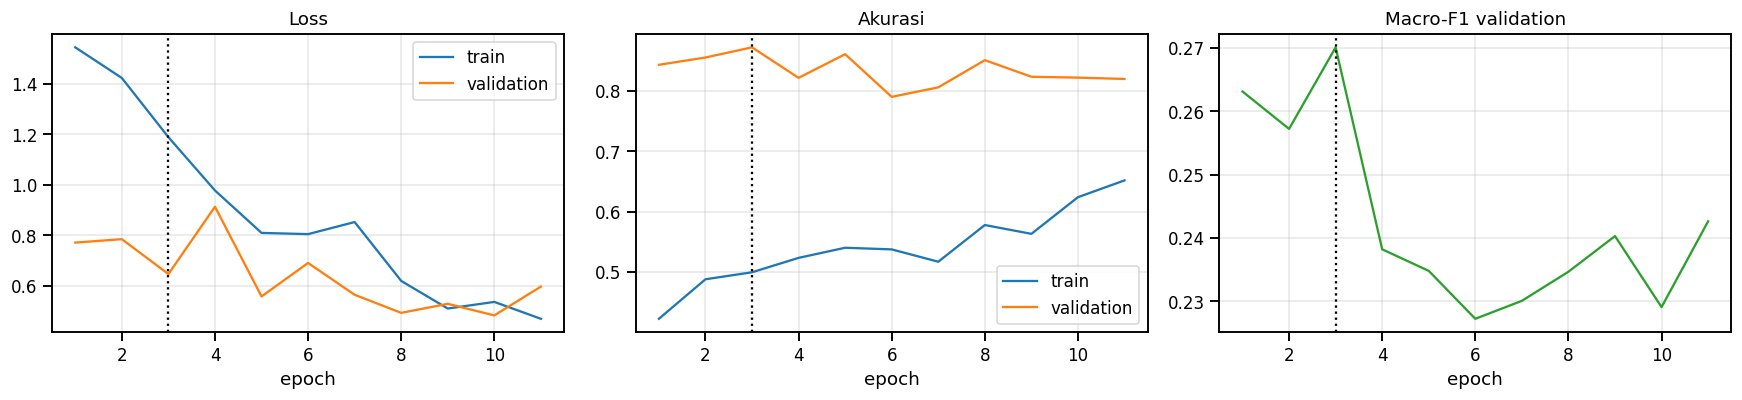

Pada epoch terbaik: train loss=1.1890 | val loss=0.6456 | selisih=-0.5435
                    train acc =0.4997 | val acc =0.8717 | val macro-F1=0.2701
Indikasi overfitting: val loss naik setelah titik terbaik (early stopping + restore best weights mengatasi ini).
Catatan: perbandingan loss train vs val bergantung pada class_weight dan dropout; interpretasikan bersama kurva macro-F1 validation.


In [ ]:
# 13.2 Kurva training dan pemeriksaan overfitting/underfitting
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].plot(H.index, H.loss, label='train'); axes[0].plot(H.index, H.val_loss, label='validation'); axes[0].set_title('Loss'); axes[0].legend()
axes[1].plot(H.index, H.accuracy, label='train'); axes[1].plot(H.index, H.val_accuracy, label='validation'); axes[1].set_title('Akurasi'); axes[1].legend()
axes[2].plot(H.index, H.val_macro_f1, color='tab:green'); axes[2].set_title('Macro-F1 validation')
for ax in axes: ax.axvline(best_epoch, color='k', ls=':'); ax.set_xlabel('epoch')
plt.tight_layout(); plt.show()

b = H.loc[best_epoch]
gap_loss = b.val_loss - b.loss
print(f'Pada epoch terbaik: train loss={b.loss:.4f} | val loss={b.val_loss:.4f} | selisih={gap_loss:+.4f}')
print(f'                    train acc ={b.accuracy:.4f} | val acc ={b.val_accuracy:.4f} | val macro-F1={b.val_macro_f1:.4f}')
if len(H) > best_epoch + 2 and H.val_loss.iloc[-1] > H.val_loss.min() * 1.1:
    print('Indikasi overfitting: val loss naik setelah titik terbaik (early stopping + restore best weights mengatasi ini).')
if b.accuracy < 0.8 and b.val_accuracy < 0.8:
    print('Indikasi underfitting: akurasi training dan validasi sama-sama rendah (pertimbangkan kapasitas model/fitur).')
print('Catatan: perbandingan loss train vs val bergantung pada class_weight dan dropout; interpretasikan bersama kurva macro-F1 validation.')

---
# BAB 14 — EVALUASI MODEL

Evaluasi **satu kali** pada **test set** (record DS2′ yang tidak pernah dipakai untuk fit scaler, class weight, tuning, maupun early stopping). Metrik: accuracy, precision/recall/F1 per kelas, macro dan weighted F1, confusion matrix, classification report. Karena data sangat tidak seimbang, **accuracy tidak boleh dijadikan satu-satunya acuan**; fokus pada recall dan F1 kelas minoritas.

Kelas yang **tidak punya sampel** di test set tidak dihitung dalam macro-F1 dan metriknya ditampilkan `NaN` (bukan 0). Kelas dengan sampel sangat sedikit menghasilkan metrik yang tidak stabil — tabel menandainya. Interval kepercayaan *cluster bootstrap* per record disertakan untuk menunjukkan ketidakpastian akibat sedikitnya pasien.

In [ ]:
# 14.1 Prediksi test set dengan model checkpoint terbaik
best_model = keras.models.load_model(CKPT_PATH)
Xte, yte, mte = SEQS['test']
proba_te = best_model.predict(Xte, batch_size=2048, verbose=0)
ypred_te = proba_te.argmax(axis=1)
print('Test:', Xte.shape, '| distribusi y_true:', dict(zip(CLASS_NAMES, np.bincount(yte, minlength=N_CLASSES).tolist())),
      '| distribusi y_pred:', dict(zip(CLASS_NAMES, np.bincount(ypred_te, minlength=N_CLASSES).tolist())))

present = np.unique(yte)
cm = confusion_matrix(yte, ypred_te, labels=range(N_CLASSES))
support, predicted, tp = cm.sum(axis=1), cm.sum(axis=0), np.diag(cm)
with np.errstate(divide='ignore', invalid='ignore'):
    recall = np.where(support > 0, tp / support, np.nan)
    precision = np.where(predicted > 0, tp / predicted, np.nan)
    f1 = np.where(np.isnan(precision) | np.isnan(recall), np.nan, np.where(precision + recall > 0, 2 * precision * recall / (precision + recall), 0.0))
f1 = np.where(support > 0, f1, np.nan)
report_df = pd.DataFrame({'precision': precision, 'recall': recall, 'f1': f1, 'support': support, 'diprediksi': predicted}, index=CLASS_NAMES)
report_df['catatan'] = np.where(support == 0, 'tidak ada sampel di test', np.where(support < 30, 'support <30: tidak stabil', ''))

summary = {
    'accuracy': accuracy_score(yte, ypred_te),
    'balanced_accuracy': balanced_accuracy_score(yte, ypred_te),
    'macro_precision': precision_recall_fscore_support(yte, ypred_te, labels=present, average='macro', zero_division=0)[0],
    'macro_recall': precision_recall_fscore_support(yte, ypred_te, labels=present, average='macro', zero_division=0)[1],
    'macro_F1 (kelas yang ada)': f1_score(yte, ypred_te, labels=present, average='macro', zero_division=0),
    'weighted_F1': f1_score(yte, ypred_te, labels=present, average='weighted', zero_division=0),
    'weighted_precision': precision_recall_fscore_support(yte, ypred_te, labels=present, average='weighted', zero_division=0)[0],
    'weighted_recall': precision_recall_fscore_support(yte, ypred_te, labels=present, average='weighted', zero_division=0)[1],
    'MCC': matthews_corrcoef(yte, ypred_te), 'Cohen_kappa': cohen_kappa_score(yte, ypred_te)}
display(pd.Series(summary, name='nilai').to_frame())
print('Metrik per kelas:'); display(report_df)
print('Classification report (sklearn; hanya kelas yang ada di test):')
print(classification_report(yte, ypred_te, labels=present, target_names=[CLASS_NAMES[i] for i in present], zero_division=0, digits=4))

Test: (19094, 10, 9) | distribusi y_true: {'N': 18161, 'S': 712, 'V': 221, 'F': 0, 'Q': 0} | distribusi y_pred: {'N': 11290, 'S': 708, 'V': 7014, 'F': 80, 'Q': 2}


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,nilai
accuracy,0.5718
balanced_accuracy,0.4578
macro_precision,0.3337
macro_recall,0.4578
macro_F1 (kelas yang ada),0.2672
weighted_F1,0.6947
weighted_precision,0.9054
weighted_recall,0.5718
MCC,0.0172
Cohen_kappa,0.0087


Metrik per kelas:


,precision,recall,f1,support,diprediksi,catatan
N,0.9506,0.5909,0.7288,18161,11290,
S,0.0268,0.0267,0.0268,712,708,
V,0.0238,0.7557,0.0462,221,7014,
F,0.0000,NaN,NaN,0,80,tidak ada sampel di test
Q,0.0000,NaN,NaN,0,2,tidak ada sampel di test


Classification report (sklearn; hanya kelas yang ada di test):
              precision    recall  f1-score   support

           N     0.9506    0.5909    0.7288     18161
           S     0.0268    0.0267    0.0268       712
           V     0.0238    0.7557    0.0462       221

   micro avg     0.5743    0.5718    0.5730     19094
   macro avg     0.3337    0.4578    0.2672     19094
weighted avg     0.9054    0.5718    0.6947     19094



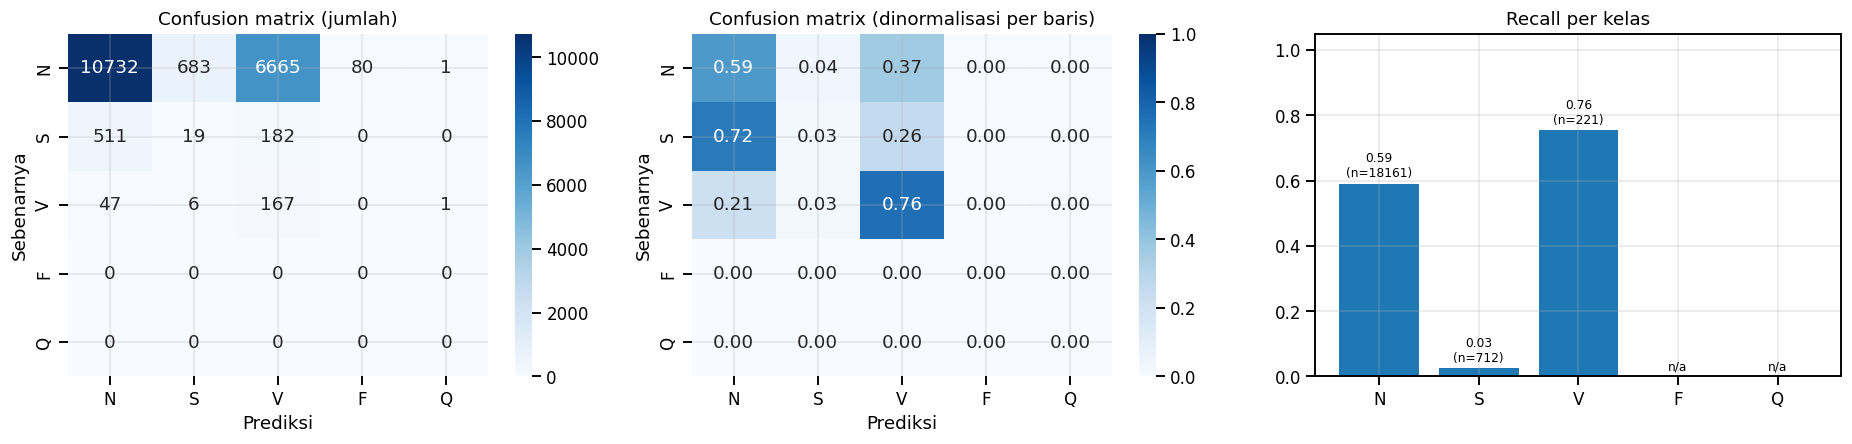

--- Ringkasan otomatis hasil aktual ---
Kelas N: support=18161, recall=0.591, precision=0.951, kesalahan terbanyak -> diprediksi sebagai V (6665 sequence)
Kelas S: support=712, recall=0.027, precision=0.027, kesalahan terbanyak -> diprediksi sebagai N (511 sequence)
Kelas V: support=221, recall=0.756, precision=0.024, kesalahan terbanyak -> diprediksi sebagai N (47 sequence)
Kelas F: tidak ada sampel di test set -> tidak dapat dievaluasi.
Kelas Q: tidak ada sampel di test set -> tidak dapat dievaluasi.
Accuracy=0.5718 vs macro-F1=0.2672: selisih besar menandakan accuracy didominasi kelas N.


In [ ]:
# 14.2 Confusion matrix (jumlah dan proporsi per baris = recall) dan recall per kelas
cm_norm = np.divide(cm, cm.sum(axis=1, keepdims=True), out=np.zeros_like(cm, dtype=float), where=cm.sum(axis=1, keepdims=True) > 0)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0]); axes[0].set_title('Confusion matrix (jumlah)')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1]); axes[1].set_title('Confusion matrix (dinormalisasi per baris)')
for ax in axes[:2]: ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya')
axes[2].bar(CLASS_NAMES, np.nan_to_num(recall)); axes[2].set_ylim(0, 1.05); axes[2].set_title('Recall per kelas')
for i, (r_, s_) in enumerate(zip(recall, support)):
    axes[2].text(i, (0 if np.isnan(r_) else r_) + 0.02, 'n/a' if np.isnan(r_) else f'{r_:.2f}\n(n={s_})', ha='center', fontsize=8)
plt.tight_layout(); plt.show()

# Interpretasi otomatis dari angka AKTUAL (tidak ada angka yang ditulis manual)
print('--- Ringkasan otomatis hasil aktual ---')
for i, c in enumerate(CLASS_NAMES):
    if support[i] == 0:
        print(f'Kelas {c}: tidak ada sampel di test set -> tidak dapat dievaluasi.'); continue
    wrong = cm[i].copy(); wrong[i] = 0
    conf_to = CLASS_NAMES[int(wrong.argmax())] if wrong.sum() > 0 else '-'
    print(f'Kelas {c}: support={support[i]}, recall={recall[i]:.3f}, precision={np.nan_to_num(precision[i]):.3f}, '
          f'kesalahan terbanyak -> diprediksi sebagai {conf_to} ({wrong.max()} sequence)')
print(f"Accuracy={summary['accuracy']:.4f} vs macro-F1={summary['macro_F1 (kelas yang ada)']:.4f}: selisih besar menandakan accuracy didominasi kelas N.")

In [ ]:
# 14.3 Evaluasi per record dan ketidakpastian (cluster bootstrap per record)
rec_rows = []
for r in test_avail:
    mk = (mte.Record == r).to_numpy()
    if mk.sum() == 0: continue
    rec_rows.append(dict(Record=r, n_seq=int(mk.sum()), accuracy=accuracy_score(yte[mk], ypred_te[mk]),
                         **{f'n_{c}': int((yte[mk] == i).sum()) for i, c in enumerate(CLASS_NAMES)},
                         **{f'salah_{c}': int(((yte[mk] == i) & (ypred_te[mk] != i)).sum()) for i, c in enumerate(CLASS_NAMES)}))
display(pd.DataFrame(rec_rows).set_index('Record'))

def cluster_bootstrap_macro_f1(y_true, y_pred, groups, n_boot=500, seed=SEED):
    rng = np.random.default_rng(seed)
    recs = np.unique(groups); idx_by = {r: np.where(groups == r)[0] for r in recs}
    vals = []
    for _ in range(n_boot):
        chosen = rng.choice(recs, size=len(recs), replace=True)
        ii = np.concatenate([idx_by[r] for r in chosen])
        vals.append(macro_f1_present(y_true[ii], y_pred[ii]))
    return np.percentile(vals, [2.5, 50, 97.5])
lo, med, hi = cluster_bootstrap_macro_f1(yte, ypred_te, mte.Record.to_numpy())
print(f'Macro-F1 test = {summary["macro_F1 (kelas yang ada)"]:.4f} | cluster bootstrap 95% CI per record: [{lo:.4f}, {hi:.4f}] (median {med:.4f})')
print('CI lebar = hasil sangat bergantung pada pasien yang kebetulan masuk test; jumlah pasien test kecil.')

,n_seq,accuracy,n_N,n_S,n_V,n_F,n_Q,salah_N,salah_S,salah_V,salah_F,salah_Q
Record,,,,,,,,,,,,
100,1892,0.9863,1866,26,0,0,0,0,26,0,0,0
103,2057,0.9932,2055,2,0,0,0,12,2,0,0,0
105,901,0.8235,891,0,10,0,0,149,0,10,0,0
111,2034,0.0039,2034,0,0,0,0,2026,0,0,0,0
113,1661,0.0000,1656,5,0,0,0,1656,5,0,0,0
117,288,0.0000,287,1,0,0,0,287,1,0,0,0
121,1563,0.9974,1561,1,1,0,0,2,1,1,0,0
123,281,0.8185,281,0,0,0,0,51,0,0,0,0
200,433,0.6721,359,6,68,0,0,121,5,16,0,0


Macro-F1 test = 0.2672 | cluster bootstrap 95% CI per record: [0.1712, 0.3467] (median 0.2679)
CI lebar = hasil sangat bergantung pada pasien yang kebetulan masuk test; jumlah pasien test kecil.


### Interpretasi hasil (diisi peneliti setelah melihat output aktual)

*Sel ini sengaja dikosongkan agar tidak ada klaim sebelum eksperimen dijalankan.* Saat menulis interpretasi, pertimbangkan: (1) recall dan precision kelas S, V, F, Q beserta `support`-nya; (2) pola kesalahan pada confusion matrix (mis. S↔N atau F↔V lazim terjadi); (3) lebar interval bootstrap; (4) dampak kebijakan `MISSING_POLICY` dan penyesuaian split `[K2]`; (5) bahwa hasil ini hanya berlaku untuk protokol inter-patient pada MIT-BIH dan satu pelatihan (satu seed).

---
# BAB 15 — EKSPERIMEN DAN ANALISIS TAMBAHAN

Semua eksperimen memakai **split pasien yang sama** dan **scaler yang sama** (di-fit pada training), konfigurasi hyperparameter `BEST_HP`, dan `class_weight` dari training (kecuali eksperimen yang sengaja menonaktifkannya). Setiap konfigurasi dijalankan dengan beberapa seed (`EXP_SEEDS`) dan dilaporkan sebagai **rata-rata ± simpangan baku**, karena selisih kecil pada satu run tidak dapat dibedakan dari variasi acak.

**Aturan interpretasi**: pemilihan konfigurasi harus berdasarkan **validation**; kolom test hanya untuk pelaporan (jangan memilih konfigurasi dengan melihat test). Peningkatan **tidak diklaim** kecuali melebihi variasi antar-seed dan hasilnya konsisten.

Eksperimen:
1. Panjang sequence **5, 10, 15** (evaluasi pada himpunan beat-akhir yang sama agar adil).
2. **Tanpa vs dengan class weight** (opsional: oversampling sequence utuh).
3. **Ablation fitur**: morfologi saja; RR saja; morfologi + RR; seluruh fitur termasuk statistik.

> **Waktu:** eksperimen ini melatih banyak model. Kurangi `EXP_SEEDS`, `EXP_EPOCHS`, atau matikan eksperimen tertentu bila waktu Colab terbatas.

In [ ]:
# 15.1 Fungsi eksperimen
EXP_SEEDS = [42, 43, 44]
EXP_EPOCHS, EXP_PATIENCE = 40, 6
RUN_SEQLEN_EXP, RUN_WEIGHT_EXP, RUN_ABLATION_EXP, RUN_OVERSAMPLING_EXP = True, True, True, False

def per_class_recall(y, p):
    c = confusion_matrix(y, p, labels=range(N_CLASSES)); s = c.sum(axis=1)
    return np.where(s > 0, np.diag(c) / np.where(s > 0, s, 1), np.nan)

def key_mask(meta, keys):
    # True untuk sequence yang kunci (Record, end_beat_idx)-nya ada di himpunan keys
    mi = pd.MultiIndex.from_frame(meta[['Record', 'end_beat_idx']])
    return np.asarray(mi.isin(list(keys)))

def run_experiment(name, feature_cols, seq_len, use_cw=True, oversample=False, seeds=EXP_SEEDS, common_keys=None):
    seqs = make_split_sequences(feat_scaled, feature_cols, seq_len)
    Xt, yt, _ = seqs['train']; Xv, yv, mv = seqs['val']; Xs, ys, ms = seqs['test']
    cw = get_class_weights(yt) if use_cw else None
    if oversample: Xt, yt = random_oversample_sequences(Xt, yt)
    rows = []
    for sd in seeds:
        mdl, h, secs = train_model(Xt, yt, Xv, yv, BEST_HP, EXP_EPOCHS, EXP_PATIENCE, class_weight=cw, seed=sd)
        res = dict(experiment=name, seed=sd, epochs=len(h.history['loss']), detik=secs)
        for split, (X, y, m) in (('val', (Xv, yv, mv)), ('test', (Xs, ys, ms))):
            if common_keys is not None:
                mk = key_mask(m, common_keys[split]); X, y = X[mk], y[mk]
            p = mdl.predict(X, batch_size=2048, verbose=0).argmax(axis=1)
            res[f'{split}_acc'] = accuracy_score(y, p)
            res[f'{split}_macroF1'] = macro_f1_present(y, p)
            res[f'{split}_weightedF1'] = f1_score(y, p, labels=np.unique(y), average='weighted', zero_division=0)
            for i, c in enumerate(CLASS_NAMES): res[f'{split}_recall_{c}'] = per_class_recall(y, p)[i]
            res[f'{split}_n'] = len(y)
        rows.append(res)
        print(f'  [{name}] seed={sd}: val macro-F1={res["val_macroF1"]:.4f} | test macro-F1={res["test_macroF1"]:.4f} | {secs:.0f}s')
    return pd.DataFrame(rows)

def summarize(results_df, cols=('val_macroF1', 'val_acc', 'test_macroF1', 'test_weightedF1', 'test_acc')):
    g = results_df.groupby('experiment', sort=False)
    out = pd.DataFrame({c: g[c].mean().round(4).astype(str) + ' ± ' + g[c].std(ddof=0).round(4).astype(str) for c in cols})
    out['n_seed'] = g.size(); out['val_n'] = g['val_n'].first(); out['test_n'] = g['test_n'].first()
    return out

def compare_to(results_df, base, metric='val_macroF1'):
    m = results_df.groupby('experiment')[metric].agg(['mean', 'std'])
    for name in m.index:
        if name == base: continue
        d = m.loc[name, 'mean'] - m.loc[base, 'mean']; sd = max(m.loc[name, 'std'], m.loc[base, 'std'], 1e-9)
        verdict = 'melebihi variasi antar-seed' if abs(d) > 2 * sd else 'TIDAK melebihi variasi antar-seed (tidak dapat diklaim)'
        print(f'  {name} vs {base} [{metric}]: selisih rata-rata = {d:+.4f} (simpangan baku maks = {sd:.4f}) -> {verdict}')
print('Fungsi eksperimen siap. Seed:', EXP_SEEDS)

Fungsi eksperimen siap. Seed: [42, 43, 44]


In [ ]:
# 15.2 Eksperimen 1: panjang sequence 5, 10, 15 (evaluasi pada himpunan beat-akhir yang sama = yang tersedia pada L=15)
if RUN_SEQLEN_EXP:
    L_list = [5, 10, 15]
    ref = make_split_sequences(feat_scaled, FEATURES, max(L_list))
    common = {s: set(map(tuple, ref[s][2][['Record', 'end_beat_idx']].to_numpy())) for s in ('val', 'test')}
    parts = []
    for L in L_list:
        print(f'Sequence length L={L}')
        parts.append(run_experiment(f'L={L}', FEATURES, L, use_cw=True, common_keys=common))
    res_seqlen = pd.concat(parts, ignore_index=True)
    display(summarize(res_seqlen)); compare_to(res_seqlen, 'L=10')
    print('Catatan: kolom val_n/test_n = jumlah sequence pada himpunan beat-akhir yang sama untuk semua L.')

Sequence length L=5
  [L=5] seed=42: val macro-F1=0.3059 | test macro-F1=0.3236 | 31s
  [L=5] seed=43: val macro-F1=0.2557 | test macro-F1=0.2747 | 24s
  [L=5] seed=44: val macro-F1=0.2999 | test macro-F1=0.3209 | 33s
Sequence length L=10
  [L=10] seed=42: val macro-F1=0.2629 | test macro-F1=0.2615 | 37s
  [L=10] seed=43: val macro-F1=0.2511 | test macro-F1=0.2592 | 38s
  [L=10] seed=44: val macro-F1=0.2914 | test macro-F1=0.2643 | 36s
Sequence length L=15
  [L=15] seed=42: val macro-F1=0.2493 | test macro-F1=0.2365 | 60s
  [L=15] seed=43: val macro-F1=0.2566 | test macro-F1=0.2643 | 56s
  [L=15] seed=44: val macro-F1=0.3347 | test macro-F1=0.2742 | 109s


,val_macroF1,val_acc,test_macroF1,test_weightedF1,test_acc,n_seed,val_n,test_n
experiment,,,,,,,,
L=5,0.2871 ± 0.0224,0.934 ± 0.0211,0.3064 ± 0.0224,0.8025 ± 0.0448,0.7195 ± 0.0666,3,2294,16554
L=10,0.2684 ± 0.0169,0.8547 ± 0.0308,0.2617 ± 0.0021,0.685 ± 0.0288,0.552 ± 0.0393,3,2294,16554
L=15,0.2802 ± 0.0387,0.8612 ± 0.0132,0.2583 ± 0.016,0.6861 ± 0.0433,0.5519 ± 0.0581,3,2294,16554


  L=15 vs L=10 [val_macroF1]: selisih rata-rata = +0.0117 (simpangan baku maks = 0.0473) -> TIDAK melebihi variasi antar-seed (tidak dapat diklaim)
  L=5 vs L=10 [val_macroF1]: selisih rata-rata = +0.0187 (simpangan baku maks = 0.0274) -> TIDAK melebihi variasi antar-seed (tidak dapat diklaim)
Catatan: kolom val_n/test_n = jumlah sequence pada himpunan beat-akhir yang sama untuk semua L.


In [ ]:
# 15.3 Eksperimen 2: tanpa vs dengan class weight (L=SEQ_LEN, seluruh fitur)
if RUN_WEIGHT_EXP:
    parts = [run_experiment('tanpa class weight', FEATURES, SEQ_LEN, use_cw=False),
             run_experiment('dengan class weight', FEATURES, SEQ_LEN, use_cw=True)]
    if RUN_OVERSAMPLING_EXP:
        parts.append(run_experiment('oversampling sequence (tanpa class weight)', FEATURES, SEQ_LEN, use_cw=False, oversample=True))
    res_weight = pd.concat(parts, ignore_index=True)
    display(summarize(res_weight)); compare_to(res_weight, 'tanpa class weight')
    rc = res_weight.groupby('experiment', sort=False)[[c for c in res_weight if c.startswith('test_recall_')]].mean()
    print('Recall test per kelas (rata-rata antar-seed; NaN = tidak ada sampel):'); display(rc)

  [tanpa class weight] seed=42: val macro-F1=0.4349 | test macro-F1=0.6328 | 161s
  [tanpa class weight] seed=43: val macro-F1=0.3949 | test macro-F1=0.5214 | 67s
  [tanpa class weight] seed=44: val macro-F1=0.3895 | test macro-F1=0.5471 | 97s
  [dengan class weight] seed=42: val macro-F1=0.2701 | test macro-F1=0.2672 | 44s
  [dengan class weight] seed=43: val macro-F1=0.2595 | test macro-F1=0.2628 | 34s
  [dengan class weight] seed=44: val macro-F1=0.2545 | test macro-F1=0.2618 | 29s


,val_macroF1,val_acc,test_macroF1,test_weightedF1,test_acc,n_seed,val_n,test_n
experiment,,,,,,,,
tanpa class weight,0.4064 ± 0.0203,0.9882 ± 0.0002,0.5671 ± 0.0476,0.941 ± 0.0041,0.9559 ± 0.0007,3,2735,19094
dengan class weight,0.2614 ± 0.0065,0.8361 ± 0.0381,0.2639 ± 0.0024,0.6721 ± 0.0328,0.5433 ± 0.0445,3,2735,19094


  dengan class weight vs tanpa class weight [val_macroF1]: selisih rata-rata = -0.1451 (simpangan baku maks = 0.0248) -> melebihi variasi antar-seed
Recall test per kelas (rata-rata antar-seed; NaN = tidak ada sampel):


,test_recall_N,test_recall_S,test_recall_V,test_recall_F,test_recall_Q
experiment,,,,,
tanpa class weight,0.9961,0.0623,0.5249,NaN,NaN
dengan class weight,0.5594,0.0562,0.7964,NaN,NaN


In [ ]:
# 15.4 Eksperimen 3: ablation fitur (split dan scaler sama; hanya kolom fitur yang berbeda)
if RUN_ABLATION_EXP:
    MORPH = [f for f in ['QRS_duration', 'R_amplitude', 'P_amplitude', 'T_amplitude', 'P_missing', 'T_missing'] if f in FEATURES]
    RRF = ['RR_interval']
    ablation_sets = {'Morfologi saja': MORPH, 'RR saja': RRF, 'Morfologi + RR': MORPH + RRF, 'Semua fitur (+statistik)': list(FEATURES)}
    parts = []
    for name, cols in ablation_sets.items():
        print(f'{name}: {cols}')
        parts.append(run_experiment(name, cols, SEQ_LEN, use_cw=True))
    res_ablation = pd.concat(parts, ignore_index=True)
    display(summarize(res_ablation))
    print('Apakah fitur statistik menambah performa? (dasar: Morfologi + RR)'); compare_to(res_ablation, 'Morfologi + RR')
    print('Apakah menambah RR pada morfologi membantu? (dasar: Morfologi saja)'); compare_to(res_ablation, 'Morfologi saja')
    rc = res_ablation.groupby('experiment', sort=False)[[c for c in res_ablation if c.startswith('test_recall_')]].mean()
    print('Recall test per kelas (rata-rata antar-seed):'); display(rc)
    print('Peringatan: Morfologi saja tidak memuat konteks RR sehingga bukan perbandingan "fitur tambahan" murni; pada policy "drop" '
          'ketiga subset memakai beat yang sama (sama-sama sudah lolos delineasi), sehingga perbandingan adil.')

Morfologi saja: ['QRS_duration', 'R_amplitude', 'P_amplitude', 'T_amplitude']
  [Morfologi saja] seed=42: val macro-F1=0.0525 | test macro-F1=0.2374 | 75s
  [Morfologi saja] seed=43: val macro-F1=0.2365 | test macro-F1=0.2820 | 36s
  [Morfologi saja] seed=44: val macro-F1=0.1797 | test macro-F1=0.2059 | 66s
RR saja: ['RR_interval']
  [RR saja] seed=42: val macro-F1=0.1049 | test macro-F1=0.2879 | 35s
  [RR saja] seed=43: val macro-F1=0.1244 | test macro-F1=0.2872 | 32s
  [RR saja] seed=44: val macro-F1=0.1073 | test macro-F1=0.2916 | 32s
Morfologi + RR: ['QRS_duration', 'R_amplitude', 'P_amplitude', 'T_amplitude', 'RR_interval']
  [Morfologi + RR] seed=42: val macro-F1=0.2342 | test macro-F1=0.2443 | 67s
  [Morfologi + RR] seed=43: val macro-F1=0.2350 | test macro-F1=0.2947 | 32s
  [Morfologi + RR] seed=44: val macro-F1=0.2282 | test macro-F1=0.2642 | 70s
Semua fitur (+statistik): ['QRS_duration', 'R_amplitude', 'P_amplitude', 'T_amplitude', 'RR_interval', 'Mean', 'Standard_Deviation',

,val_macroF1,val_acc,test_macroF1,test_weightedF1,test_acc,n_seed,val_n,test_n
experiment,,,,,,,,
Morfologi saja,0.1562 ± 0.0769,0.4578 ± 0.2829,0.2417 ± 0.0312,0.6263 ± 0.0808,0.4922 ± 0.0998,3,2735,19094
RR saja,0.1122 ± 0.0087,0.2849 ± 0.0302,0.2889 ± 0.002,0.779 ± 0.0074,0.6892 ± 0.011,3,2735,19094
Morfologi + RR,0.2325 ± 0.003,0.7683 ± 0.0089,0.2677 ± 0.0207,0.6769 ± 0.0667,0.5471 ± 0.0886,3,2735,19094
Semua fitur (+statistik),0.2614 ± 0.0065,0.8361 ± 0.0381,0.2639 ± 0.0024,0.6721 ± 0.0328,0.5433 ± 0.0445,3,2735,19094


Apakah fitur statistik menambah performa? (dasar: Morfologi + RR)
  Morfologi saja vs Morfologi + RR [val_macroF1]: selisih rata-rata = -0.0762 (simpangan baku maks = 0.0942) -> TIDAK melebihi variasi antar-seed (tidak dapat diklaim)
  RR saja vs Morfologi + RR [val_macroF1]: selisih rata-rata = -0.1203 (simpangan baku maks = 0.0106) -> melebihi variasi antar-seed
  Semua fitur (+statistik) vs Morfologi + RR [val_macroF1]: selisih rata-rata = +0.0289 (simpangan baku maks = 0.0079) -> melebihi variasi antar-seed
Apakah menambah RR pada morfologi membantu? (dasar: Morfologi saja)
  Morfologi + RR vs Morfologi saja [val_macroF1]: selisih rata-rata = +0.0762 (simpangan baku maks = 0.0942) -> TIDAK melebihi variasi antar-seed (tidak dapat diklaim)
  RR saja vs Morfologi saja [val_macroF1]: selisih rata-rata = -0.0440 (simpangan baku maks = 0.0942) -> TIDAK melebihi variasi antar-seed (tidak dapat diklaim)
  Semua fitur (+statistik) vs Morfologi saja [val_macroF1]: selisih rata-rata = +0.105

,test_recall_N,test_recall_S,test_recall_V,test_recall_F,test_recall_Q
experiment,,,,,
Morfologi saja,0.5097,0.0566,0.4555,NaN,NaN
RR saja,0.7182,0.1484,0.0437,NaN,NaN
Morfologi + RR,0.5683,0.0225,0.4977,NaN,NaN
Semua fitur (+statistik),0.5594,0.0562,0.7964,NaN,NaN


Peringatan: Morfologi saja tidak memuat konteks RR sehingga bukan perbandingan "fitur tambahan" murni; pada policy "drop" ketiga subset memakai beat yang sama (sama-sama sudah lolos delineasi), sehingga perbandingan adil.


**Analisis (diisi peneliti)**: Gunakan tabel di atas untuk menilai apakah fitur statistik dan/atau RR *benar-benar* meningkatkan performa dengan memeriksa (a) selisih val macro-F1 terhadap simpangan baku antar-seed, (b) konsistensi pada recall kelas minoritas, bukan hanya akurasi. Tulis hanya kesimpulan yang didukung angka aktual; bila selisih ≲ variasi acak, laporkan "tidak terbukti berbeda".

---
# BAB 16 — KESIMPULAN DAN PENYIMPANAN

Sel berikut mengumpulkan ringkasan **dari variabel aktual** (tidak ada angka manual) lalu menyimpan seluruh artefak penelitian ke `OUT_DIR`.

In [ ]:
# 16.1 Ringkasan otomatis dari hasil aktual
print('=== RINGKASAN PENELITIAN (dihasilkan otomatis dari eksekusi ini) ===\n')
print('Preprocessing: kanal', prep_log.channel.value_counts().to_dict(), f'| bandpass Butterworth orde {FILTER_ORDER} {BAND_HZ[0]}-{BAND_HZ[1]} Hz, sosfiltfilt (zero-phase), fs={FS} Hz')
print(f'Record pemodelan: {len(INCLUDED_RECORDS)} dari {len(RECORDS)} | dikeluarkan: {[r for r in RECORDS if r not in INCLUDED_RECORDS]}')
print(f'Beat anotasi: {int(seg_log.n_beats.sum())} | bersegmen: {int(seg_log.n_segments.sum())} | beat final bertabel fitur ({MISSING_POLICY}): {len(feat_df)}')
print('Distribusi kelas (beat final):', feat_df.aami.value_counts().reindex(CLASS_NAMES).fillna(0).astype(int).to_dict())
print('Retensi per kelas dari funnel (%):', retention.round(1).to_dict())
print('Fitur:', FEATURES)
print('Sequence (train/val/test):', {s: len(SEQS[s][1]) for s in SEQS}, '| L =', SEQ_LEN)
print('Split: train', train_records, '\n       val', val_records, '\n       test', test_avail)
print('Hyperparameter terbaik:', BEST_HP, f'| epoch terbaik: {best_epoch} | waktu training: {train_secs:.0f}s')
print('\nHasil test (satu model, satu seed):'); display(pd.Series(summary).to_frame('nilai'))
print('Detektor R-peak (record pemodelan):', overall(det_df[det_df.modeled]).round(4).to_dict())
lines = []; best_model.summary(print_fn=lambda s: lines.append(s)); ARCH_TEXT = '\n'.join(lines); print('\nArsitektur terbaik:\n' + ARCH_TEXT)

=== RINGKASAN PENELITIAN (dihasilkan otomatis dari eksekusi ini) ===

Preprocessing: kanal {'MLII': 46, 'V5': 2} | bandpass Butterworth orde 4 0.5-40.0 Hz, sosfiltfilt (zero-phase), fs=360 Hz
Record pemodelan: 44 dari 48 | dikeluarkan: ['102', '104', '107', '217']
Beat anotasi: 100733 | bersegmen: 100689 | beat final bertabel fitur (drop): 73305
Distribusi kelas (beat final): {'N': 68846, 'S': 2275, 'V': 1932, 'F': 245, 'Q': 7}
Retensi per kelas dari funnel (%): {'N': 76.4, 'S': 81.8, 'V': 27.6, 'F': 30.5, 'Q': 46.7}
Fitur: ['QRS_duration', 'R_amplitude', 'P_amplitude', 'T_amplitude', 'RR_interval', 'Mean', 'Standard_Deviation', 'Skewness', 'Kurtosis']
Sequence (train/val/test): {'train': 21526, 'val': 2735, 'test': 19094} | L = 10
Split: train ['101', '106', '109', '112', '115', '116', '118', '119', '122', '124', '203', '207', '208', '209', '215', '220', '223', '230'] 
       val ['108', '114', '201', '205', '202'] 
       test ['100', '103', '105', '111', '113', '117', '121', '123', 

,nilai
accuracy,0.5718
balanced_accuracy,0.4578
macro_precision,0.3337
macro_recall,0.4578
macro_F1 (kelas yang ada),0.2672
weighted_F1,0.6947
weighted_precision,0.9054
weighted_recall,0.5718
MCC,0.0172
Cohen_kappa,0.0087


Detektor R-peak (record pemodelan): {'TP': 99971.0, 'FP': 706.0, 'FN': 762.0, 'Sensitivity': 0.9924, 'PPV': 0.993, 'F1': 0.9927}



Arsitektur terbaik:
Model: "lstm_aritmia"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequence_input (InputLayer)     │ (None, 10, 9)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │        70,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├────────────────────────────────

### Keterbatasan penelitian (perlu dilengkapi dengan temuan aktual)
- **Validasi delineasi terbatas**: tidak ada acuan emas onset/offset gelombang di MIT-BIH; plausibilitas dan inspeksi visual tidak menggantikan validasi kuantitatif (mis. QT Database).
- **Bias seleksi dari kebijakan missing** `[K3]`: beat tanpa P/T sah (terutama beat ventrikuler) dapat hilang secara selektif pada policy `'drop'`; periksa funnel Bab 8. Policy `'indicator'` menyimpang dari 9 fitur awal.
- **Kelas sangat jarang** (S, F, Q) terkonsentrasi pada sedikit pasien; metrik per kelas bisa tidak stabil dan CI bootstrap lebar. Kelas Q hampir tidak ada setelah record paced dikeluarkan `[K1]`.
- **Modifikasi DS1/DS2** `[K2]`: angka tidak dapat dibandingkan langsung dengan literatur yang memakai DS1/DS2 asli.
- **Satu basis data, satu kanal (MLII)**: generalisasi ke perangkat/populasi lain belum diuji. Filter 0,5–40 Hz non-kausal dan sedikit meredam puncak QRS.
- **Lokasi beat berasal dari anotasi ahli** `[K5]`: pada penerapan nyata, galat detektor R-peak akan menambah galat klasifikasi.
- **Variasi acak**: tuning memakai satu seed; eksperimen Bab 15 memakai beberapa seed tetapi tetap jumlah pasien test kecil.

### Saran penelitian selanjutnya
Validasi delineasi dengan QT Database; evaluasi *leave-patient-out / cross-validation per pasien*; bandingkan dengan fitur berbasis gelombang mentah (CNN/BiLSTM) dan fitur RR tambahan (RR berikutnya, rata-rata RR lokal); tangani kelas minor dengan *focal loss* atau pengambilan sampel temporal; uji kanal kedua (V1) dan database eksternal (mis. INCART, SVDB); sertakan fitur ketidakhadiran P sebagai indikator eksplisit dan kalibrasi probabilitas.

In [ ]:
# 16.2 Menyimpan seluruh artefak ke OUT_DIR
import hashlib
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Model terbaik (sudah tersimpan oleh ModelCheckpoint) dan salinan bobot
best_model.save(OUT_DIR / 'model_lstm_terbaik.keras')
# Scaler dan pemetaan
joblib.dump(scaler, OUT_DIR / 'scaler_standard.joblib')
json.dump({'features': FEATURES, 'mean': scaler.mean_.tolist(), 'scale': scaler.scale_.tolist()}, open(OUT_DIR / 'scaler_params.json', 'w'), indent=2)
json.dump({'features': FEATURES, 'seq_len': SEQ_LEN, 'missing_policy': MISSING_POLICY}, open(OUT_DIR / 'daftar_fitur.json', 'w'), indent=2)
json.dump({'label_map': LABEL_MAP, 'index_to_class': dict(enumerate(CLASS_NAMES)), 'aami_symbol_map': AAMI_MAP}, open(OUT_DIR / 'label_mapping.json', 'w'), indent=2)
# Prediksi, report, confusion matrix
pred_df = mte.copy(); pred_df['y_true'] = yte; pred_df['y_pred'] = ypred_te
pred_df['true_class'] = pred_df.y_true.map(dict(enumerate(CLASS_NAMES))); pred_df['pred_class'] = pred_df.y_pred.map(dict(enumerate(CLASS_NAMES)))
for i, c in enumerate(CLASS_NAMES): pred_df[f'p_{c}'] = proba_te[:, i]
pred_df.to_csv(OUT_DIR / 'prediksi_test.csv', index=False)
report_df.to_csv(OUT_DIR / 'classification_report.csv')
pd.Series(summary).to_csv(OUT_DIR / 'ringkasan_metrik_test.csv', header=['nilai'])
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUT_DIR / 'confusion_matrix.csv')
fig, ax = plt.subplots(figsize=(5, 4)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya'); fig.tight_layout(); fig.savefig(OUT_DIR / 'confusion_matrix.png', dpi=150); plt.close(fig)
# Dataset fitur (tidak diskalakan) + kolom split, dan metadata split
feat_df.drop(columns=['qrs_ok', 'p_ok', 't_ok']).to_csv(OUT_DIR / 'dataset_fitur.csv', index=False)
funnel.to_csv(OUT_DIR / 'funnel_kehilangan_data.csv')
det_df.to_csv(OUT_DIR / 'evaluasi_rpeak_per_record.csv')
json.dump(SPLIT_META, open(OUT_DIR / 'metadata_split.json', 'w'), indent=2)
H.to_csv(OUT_DIR / 'riwayat_training.csv')
open(OUT_DIR / 'arsitektur_model.txt', 'w').write(ARCH_TEXT)
for nm in ('res_seqlen', 'res_weight', 'res_ablation'):
    if nm in globals(): globals()[nm].to_csv(OUT_DIR / f'eksperimen_{nm}.csv', index=False)
# Info run (reprodusibilitas)
json.dump({'seed': SEED, 'versions': versions, 'config': dict(FS=FS, BAND_HZ=BAND_HZ, FILTER_ORDER=FILTER_ORDER, PRE=PRE, POST=POST, TOL_MS=TOL_MS,
           DELINEATE_METHOD=DELINEATE_METHOD, MISSING_POLICY=MISSING_POLICY, EXCLUDE_PACED_RECORDS=EXCLUDE_PACED_RECORDS, SEQ_LEN=SEQ_LEN,
           BEST_HP=BEST_HP, BATCH_SIZE=BATCH_SIZE, QRS_MIN_MS=QRS_MIN_MS, QRS_MAX_MS=QRS_MAX_MS, P_MAX_BEFORE_R_MS=P_MAX_BEFORE_R_MS,
           T_MAX_AFTER_R_MS=T_MAX_AFTER_R_MS, R_SEARCH_MS=R_SEARCH_MS), 'timestamp': time.strftime('%Y-%m-%d %H:%M:%S')},
          open(OUT_DIR / 'run_info.json', 'w'), indent=2, default=str)

print('Berkas di', OUT_DIR); display(pd.DataFrame([(p.name, p.stat().st_size / 1024) for p in sorted(OUT_DIR.iterdir())], columns=['berkas', 'KB']))
archive = shutil.make_archive(str(BASE_DIR / 'hasil_penelitian_lstm_aritmia'), 'zip', OUT_DIR)
print('ZIP:', archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)

Berkas di /content/output_mitdb


,berkas,KB
0,arsitektur_model.txt,2.5342
1,best_lstm.keras,913.7549
2,classification_report.csv,0.3311
3,confusion_matrix.csv,0.0869
4,confusion_matrix.png,38.8730
5,daftar_fitur.json,0.2275
6,dataset_fitur.csv,"14,492.3916"
7,eksperimen_res_ablation.csv,3.4121
8,eksperimen_res_seqlen.csv,2.6123
9,eksperimen_res_weight.csv,1.8652


ZIP: /content/hasil_penelitian_lstm_aritmia.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Menyimpan notebook final
Notebook yang sudah dieksekusi (beserta seluruh output) disimpan dari menu Colab: **File → Download → Download .ipynb** (atau *Save a copy in Drive*). Simpan juga `hasil_penelitian_lstm_aritmia.zip` yang berisi model, scaler, daftar fitur, pemetaan label, prediksi, classification report, confusion matrix, dataset fitur CSV, dan metadata split.

---
**Penutup metodologis.** Notebook ini tidak menyatakan keberhasilan penelitian. Klaim apa pun harus bersandar pada output aktual setelah seluruh sel berjalan dan diperiksa, dengan memperhatikan keputusan `[K1]–[K7]` di bagian awal.